In [1]:
import os, json, subprocess, tempfile, textwrap, re, hashlib
from pathlib import Path

import pandas as pd
import numpy as np
from tqdm.notebook import tqdm

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import plotly.io as pio
pio.renderers.default = 'png'
pio.renderers['png'].width = 1100
pio.renderers['png'].scale = 2

_CODE_COL   = 'Reference output'
_PROMPT_COL = 'Prompt'
_DIFF_COL   = 'Difficulty'
_INTENT_COL = 'Intent'
_REGO_COL   = 'Rego intent'
_RES_COL    = 'Resource'

OUTPUT_DIR = Path('output/checkov_audit')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('✅ Imports OK')

CACHE_DIR = Path('output/benchmark_security_audit')
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SAVE_EVERY = 5
LINT_CACHE_PATH    = CACHE_DIR / 'lint_cache.csv'
TRIVY_CACHE_PATH   = CACHE_DIR / 'trivy_cache.csv'
CHECKOV_CACHE_PATH = CACHE_DIR / 'checkov_cache.csv'
DEPLOY_CACHE_PATH  = CACHE_DIR / 'deploy_cache.csv'

def scenario_id_for(code: str, prefix: str) -> str:
    return f"{prefix}_{hashlib.md5(code.encode('utf-8')).hexdigest()[:12]}"

_LIST_COLS = {'violations', 'violation_ids', 'violation_names', 'violation_titles', 'cis_violations'}

def _encode_cache_row(row: dict) -> dict:
    out = dict(row)
    for k in _LIST_COLS:
        if k in out and not isinstance(out[k], str):
            out[k] = json.dumps(out[k])
    return out

def _flush_cache(path: Path, batch: list) -> None:
    if not batch:
        return
    df_batch = pd.DataFrame([_encode_cache_row(r) for r in batch])
    has_header = path.exists() and path.stat().st_size > 0
    if has_header:
        existing_cols = pd.read_csv(path, nrows=0).columns
        df_batch = df_batch.reindex(columns=existing_cols)
    df_batch.to_csv(path, mode='a', header=not has_header, index=False)

def resumable_scan(df_src: pd.DataFrame, key_col: str, scan_fn, cache_path: Path, desc: str, save_every: int = None) -> pd.DataFrame:
    save_every = save_every or SAVE_EVERY
    done_ids = set()
    if cache_path.exists():
        done_ids = set(pd.read_csv(cache_path, usecols=[key_col])[key_col])
    todo = df_src[~df_src[key_col].isin(done_ids)].drop_duplicates(subset=key_col)
    print(f"📂 {desc}: {len(done_ids)} cached, {len(todo)} to scan")

    batch = []
    for _, row in tqdm(todo.iterrows(), total=len(todo), desc=desc, unit='template'):
        rec = scan_fn(row)
        rec[key_col] = row[key_col]
        batch.append(rec)
        if len(batch) >= save_every:
            _flush_cache(cache_path, batch)
            batch = []
    _flush_cache(cache_path, batch)

    out = pd.read_csv(cache_path)
    out = out[out[key_col].isin(df_src[key_col])].reset_index(drop=True)
    for k in _LIST_COLS:
        if k in out.columns:
            out[k] = out[k].apply(lambda v: json.loads(v) if isinstance(v, str) else [])
    return out

✅ Imports OK


In [2]:
PARQUET_GLOB = './iac_benchmark/iac_eval_hf/data/train.parquet'
df = pd.read_parquet(PARQUET_GLOB)

if df[_DIFF_COL].dtype == object:
    df[_DIFF_COL] = df[_DIFF_COL].str.extract(r'(\d)').astype(int)

df = df.dropna(subset=[_CODE_COL]).reset_index(drop=True)

df['scenario_id'] = df[_CODE_COL].apply(lambda c: scenario_id_for(str(c), 'iaceval'))
df['source']      = 'autoiac-project/iac-eval'
df['language']    = 'terraform'
n_dupe_content = len(df) - df['scenario_id'].nunique()
if n_dupe_content:
    print(f"  ℹ️  {n_dupe_content} row(s) share byte-identical Reference output with another row "
          f"(same ground truth, different prompt) — the resumable cache below scans each distinct "
          f"template exactly once and broadcasts the result to every row that shares it.")

print(f'Loaded {len(df):,} scenarios  |  columns: {list(df.columns)}')
df.head(5)

  ℹ️  89 row(s) share byte-identical Reference output with another row (same ground truth, different prompt) — the resumable cache below scans each distinct template exactly once and broadcasts the result to every row that shares it.
Loaded 458 scenarios  |  columns: ['Resource', 'Prompt', 'Rego intent', 'Difficulty', 'Reference output', 'Intent', 'scenario_id', 'source', 'language']


,Resource,Prompt,Rego intent,Difficulty,Reference output,Intent,scenario_id,source,language
0,"aws_cloudwatch_log_group, aws_cloudwatch_log_r...",Configure a query log that can create a log st...,package terraform.validation\n\ndefault is_con...,5,terraform {\n required_providers {\n aws =...,"Has one ""aws_route53_zone"" resource\n with ...",iaceval_54f4a6c32e09,autoiac-project/iac-eval,terraform
1,"aws_route53_vpc_association_authorization, aws...",Configure a valid Route 53 zone association re...,package terraform.validation\n\ndefault is_con...,3,"provider ""aws"" {\n region = ""us-east-1""\n}\...","Has multiple ""aws_vpc"" resource\n with a sp...",iaceval_48d9fa4b34e1,autoiac-project/iac-eval,terraform
2,"aws_elb, aws_route53_record, aws_route53_zone",Configure a Route 53 record with an Elastic Lo...,package terraform.validation\n\ndefault is_con...,3,"provider ""aws"" {\n region = ""us-east-1""\n}\n\...","Has one ""aws_route53_zone"" resource\n with ...",iaceval_543fee2dc5c9,autoiac-project/iac-eval,terraform
3,"aws_db_instance, aws_db_instance, aws_db_insta...","Using route 53 resources, configure a weighted...",package terraform.validation\n\ndefault is_con...,6,terraform {\n required_providers {\n aws =...,"Has one ""aws_route53_zone"" resource\n with ...",iaceval_220e90b10e8b,autoiac-project/iac-eval,terraform
4,"aws_db_instance, aws_db_instance, aws_db_subne...",Configure Route 53 to return different databas...,package terraform.validation\n\ndefault is_con...,6,terraform {\n required_providers {\n aws =...,"Has one ""aws_vpc"" resource\n with a specifi...",iaceval_4b8bb5c4398c,autoiac-project/iac-eval,terraform


In [4]:
sample_code = df[_CODE_COL].iloc[0]

with tempfile.TemporaryDirectory() as tmpdir:
    tf_path = Path(tmpdir) / 'main.tf'
    tf_path.write_text(str(sample_code), encoding='utf-8')

    proc = subprocess.run(
        ['checkov', '-f', str(tf_path), '--framework', 'terraform', '-o', 'json', '--quiet', '--compact'],
        capture_output=True, text=True, timeout=60
    )
    print('=== RETURN CODE ===')
    print(proc.returncode)
    print('=== STDOUT (first 3000 chars) ===')
    print(proc.stdout[:3000])
    print('=== STDERR (first 1000 chars) ===')
    print(proc.stderr[:1000])

=== RETURN CODE ===
1
=== STDOUT (first 3000 chars) ===
{
    "check_type": "terraform",
    "results": {
        "failed_checks": [
            {
                "check_id": "CKV_AWS_338",
                "bc_check_id": "BC_AWS_LOGGING_46",
                "check_name": "Ensure CloudWatch log groups retains logs for at least 1 year",
                "check_result": {
                    "result": "FAILED",
                    "evaluated_keys": [
                        "retention_in_days"
                    ]
                },
                "code_block": null,
                "file_path": "/main.tf",
                "file_abs_path": "/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/tmpi5acbt9c/main.tf",
                "repo_file_path": "/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/tmpi5acbt9c/main.tf",
                "file_line_range": [
                    26,
                    29
                ],
                "resource": "aws_cloudwatch_log_group.aws_route53_example

In [5]:
def run_checkov_tf(tf_code: str, timeout: int = 60) -> dict:
    result = {
        'checkov_error':       None,
        'total_checks':        0,
        'passed_checks':       0,
        'failed_checks':       0,
        'policy_pass_rate':    None,
        'filtered_compliance': False,
        'severity_critical':   0,
        'severity_high':       0,
        'severity_medium':     0,
        'severity_low':        0,
        'severity_info':       0,
        'severity_unknown':    0,
        'violations':          [],
        'cis_violations':      [],
        'violation_ids':       [],
        'violation_names':     [],
        'checkov_log':         '',
    }

    with tempfile.TemporaryDirectory() as tmpdir:
        tf_path = Path(tmpdir) / 'main.tf'
        tf_path.write_text(str(tf_code), encoding='utf-8')

        cmd = [
            'checkov',
            '-f', str(tf_path),
            '--framework', 'terraform',
            '-o', 'json',
            '--quiet',
            '--compact',
            '--skip-download',
        ]

        try:
            proc = subprocess.run(
                cmd, capture_output=True, text=True, timeout=timeout
            )
        except subprocess.TimeoutExpired:
            result['checkov_error'] = 'TimeoutExpired'
            return result
        except FileNotFoundError:
            result['checkov_error'] = 'checkov_not_found'
            return result
        except Exception as e:
            result['checkov_error'] = str(e)
            return result

        raw_stdout = proc.stdout
        raw_stderr = proc.stderr
        result['checkov_log'] = raw_stdout[:4000] + raw_stderr[:500]

        raw = None

        try:
            raw = json.loads(raw_stdout)
        except json.JSONDecodeError:
            pass

        if raw is None:
            clean = re.sub(r'\x1b\[[0-9;]*m', '', raw_stdout)
            try:
                raw = json.loads(clean)
            except json.JSONDecodeError:
                pass

        if raw is None:
            for start_char, end_char in [('[', ']'), ('{', '}')]:
                idx = raw_stdout.find(start_char)
                if idx != -1:
                    candidate = raw_stdout[idx:]
                    depth, end_idx = 0, -1
                    for i, ch in enumerate(candidate):
                        if ch == start_char: depth += 1
                        elif ch == end_char:
                            depth -= 1
                            if depth == 0:
                                end_idx = i + 1
                                break
                    if end_idx != -1:
                        try:
                            raw = json.loads(candidate[:end_idx])
                            break
                        except json.JSONDecodeError:
                            pass

        if raw is None:
            result['checkov_error'] = 'json_parse_failed'
            result['checkov_log']   = raw_stdout[:2000] + '\nSTDERR: ' + raw_stderr[:500]
            return result

        if isinstance(raw, list):
            tf_results = [r for r in raw if r.get('check_type') == 'terraform']
            raw = tf_results[0] if tf_results else (raw[0] if raw else {})

        summary = raw.get('summary', {})
        result['passed_checks'] = int(summary.get('passed',  0))
        result['failed_checks'] = int(summary.get('failed',  0))
        result['total_checks']  = result['passed_checks'] + result['failed_checks']

        if result['total_checks'] > 0:
            result['policy_pass_rate'] = round(
                result['passed_checks'] / result['total_checks'], 4
            )
        result['filtered_compliance'] = (
            result['total_checks'] > 0 and result['failed_checks'] == 0
        )
        
        result['checkov_passed'] = result['filtered_compliance']

        _SEV_MAP = {
            'CRITICAL': 'severity_critical', 'HIGH': 'severity_high',
            'MEDIUM':   'severity_medium',    'LOW':  'severity_low',
            'INFO': 'severity_info', 'INFORMATIONAL': 'severity_info',
        }

        for chk in raw.get('results', {}).get('failed_checks', []):
            sev = (chk.get('severity') or 'NONE').upper()
            check_id   = chk.get('check_id',   '')
            check_name = chk.get('check_name', check_id)

            item = {
                'check_id':      check_id,
                'check_name':    check_name,
                'resource':      chk.get('resource', ''),
                'resource_type': chk.get('resource', '').split('.')[0],
                'severity':      sev,
                'guideline':     chk.get('guideline', ''),
                'file_line':     chk.get('file_line_range', []),
            }
            result['violations'].append(item)
            result['violation_ids'].append(check_id)
            result['violation_names'].append(check_name)
            result[_SEV_MAP.get(sev, 'severity_unknown')] += 1

            if re.match(r'CKV_AWS_', check_id):
                result['cis_violations'].append(check_id)

        return result

In [6]:
df_chk = resumable_scan(
    df, 'scenario_id',
    lambda row: run_checkov_tf(str(row[_CODE_COL])),
    CHECKOV_CACHE_PATH, 'Checkov scan',
)
df_chk = df[['scenario_id']].merge(df_chk, on='scenario_id', how='left')

SCALAR_COLS = [
    'checkov_passed', 'checkov_error',
    'total_checks', 'passed_checks', 'failed_checks',
    'policy_pass_rate', 'filtered_compliance',
    'severity_critical', 'severity_high', 'severity_medium', 'severity_low',
    'severity_info', 'severity_unknown',
    'checkov_log',
]

for col in SCALAR_COLS:
    df[col] = df_chk[col]

df['violation_ids']   = df_chk['violation_ids']
df['violation_names'] = df_chk['violation_names']
df['violations_json'] = df_chk['violations'].apply(json.dumps)
df['cis_violations']  = df_chk['cis_violations']

df['swvs'] = (
    df['severity_critical'] * 4 +
    df['severity_high']     * 3 +
    df['severity_medium']   * 2 +
    df['severity_low']      * 1 +
    df['severity_info']     * 0.5
)

print(f"\nCheckov scan complete")
print(f"  Templates scanned          : {len(df):,}")
print(f"  Fully compliant (FCR)      : {df['filtered_compliance'].sum():,}  "
      f"({df['filtered_compliance'].mean()*100:.1f}%)")
print(f"  Mean policy pass rate (PPR): {df['policy_pass_rate'].mean()*100:.1f}%")
print(f"  Total violations found     : {df['failed_checks'].sum():,}")

📂 Checkov scan: 768 cached, 0 to scan


Checkov scan: 0template [00:00, ?template/s]


Checkov scan complete
  Templates scanned          : 458
  Fully compliant (FCR)      : 60  (13.1%)
  Mean policy pass rate (PPR): 59.5%
  Total violations found     : 3,244


In [7]:
SAVE_COLS = list(df.columns)
save_df = df.copy()
for lc in ['violation_ids', 'violation_names', 'cis_violations']:
    save_df[lc] = save_df[lc].apply(json.dumps)

save_df[SAVE_COLS].to_csv(OUTPUT_DIR / 'iac_eval_checkov_results.csv', index=False)
save_df[SAVE_COLS].to_parquet(OUTPUT_DIR / 'iac_eval_checkov_results.parquet', index=False)
print(f'Saved enriched dataset → {OUTPUT_DIR}')
print(save_df.columns)
save_df[['Prompt','Reference output','checkov_passed', 'checkov_error', 'total_checks',
       'passed_checks', 'failed_checks', 'policy_pass_rate',
       'filtered_compliance', 'severity_high', 'severity_medium',
       'severity_low', 'severity_info', 'checkov_log', 'violation_ids',
       'violation_names', 'violations_json', 'cis_violations', 'swvs']].head()

Saved enriched dataset → output/checkov_audit
Index(['Resource', 'Prompt', 'Rego intent', 'Difficulty', 'Reference output',
       'Intent', 'scenario_id', 'source', 'language', 'checkov_passed',
       'checkov_error', 'total_checks', 'passed_checks', 'failed_checks',
       'policy_pass_rate', 'filtered_compliance', 'severity_critical',
       'severity_high', 'severity_medium', 'severity_low', 'severity_info',
       'severity_unknown', 'checkov_log', 'violation_ids', 'violation_names',
       'violations_json', 'cis_violations', 'swvs'],
      dtype='str')


,Prompt,Reference output,checkov_passed,checkov_error,total_checks,passed_checks,failed_checks,policy_pass_rate,filtered_compliance,severity_high,severity_medium,severity_low,severity_info,checkov_log,violation_ids,violation_names,violations_json,cis_violations,swvs
0,Configure a query log that can create a log st...,terraform {\n required_providers {\n aws =...,False,NaN,17,14,3,0.8235,False,0,0,0,0,"{\n ""check_type"": ""terraform"",\n ""result...","[""CKV_AWS_338"", ""CKV_AWS_158"", ""CKV2_AWS_38""]","[""Ensure CloudWatch log groups retains logs fo...","[{""check_id"": ""CKV_AWS_338"", ""check_name"": ""En...","[""CKV_AWS_338"", ""CKV_AWS_158""]",0.0
1,Configure a valid Route 53 zone association re...,"provider ""aws"" {\n region = ""us-east-1""\n}\...",False,NaN,7,3,4,0.4286,False,0,0,0,0,"{\n ""check_type"": ""terraform"",\n ""result...","[""CKV2_AWS_12"", ""CKV2_AWS_12"", ""CKV2_AWS_11"", ...","[""Ensure the default security group of every V...","[{""check_id"": ""CKV2_AWS_12"", ""check_name"": ""En...",[],0.0
2,Configure a Route 53 record with an Elastic Lo...,"provider ""aws"" {\n region = ""us-east-1""\n}\n\...",False,NaN,9,4,5,0.4444,False,0,0,0,0,"{\n ""check_type"": ""terraform"",\n ""result...","[""CKV_AWS_127"", ""CKV_AWS_92"", ""CKV_AWS_376"", ""...","[""Ensure that Elastic Load Balancer(s) uses SS...","[{""check_id"": ""CKV_AWS_127"", ""check_name"": ""En...","[""CKV_AWS_127"", ""CKV_AWS_92"", ""CKV_AWS_376""]",0.0
3,"Using route 53 resources, configure a weighted...",terraform {\n required_providers {\n aws =...,False,NaN,64,28,36,0.4375,False,0,0,0,0,"{\n ""check_type"": ""terraform"",\n ""result...","[""CKV_AWS_161"", ""CKV_AWS_293"", ""CKV_AWS_353"", ...","[""Ensure RDS database has IAM authentication e...","[{""check_id"": ""CKV_AWS_161"", ""check_name"": ""En...","[""CKV_AWS_161"", ""CKV_AWS_293"", ""CKV_AWS_353"", ...",0.0
4,Configure Route 53 to return different databas...,terraform {\n required_providers {\n aws =...,False,NaN,37,16,21,0.4324,False,0,0,0,0,"{\n ""check_type"": ""terraform"",\n ""result...","[""CKV_AWS_161"", ""CKV_AWS_293"", ""CKV_AWS_157"", ...","[""Ensure RDS database has IAM authentication e...","[{""check_id"": ""CKV_AWS_161"", ""check_name"": ""En...","[""CKV_AWS_161"", ""CKV_AWS_293"", ""CKV_AWS_157"", ...",0.0


# Trivy

In [8]:
import shutil, tempfile

sample_code = df[_CODE_COL].iloc[0]
_tmpdir = tempfile.mkdtemp()
try:
    _tf = Path(_tmpdir) / 'main.tf'
    _tf.write_text(str(sample_code), encoding='utf-8')

    _proc = subprocess.run(
        ['trivy', 'config', '--format', 'json', str(_tmpdir)],
        capture_output=True, text=True, timeout=90
    )
    print('=== VERSION ===')
    subprocess.run(['trivy', '--version'], capture_output=False)
    print('\n=== RETURN CODE ===', _proc.returncode)
    print('=== STDOUT ===')
    print(_proc.stdout)
    print('=== STDERR ===')
    print(_proc.stderr[:500])
finally:
    shutil.rmtree(_tmpdir, ignore_errors=True)

=== VERSION ===
Version: 0.69.3
Check Bundle:
  Digest: sha256:1583562f8b90ed2a071b99f0e5ffff6b57e4ceb6ca3e4796577b4e6a339eb74c
  DownloadedAt: 2026-10-11 03:54:28.487352 +0000 UTC

=== RETURN CODE === 0
=== STDOUT ===
{
  "SchemaVersion": 2,
  "Trivy": {
    "Version": "0.69.3"
  },
  "ReportID": "01a12935-c63a-70ee-9441-c7423a168d91",
  "CreatedAt": "2026-10-11T15:25:52.442063+11:00",
  "ArtifactName": "/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/tmpriqh61xt",
  "ArtifactType": "filesystem",
  "Results": [
    {
      "Target": ".",
      "Class": "config",
      "Type": "terraform",
      "MisconfSummary": {
        "Successes": 51,
        "Failures": 0
      }
    },
    {
      "Target": "main.tf",
      "Class": "config",
      "Type": "terraform",
      "MisconfSummary": {
        "Successes": 0,
        "Failures": 1
      },
      "Misconfigurations": [
        {
          "Type": "Terraform Security Check",
          "ID": "AWS-0017",
          "Title": "CloudWatch log 

In [9]:
import requests, re

_TRIVY_CHECKS_API = (
    "https://api.github.com/repos/aquasecurity/trivy-checks/"
    "git/trees/HEAD?recursive=1"
)

def _build_avd_title_map() -> dict[str, str]:
    title_map: dict[str, str] = {}

    resp = requests.get(_TRIVY_CHECKS_API, timeout=30)
    resp.raise_for_status()
    tree = resp.json().get('tree', [])

    rego_paths = [
        item['path'] for item in tree
        if item['path'].startswith('checks/cloud/aws/')
        and item['path'].endswith('.rego')
        and not item['path'].endswith('_test.rego')
        and 'lib/' not in item['path']
    ]

    print(f"  Found {len(rego_paths)} AWS check .rego files — downloading...")

    raw_base = "https://raw.githubusercontent.com/aquasecurity/trivy-checks/HEAD/"

    for path in rego_paths:
        try:
            r = requests.get(raw_base + path, timeout=15)
            r.raise_for_status()
            content = r.text
        except Exception:
            continue

        title_match = re.search(r'^# title:\s*(.+)$', content, re.MULTILINE)
        id_match    = re.search(r'^#\s+id:\s*(AWS-\d+)\s*$', content, re.MULTILINE)

        if not title_match or not id_match:
            continue

        title    = title_match.group(1).strip()
        short_id = id_match.group(1).strip()
        avd_id   = f"AVD-{short_id}"

        title_map[short_id] = title
        title_map[avd_id]   = title

    return title_map


AVD_TITLE_MAP = _build_avd_title_map()
print(f"  Registry built: {len(AVD_TITLE_MAP)} ID → title entries")
print(f"  Example: AWS-0086 → {AVD_TITLE_MAP.get('AWS-0086', 'NOT FOUND')}")
print(f"  Example: AWS-0089 → {AVD_TITLE_MAP.get('AWS-0089', 'NOT FOUND')}")
print(f"  Example: AWS-0087 → {AVD_TITLE_MAP.get('AWS-0087', 'NOT FOUND')}")

  Found 175 AWS check .rego files — downloading...


  Registry built: 350 ID → title entries
  Example: AWS-0086 → S3 Access block should block public ACL
  Example: AWS-0089 → S3 Bucket Logging
  Example: AWS-0087 → S3 Access block should block public policy


In [10]:
TRIVY_OUTPUT_DIR = Path('output/trivy_audit')
TRIVY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

_TRIVY_TF_BASELINE = None
_AWS_RESOURCE_BLOCK_RE = re.compile(r'resource\s+"aws_[a-zA-Z0-9_]+"\s+"')

def _trivy_tf_empty_baseline() -> int:
    global _TRIVY_TF_BASELINE
    if _TRIVY_TF_BASELINE is None:
        with tempfile.TemporaryDirectory() as td:
            (Path(td) / 'main.tf').write_text('# baseline probe, no resources\n', encoding='utf-8')
            proc = subprocess.run(
                ['trivy', 'config', '--format', 'json', '--quiet', '--include-non-failures', td],
                capture_output=True, text=True, timeout=60,
            )
            try:
                data = json.loads(proc.stdout) if proc.stdout.strip() else {}
            except Exception:
                data = {}
            tf_results = [r for r in (data.get('Results') or []) if r.get('Type') == 'terraform']
            _TRIVY_TF_BASELINE = sum(
                r.get('MisconfSummary', {}).get('Successes', 0) + r.get('MisconfSummary', {}).get('Failures', 0)
                for r in tf_results
            )
        print(f"  (Trivy TF empty-file baseline computed: {_TRIVY_TF_BASELINE} checks — recomputed live, not hardcoded)")
    return _TRIVY_TF_BASELINE


_TRIVY_SEV_MAP = {
    'CRITICAL': 'severity_critical',
    'HIGH':     'severity_high',
    'MEDIUM':   'severity_medium',
    'LOW':      'severity_low',
    'UNKNOWN':  'severity_unknown',
}

def run_trivy(tf_code: str, timeout: int = 90) -> dict:
    result = {
        'trivy_passed':       False,
        'trivy_error':        None,
        'total_checks':       0,
        'passed_checks':      0,
        'failed_checks':      0,
        'policy_pass_rate':   None,
        'filtered_compliance': False,
        'severity_critical':  0,
        'severity_high':      0,
        'severity_medium':    0,
        'severity_low':       0,
        'severity_unknown':   0,
        'violations':         [],
        'violation_ids':      [],
        'violation_titles':   [],
        'trivy_log':          '',
    }

    import shutil
    tmpdir = tempfile.mkdtemp()
    try:
        tf_path = Path(tmpdir) / 'main.tf'
        tf_path.write_text(str(tf_code), encoding='utf-8')

        cmd = [
            'trivy', 'config',
            '--format', 'json',
            '--quiet',
            '--include-non-failures',
            '--tf-exclude-downloaded-modules',
            str(tmpdir),
        ]

        try:
            proc = subprocess.run(
                cmd, capture_output=True, text=True, timeout=timeout
            )
        except subprocess.TimeoutExpired:
            result['trivy_error'] = 'TimeoutExpired'
            return result
        except FileNotFoundError:
            result['trivy_error'] = 'trivy_not_found'
            return result
        except Exception as e:
            result['trivy_error'] = str(e)
            return result

        raw_stdout = proc.stdout
        raw_stderr = proc.stderr
        result['trivy_log'] = raw_stdout[:4000] + raw_stderr[:500]

        raw = None
        try:
            raw = json.loads(raw_stdout)
        except json.JSONDecodeError:
            pass

        if raw is None:
            clean = re.sub(r'\x1b\[[0-9;]*m', '', raw_stdout)
            try:
                raw = json.loads(clean)
            except json.JSONDecodeError:
                pass

        if raw is None:
            result['trivy_error'] = 'json_parse_failed'
            result['trivy_log']   = raw_stdout[:2000] + '\nSTDERR: ' + raw_stderr[:500]
            return result

        results_list = raw.get('Results', [])

        _tf_results = [r for r in results_list if r.get('Type') == 'terraform']
        _observed_total = sum(
            r.get('MisconfSummary', {}).get('Successes', 0) + r.get('MisconfSummary', {}).get('Failures', 0)
            for r in _tf_results
        )
        _declares_resources = bool(_AWS_RESOURCE_BLOCK_RE.search(str(tf_code)))
        if not _tf_results:
            result['trivy_error'] = 'not_scanned_by_trivy'
            return result
        if _observed_total <= _trivy_tf_empty_baseline():
            import hcl2, io as _io
            try:
                hcl2.load(_io.StringIO(str(tf_code)))
            except Exception:
                result['trivy_error'] = 'not_scanned_by_trivy'
                return result
        
        file_results = [r for r in results_list if r.get('Target', '') != '.']
        dir_results  = [r for r in results_list if r.get('Target', '') == '.']
        
        use_results = file_results if file_results else dir_results
        
        total_passed = 0
        total_failed = 0

        EXCLUDE_CHECK_IDS = {
            'AWS-0056', 'AWS-0057', 'AWS-0058', 'AWS-0059', 'AWS-0060',
            'AWS-0061', 'AWS-0062', 'AWS-0063', 'AWS-0019', 'AWS-0140',
            'AWS-0141', 'AWS-0143', 'AWS-0123', 'AWS-0345', 'AWS-0346', 'AWS-0342',
        }

        
        AWS_PREFIXES = ('AVD-AWS-', 'AWS-')
        
        for res in use_results:
            all_misconfs = res.get('Misconfigurations', [])
        
            valid_misconfs = [
                m for m in all_misconfs
                if any(m.get('ID', '').startswith(p) for p in AWS_PREFIXES)
                and m.get('ID', '') not in EXCLUDE_CHECK_IDS
                and (m.get('Status') or 'FAIL').upper() == 'FAIL'
            ]
        
            total_failed += len(valid_misconfs)
        
            summary = res.get('MisconfSummary', {})
            total_passed += int(summary.get('Successes', 0))
        
            for m in valid_misconfs:
                sev         = (m.get('Severity') or 'UNKNOWN').upper()
                check_id    = m.get('ID', '')
                check_title = AVD_TITLE_MAP.get(check_id, m.get('Title', check_id))
                resource    = res.get('Target', '')
                resource_type = resource.split('/')[-1] if resource else ''
        
                item = {
                    'check_id':      check_id,
                    'check_title':   check_title,
                    'resource':      resource,
                    'resource_type': resource_type,
                    'severity':      sev,
                    'description':   m.get('Description', ''),
                    'resolution':    m.get('Resolution',  ''),
                    'references':    m.get('References',  []),
                    'status':        m.get('Status', ''),
                }
                result['violations'].append(item)
                result['violation_ids'].append(check_id)
                result['violation_titles'].append(check_title)
                result[_TRIVY_SEV_MAP.get(sev, 'severity_unknown')] += 1
        
        result['failed_checks'] = total_failed
        result['passed_checks'] = total_passed
        result['total_checks']  = total_passed + total_failed


        if result['total_checks'] > 0:
            result['policy_pass_rate'] = round(
                result['passed_checks'] / result['total_checks'], 4
            )
        result['filtered_compliance'] = (
            result['total_checks'] > 0 and result['failed_checks'] == 0
        )
        result['trivy_passed'] = result['filtered_compliance']
        
    finally:
        shutil.rmtree(tmpdir, ignore_errors=True)

    return result

In [11]:
df_trv = resumable_scan(
    df, 'scenario_id',
    lambda row: run_trivy(str(row[_CODE_COL])),
    TRIVY_CACHE_PATH, 'Trivy scan',
)
df_trv = df[['scenario_id']].merge(df_trv, on='scenario_id', how='left')

TRIVY_SCALAR_COLS = [
    'trivy_passed', 'trivy_error',
    'total_checks', 'passed_checks', 'failed_checks',
    'policy_pass_rate', 'filtered_compliance',
    'severity_critical', 'severity_high', 'severity_medium',
    'severity_low', 'severity_unknown',
    'trivy_log',
]

df_trivy = df[[_RES_COL, _DIFF_COL, _CODE_COL, _PROMPT_COL, 'scenario_id']].copy()

for col in TRIVY_SCALAR_COLS:
    df_trivy[col] = df_trv[col]

df_trivy['violation_ids']    = df_trv['violation_ids']
df_trivy['violation_titles'] = df_trv['violation_titles']
df_trivy['violations_json']  = df_trv['violations'].apply(json.dumps)

df_trivy['swvs'] = (
    df_trivy['severity_critical'] * 4 +
    df_trivy['severity_high']     * 3 +
    df_trivy['severity_medium']   * 2 +
    df_trivy['severity_low']      * 1 +
    df_trivy['severity_unknown']  * 0.5
)

df_trivy['policy_pass_rate'] = pd.to_numeric(df_trivy['policy_pass_rate'], errors='coerce')

n_unscanned = (df_trivy['trivy_error'] == 'not_scanned_by_trivy').sum()
print(f"\nTrivy scan complete")
print(f"  Templates scanned          : {len(df_trivy):,}")
print(f"  Not scanned by Trivy       : {n_unscanned:,}  (flagged for audit — see the baseline-comparison fix above)")
print(f"  Fully compliant (FCR)      : {df_trivy['filtered_compliance'].sum():,}  "
      f"({df_trivy['filtered_compliance'].mean()*100:.1f}%)")
print(f"  Mean policy pass rate (PPR): {df_trivy['policy_pass_rate'].mean()*100:.1f}%")
print(f"  Total violations found     : {df_trivy['failed_checks'].sum():,}")

save_trivy = df_trivy.copy()
for lc in ['violation_ids', 'violation_titles']:
    save_trivy[lc] = save_trivy[lc].apply(json.dumps)
save_trivy.to_csv(TRIVY_OUTPUT_DIR / 'iac_eval_trivy_results.csv', index=False)
save_trivy.to_parquet(TRIVY_OUTPUT_DIR / 'iac_eval_trivy_results.parquet', index=False)
print(f"Saved → {TRIVY_OUTPUT_DIR}")
save_trivy.head()

📂 Trivy scan: 0 cached, 369 to scan


Trivy scan:   0%|          | 0/369 [00:00<?, ?template/s]

  (Trivy TF empty-file baseline computed: 51 checks — recomputed live, not hardcoded)



Trivy scan complete
  Templates scanned          : 458
  Not scanned by Trivy       : 0  (flagged for audit — see the baseline-comparison fix above)
  Fully compliant (FCR)      : 131  (28.6%)
  Mean policy pass rate (PPR): 28.8%
  Total violations found     : 2,138
Saved → output/trivy_audit


,Resource,Difficulty,Reference output,Prompt,scenario_id,trivy_passed,trivy_error,total_checks,passed_checks,failed_checks,...,severity_critical,severity_high,severity_medium,severity_low,severity_unknown,trivy_log,violation_ids,violation_titles,violations_json,swvs
0,"aws_cloudwatch_log_group, aws_cloudwatch_log_r...",5,terraform {\n required_providers {\n aws =...,Configure a query log that can create a log st...,iaceval_54f4a6c32e09,False,NaN,1,0,1,...,0,0,0,1,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0017""]","[""CloudWatch log groups should be encrypted us...","[{""check_id"": ""AWS-0017"", ""check_title"": ""Clou...",1.0
1,"aws_route53_vpc_association_authorization, aws...",3,"provider ""aws"" {\n region = ""us-east-1""\n}\...",Configure a valid Route 53 zone association re...,iaceval_48d9fa4b34e1,False,NaN,2,0,2,...,0,0,2,0,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0178"", ""AWS-0178""]","[""VPC Flow Logs is a feature that enables you ...","[{""check_id"": ""AWS-0178"", ""check_title"": ""VPC ...",4.0
2,"aws_elb, aws_route53_record, aws_route53_zone",3,"provider ""aws"" {\n region = ""us-east-1""\n}\n\...",Configure a Route 53 record with an Elastic Lo...,iaceval_543fee2dc5c9,False,NaN,1,0,1,...,0,1,0,0,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0053""]","[""Load balancer is exposed to the internet.""]","[{""check_id"": ""AWS-0053"", ""check_title"": ""Load...",3.0
3,"aws_db_instance, aws_db_instance, aws_db_insta...",6,terraform {\n required_providers {\n aws =...,"Using route 53 resources, configure a weighted...",iaceval_220e90b10e8b,False,NaN,10,0,10,...,0,1,5,4,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0080"", ""AWS-0133"", ""AWS-0133"", ""AWS-0133...","[""RDS encryption has not been enabled at a DB ...","[{""check_id"": ""AWS-0080"", ""check_title"": ""RDS ...",17.0
4,"aws_db_instance, aws_db_instance, aws_db_subne...",6,terraform {\n required_providers {\n aws =...,Configure Route 53 to return different databas...,iaceval_4b8bb5c4398c,False,NaN,12,0,12,...,0,3,7,2,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0077"", ""AWS-0077"", ""AWS-0080"", ""AWS-0080...","[""RDS Cluster and RDS instance should have bac...","[{""check_id"": ""AWS-0077"", ""check_title"": ""RDS ...",25.0


In [12]:
print(save_trivy.columns)
save_trivy[['Resource', 'Difficulty', 'Reference output', 'trivy_passed',
       'trivy_error', 'total_checks', 'passed_checks', 'failed_checks',
       'policy_pass_rate', 'filtered_compliance', 'severity_critical',
       'severity_high', 'severity_medium', 'severity_low', 'severity_unknown',
       'trivy_log', 'violation_ids', 'violation_titles', 'violations_json',
       'swvs']].head()

Index(['Resource', 'Difficulty', 'Reference output', 'Prompt', 'scenario_id',
       'trivy_passed', 'trivy_error', 'total_checks', 'passed_checks',
       'failed_checks', 'policy_pass_rate', 'filtered_compliance',
       'severity_critical', 'severity_high', 'severity_medium', 'severity_low',
       'severity_unknown', 'trivy_log', 'violation_ids', 'violation_titles',
       'violations_json', 'swvs'],
      dtype='str')


,Resource,Difficulty,Reference output,trivy_passed,trivy_error,total_checks,passed_checks,failed_checks,policy_pass_rate,filtered_compliance,severity_critical,severity_high,severity_medium,severity_low,severity_unknown,trivy_log,violation_ids,violation_titles,violations_json,swvs
0,"aws_cloudwatch_log_group, aws_cloudwatch_log_r...",5,terraform {\n required_providers {\n aws =...,False,NaN,1,0,1,0.0,False,0,0,0,1,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0017""]","[""CloudWatch log groups should be encrypted us...","[{""check_id"": ""AWS-0017"", ""check_title"": ""Clou...",1.0
1,"aws_route53_vpc_association_authorization, aws...",3,"provider ""aws"" {\n region = ""us-east-1""\n}\...",False,NaN,2,0,2,0.0,False,0,0,2,0,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0178"", ""AWS-0178""]","[""VPC Flow Logs is a feature that enables you ...","[{""check_id"": ""AWS-0178"", ""check_title"": ""VPC ...",4.0
2,"aws_elb, aws_route53_record, aws_route53_zone",3,"provider ""aws"" {\n region = ""us-east-1""\n}\n\...",False,NaN,1,0,1,0.0,False,0,1,0,0,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0053""]","[""Load balancer is exposed to the internet.""]","[{""check_id"": ""AWS-0053"", ""check_title"": ""Load...",3.0
3,"aws_db_instance, aws_db_instance, aws_db_insta...",6,terraform {\n required_providers {\n aws =...,False,NaN,10,0,10,0.0,False,0,1,5,4,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0080"", ""AWS-0133"", ""AWS-0133"", ""AWS-0133...","[""RDS encryption has not been enabled at a DB ...","[{""check_id"": ""AWS-0080"", ""check_title"": ""RDS ...",17.0
4,"aws_db_instance, aws_db_instance, aws_db_subne...",6,terraform {\n required_providers {\n aws =...,False,NaN,12,0,12,0.0,False,0,3,7,2,0,"{\n ""SchemaVersion"": 2,\n ""Trivy"": {\n ""V...","[""AWS-0077"", ""AWS-0077"", ""AWS-0080"", ""AWS-0080...","[""RDS Cluster and RDS instance should have bac...","[{""check_id"": ""AWS-0077"", ""check_title"": ""RDS ...",25.0


# TFLint

In [13]:
_tf_tool_env = os.environ.copy()
_tf_tool_env['PATH'] = f"/opt/homebrew/bin:{_tf_tool_env.get('PATH', '')}"

TFLINT_INIT_TIMEOUT = 120
TFLINT_RUN_TIMEOUT  = 60

def run_tflint_code(code: str) -> dict:
    result = dict(lint_pass=None, lint_errors=-1, lint_warnings=0, lint_info=0,
                  lint_error_codes='', lint_error_msg='', lint_tool_error=None)
    with tempfile.TemporaryDirectory() as tmpdir:
        (Path(tmpdir) / 'main.tf').write_text(code, encoding='utf-8')
        try:
            subprocess.run(['tflint', '--init', '--no-color'], cwd=tmpdir,
                            capture_output=True, timeout=TFLINT_INIT_TIMEOUT, env=_tf_tool_env)
            lint_result = subprocess.run(
                ['tflint', '--format', 'json', '--no-color'], cwd=tmpdir,
                capture_output=True, text=True, timeout=TFLINT_RUN_TIMEOUT, env=_tf_tool_env,
            )
        except subprocess.TimeoutExpired:
            result['lint_tool_error'] = 'TimeoutExpired'
            return result
        except FileNotFoundError:
            result['lint_tool_error'] = 'tflint_not_found'
            return result
        except Exception as e:
            result['lint_tool_error'] = str(e)
            return result

        raw_out = lint_result.stdout or lint_result.stderr
        try:
            data = json.loads(raw_out)
        except json.JSONDecodeError:
            result['lint_pass'] = (lint_result.returncode == 0)
            result['lint_tool_error'] = 'non_json_output'
            return result

        errors, warnings, infos, codes, first_msg = [], [], [], set(), ''
        for issue in data.get('issues', []):
            rule = issue.get('rule', {})
            sev = (rule.get('severity') or 'error').lower()
            if sev == 'error':
                errors.append(issue)
                codes.add(rule.get('name', '?'))
                if not first_msg:
                    first_msg = str(issue.get('message', ''))[:300]
            elif sev == 'warning':
                warnings.append(issue)
            else:
                infos.append(issue)

        result['lint_pass']        = len(errors) == 0
        result['lint_errors']      = len(errors)
        result['lint_warnings']    = len(warnings)
        result['lint_info']        = len(infos)
        result['lint_error_codes'] = ' | '.join(sorted(codes))
        result['lint_error_msg']   = first_msg
        return result

_sample_lint = run_tflint_code(str(df[_CODE_COL].iloc[0]))
print(f"Sample TFLint result: pass={_sample_lint['lint_pass']}, errors={_sample_lint['lint_errors']}, "
      f"warnings={_sample_lint['lint_warnings']}")

Sample TFLint result: pass=True, errors=0, warnings=0


In [14]:
df_lint_ie = resumable_scan(
    df, 'scenario_id',
    lambda row: run_tflint_code(str(row[_CODE_COL])),
    LINT_CACHE_PATH, 'TFLint scan (IaC-Eval)',
)
df_lint_ie = df[['scenario_id']].merge(df_lint_ie, on='scenario_id', how='left')

n_tool_err = df_lint_ie['lint_tool_error'].notna().sum()
print(f"\nTFLint scan complete (IaC-Eval)")
print(f"  Scenarios scanned : {len(df_lint_ie):,}")
print(f"  Lint pass         : {int(pd.to_numeric(df_lint_ie['lint_pass'], errors='coerce').fillna(0).sum()):,}  "
      f"({pd.to_numeric(df_lint_ie['lint_pass'], errors='coerce').mean()*100:.1f}%)")
print(f"  Tool errors       : {n_tool_err:,}")
df_lint_ie[['scenario_id','lint_pass','lint_errors','lint_error_codes']].head(10)

📂 TFLint scan (IaC-Eval): 768 cached, 0 to scan


TFLint scan (IaC-Eval): 0template [00:00, ?template/s]


TFLint scan complete (IaC-Eval)
  Scenarios scanned : 458
  Lint pass         : 458  (100.0%)
  Tool errors       : 0


,scenario_id,lint_pass,lint_errors,lint_error_codes
0,iaceval_54f4a6c32e09,True,0,NaN
1,iaceval_48d9fa4b34e1,True,0,NaN
2,iaceval_543fee2dc5c9,True,0,NaN
3,iaceval_220e90b10e8b,True,0,NaN
4,iaceval_4b8bb5c4398c,True,0,NaN
5,iaceval_4b703621d9c1,True,0,NaN
6,iaceval_31353e169a0b,True,0,NaN
7,iaceval_476902f06a51,True,0,NaN
8,iaceval_77e561a89b31,True,0,NaN
9,iaceval_9f40b81e9da7,True,0,NaN


# Multi-IaC-Eval (CloudFormation + Terraform)

In [15]:
from datasets import load_dataset

MULTI_IAC_EVAL_SOURCE  = 'AmazonScience/Multi-IaC-Eval'
MULTI_IAC_EVAL_CACHE   = CACHE_DIR / 'multi_iac_eval_raw.json'
MULTI_IAC_EVAL_LICENCE = 'CC-BY-NC-4.0'

if MULTI_IAC_EVAL_CACHE.exists():
    df_multi_raw = pd.read_json(MULTI_IAC_EVAL_CACHE)
    print(f"Loaded {len(df_multi_raw):,} Multi-IaC-Eval rows from local cache ({MULTI_IAC_EVAL_CACHE})")
else:
    try:
        ds_multi = load_dataset(MULTI_IAC_EVAL_SOURCE, split='test')
    except Exception:
        ds_multi = load_dataset(MULTI_IAC_EVAL_SOURCE, split='test', download_mode='force_redownload')
    df_multi_raw = ds_multi.to_pandas()
    df_multi_raw.to_json(MULTI_IAC_EVAL_CACHE, orient='records')
    print(f"Fetched {len(df_multi_raw):,} Multi-IaC-Eval rows from HuggingFace, cached → {MULTI_IAC_EVAL_CACHE}")

print(f"columns: {list(df_multi_raw.columns)}")
print(df_multi_raw['type'].value_counts())

_multi_cfn_raw = df_multi_raw[df_multi_raw['type'].astype(str).str.lower() == 'cloudformation'].copy()
_multi_tf_raw  = df_multi_raw[df_multi_raw['type'].fillna('').astype(str).str.lower().str.contains('terraform')].copy()

df_multi_cfn = pd.DataFrame({
    'scenario_id':   _multi_cfn_raw['expected'].astype(str).apply(lambda c: scenario_id_for(c, 'multiiaceval_cfn')),
    'source':        MULTI_IAC_EVAL_SOURCE,
    'language':      'cloudformation',
    'code':          _multi_cfn_raw['expected'].astype(str),
    'prompt':        pd.NA,
    'difficulty':    pd.NA,
    'resource_hint': pd.NA,
}).drop_duplicates(subset='scenario_id').reset_index(drop=True)

df_multi_tf = pd.DataFrame({
    'scenario_id':   _multi_tf_raw['expected'].astype(str).apply(lambda c: scenario_id_for(c, 'multiiaceval_tf')),
    'source':        MULTI_IAC_EVAL_SOURCE,
    'language':      'terraform',
    'code':          _multi_tf_raw['expected'].astype(str),
    'prompt':        pd.NA,
    'difficulty':    pd.NA,
    'resource_hint': pd.NA,
}).drop_duplicates(subset='scenario_id').reset_index(drop=True)

print(f"\nMulti-IaC-Eval CFN subset : {len(df_multi_cfn):,} distinct scenarios (from {len(_multi_cfn_raw):,} raw rows)")
print(f"Multi-IaC-Eval TF  subset : {len(df_multi_tf):,} distinct scenarios (from {len(_multi_tf_raw):,} raw rows)")

Loaded 709 Multi-IaC-Eval rows from local cache (output/benchmark_security_audit/multi_iac_eval_raw.json)
columns: ['source', 'initial', 'expected', 'utterance', 'source_repo', 'type']
type
terraform         446
cloudformation    263
Name: count, dtype: int64

Multi-IaC-Eval CFN subset : 176 distinct scenarios (from 263 raw rows)
Multi-IaC-Eval TF  subset : 223 distinct scenarios (from 446 raw rows)


In [16]:
def sniff_cfn_ext(content: str) -> str:
    return '.json' if content.lstrip().startswith('{') else '.yaml'

CFNLINT_TIMEOUT_MULTI = 60

def run_cfnlint_code(code: str, ext: str) -> dict:
    result = dict(lint_pass=None, lint_errors=-1, lint_warnings=0, lint_info=0,
                  lint_error_codes='', lint_error_msg='', lint_tool_error=None)
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(code)
        tmp_path = f.name
    try:
        proc = subprocess.run(['cfn-lint', '--format', 'json', tmp_path],
                               capture_output=True, text=True, timeout=CFNLINT_TIMEOUT_MULTI)
    except subprocess.TimeoutExpired:
        result['lint_tool_error'] = 'TimeoutExpired'; return result
    except FileNotFoundError:
        result['lint_tool_error'] = 'cfn-lint_not_found'; return result
    except Exception as e:
        result['lint_tool_error'] = str(e); return result
    finally:
        Path(tmp_path).unlink(missing_ok=True)

    try:
        matches = json.loads(proc.stdout) if proc.stdout.strip() else []
    except json.JSONDecodeError:
        result['lint_tool_error'] = f'json_parse_failed: {proc.stdout[:200]}'
        return result

    errors   = [m for m in matches if m.get('Level') == 'Error']
    warnings = [m for m in matches if m.get('Level') == 'Warning']
    infos    = [m for m in matches if m.get('Level') == 'Informational']
    result['lint_pass']        = len(errors) == 0
    result['lint_errors']      = len(errors)
    result['lint_warnings']    = len(warnings)
    result['lint_info']        = len(infos)
    result['lint_error_codes'] = ' | '.join(sorted({m.get('Rule', {}).get('Id', '') for m in errors}))
    result['lint_error_msg']   = str(errors[0].get('Message', ''))[:300] if errors else ''
    return result

_sample_cfn_lint = run_cfnlint_code(str(df_multi_cfn['code'].iloc[0]), sniff_cfn_ext(str(df_multi_cfn['code'].iloc[0])))
print(f"Sample cfn-lint result: pass={_sample_cfn_lint['lint_pass']}, errors={_sample_cfn_lint['lint_errors']}")

Sample cfn-lint result: pass=False, errors=2


In [17]:
TRIVY_CFN_SUFFIXES = {'.yaml', '.yml', '.json'}
_AWS_PREFIXES_CFN = ('AVD-AWS-', 'AWS-')
EXCLUDE_IDS_CFN = {
    'AWS-0056', 'AWS-0057', 'AWS-0058', 'AWS-0059', 'AWS-0060',
    'AWS-0061', 'AWS-0062', 'AWS-0063', 'AWS-0019', 'AWS-0140',
    'AWS-0141', 'AWS-0143', 'AWS-0123', 'AWS-0345', 'AWS-0346', 'AWS-0342',
}

def trivy_cfn_scan_str(content: str, timeout: int = 90) -> dict:
    result = {
        'trivy_passed': False, 'trivy_error': None,
        'total_checks': 0, 'passed_checks': 0, 'failed_checks': 0,
        'policy_pass_rate': None, 'filtered_compliance': False,
        'severity_critical': 0, 'severity_high': 0, 'severity_medium': 0,
        'severity_low': 0, 'severity_unknown': 0,
        'violations': [], 'violation_ids': [], 'violation_titles': [],
        'trivy_log': '',
    }
    suffix = sniff_cfn_ext(content)
    if suffix.lower() not in TRIVY_CFN_SUFFIXES:
        suffix = '.json' if content.lstrip().startswith('{') else '.yaml'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        proc = subprocess.run(
            ['trivy', 'config', '--format', 'json', '--quiet', '--include-non-failures', tmp_path],
            capture_output=True, text=True, timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        result['trivy_error'] = 'TimeoutExpired'; return result
    except FileNotFoundError:
        result['trivy_error'] = 'trivy_not_found'; return result
    except Exception as e:
        result['trivy_error'] = str(e); return result
    finally:
        Path(tmp_path).unlink(missing_ok=True)

    result['trivy_log'] = (proc.stdout or '')[:4000] + (proc.stderr or '')[:500]
    try:
        raw = json.loads(proc.stdout)
    except json.JSONDecodeError:
        result['trivy_error'] = 'json_parse_failed'
        return result

    results_list = raw.get('Results', []) or []
    if not any(r.get('Type') == 'cloudformation' for r in results_list):
        result['trivy_error'] = 'not_scanned_by_trivy'
        return result

    use_results = [r for r in results_list if r.get('Target', '') != '.'] or results_list
    total_passed = total_failed = 0
    for res in use_results:
        summary = res.get('MisconfSummary', {})
        valid = [
            m for m in res.get('Misconfigurations', [])
            if any(m.get('ID', '').startswith(p) for p in _AWS_PREFIXES_CFN)
            and m.get('ID', '') not in EXCLUDE_IDS_CFN
            and (m.get('Status') or 'FAIL').upper() == 'FAIL'
        ]
        total_failed += len(valid)
        total_passed += int(summary.get('Successes', 0))
        for m in valid:
            check_id    = m.get('ID', '')
            check_title = AVD_TITLE_MAP.get(check_id, m.get('Title', check_id))
            sev         = (m.get('Severity') or 'UNKNOWN').upper()
            cause       = m.get('CauseMetadata', {})
            resource    = cause.get('Resource', res.get('Target', ''))
            result['violations'].append({
                'check_id': check_id, 'check_title': check_title,
                'resource': resource, 'severity': sev,
                'status': m.get('Status', ''), 'description': m.get('Description', ''),
                'resolution': m.get('Resolution', ''),
            })
            result['violation_ids'].append(check_id)
            result['violation_titles'].append(check_title)
            result[_TRIVY_SEV_MAP.get(sev, 'severity_unknown')] += 1

    result['passed_checks'] = total_passed
    result['failed_checks'] = total_failed
    result['total_checks']  = total_passed + total_failed
    if result['total_checks'] > 0:
        result['policy_pass_rate'] = round(total_passed / result['total_checks'], 4)
    result['filtered_compliance'] = result['total_checks'] > 0 and total_failed == 0
    result['trivy_passed'] = result['filtered_compliance']
    return result

_sample_cfn_trivy = trivy_cfn_scan_str(str(df_multi_cfn['code'].iloc[0]))
print(f"Sample CFN Trivy result: passed={_sample_cfn_trivy['trivy_passed']}, "
      f"error={_sample_cfn_trivy['trivy_error']}, total_checks={_sample_cfn_trivy['total_checks']}")

Sample CFN Trivy result: passed=False, error=None, total_checks=45


In [18]:
def run_checkov_cfn_str(content: str, ext: str, timeout: int = 120) -> dict:
    result = {
        'checkov_error': None, 'total_checks': 0, 'passed_checks': 0, 'failed_checks': 0,
        'policy_pass_rate': None, 'filtered_compliance': False,
        'severity_critical': 0, 'severity_high': 0, 'severity_medium': 0,
        'severity_low': 0, 'severity_info': 0, 'severity_unknown': 0,
        'violations': [], 'cis_violations': [], 'violation_ids': [], 'violation_names': [],
        'checkov_log': '',
    }
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        proc = subprocess.run(
            ['checkov', '--file', tmp_path, '--framework', 'cloudformation',
             '--output', 'json', '--quiet', '--soft-fail'],
            capture_output=True, text=True, timeout=timeout,
        )
    except subprocess.TimeoutExpired:
        result['checkov_error'] = 'TimeoutExpired'; return result
    except FileNotFoundError:
        result['checkov_error'] = 'checkov_not_found'; return result
    except Exception as e:
        result['checkov_error'] = str(e); return result
    finally:
        Path(tmp_path).unlink(missing_ok=True)

    stdout = proc.stdout.strip()
    result['checkov_log'] = stdout[:4000]
    json_start = re.search(r'[\[\{]', stdout)
    if not json_start:
        result['checkov_error'] = f'no_json: {stdout[:200]}'
        return result
    try:
        raw = json.loads(stdout[json_start.start():])
    except json.JSONDecodeError as e:
        result['checkov_error'] = f'json_parse_failed: {e}'
        return result

    blocks = raw if isinstance(raw, list) else [raw]
    _SEV_MAP_CFN = {
        'CRITICAL': 'severity_critical', 'HIGH': 'severity_high',
        'MEDIUM':   'severity_medium',   'LOW':  'severity_low',
        'INFO': 'severity_info', 'INFORMATIONAL': 'severity_info',
    }
    for block in blocks:
        summary = block.get('summary', {})
        results = block.get('results', {})
        result['passed_checks'] += int(summary.get('passed', 0))
        result['failed_checks'] += int(summary.get('failed', 0))
        for chk in results.get('failed_checks', []):
            sev = (chk.get('severity') or 'NONE').upper()
            check_id   = chk.get('check_id', '')
            check_name = chk.get('check_name', check_id)
            result['violations'].append({
                'check_id': check_id, 'check_title': check_name,
                'resource': chk.get('resource', ''), 'severity': sev,
                'file': chk.get('file_path', tmp_path), 'lines': chk.get('file_line_range', []),
                'description': chk.get('description', ''), 'guideline': chk.get('guideline', ''),
            })
            result['violation_ids'].append(check_id)
            result['violation_names'].append(check_name)
            result[_SEV_MAP_CFN.get(sev, 'severity_unknown')] += 1
            if re.match(r'CKV_AWS_', check_id):
                result['cis_violations'].append(check_id)

    result['total_checks'] = result['passed_checks'] + result['failed_checks']
    if result['total_checks'] > 0:
        result['policy_pass_rate'] = round(result['passed_checks'] / result['total_checks'], 4)
    result['filtered_compliance'] = result['total_checks'] > 0 and result['failed_checks'] == 0
    result['checkov_passed'] = result['filtered_compliance']
    return result

_sample_cfn_ckv = run_checkov_cfn_str(str(df_multi_cfn['code'].iloc[0]), sniff_cfn_ext(str(df_multi_cfn['code'].iloc[0])))
print(f"Sample CFN Checkov result: passed={_sample_cfn_ckv.get('checkov_passed')}, "
      f"failed_checks={_sample_cfn_ckv['failed_checks']}, error={_sample_cfn_ckv['checkov_error']}")

Sample CFN Checkov result: passed=False, failed_checks=2, error=None


In [19]:
UNIFIED_COLS = ['scenario_id', 'source', 'language', 'code', 'prompt', 'difficulty', 'resource_hint']

df_iaceval_unified = pd.DataFrame({
    'scenario_id':   df['scenario_id'],
    'source':        df['source'],
    'language':      df['language'],
    'code':          df[_CODE_COL].astype(str),
    'prompt':        df[_PROMPT_COL],
    'difficulty':    df[_DIFF_COL],
    'resource_hint': df[_RES_COL],
}).drop_duplicates(subset='scenario_id').reset_index(drop=True)

df_multi_tf_unified  = df_multi_tf.reindex(columns=UNIFIED_COLS)
df_multi_cfn_unified = df_multi_cfn.reindex(columns=UNIFIED_COLS)

df_unified = pd.concat(
    [df_iaceval_unified, df_multi_tf_unified, df_multi_cfn_unified],
    ignore_index=True,
)
assert df_unified['scenario_id'].is_unique, 'unexpected scenario_id collision across sources'

print(f"Unified pool: {len(df_unified):,} distinct scenarios")
print(df_unified.groupby(['source', 'language']).size().rename('n_scenarios').to_string())

Unified pool: 768 distinct scenarios
source                        language      
AmazonScience/Multi-IaC-Eval  cloudformation    176
                              terraform         223
autoiac-project/iac-eval      terraform         369


In [20]:
def lint_dispatch(row) -> dict:
    if row['language'] == 'terraform':
        return run_tflint_code(row['code'])
    return run_cfnlint_code(row['code'], sniff_cfn_ext(row['code']))

def trivy_dispatch(row) -> dict:
    if row['language'] == 'terraform':
        return run_trivy(row['code'])
    return trivy_cfn_scan_str(row['code'])

def checkov_dispatch(row) -> dict:
    if row['language'] == 'terraform':
        return run_checkov_tf(row['code'])
    return run_checkov_cfn_str(row['code'], sniff_cfn_ext(row['code']))

df_lint_all    = resumable_scan(df_unified, 'scenario_id', lint_dispatch,    LINT_CACHE_PATH,    'Unified lint scan')
df_trivy_all   = resumable_scan(df_unified, 'scenario_id', trivy_dispatch,   TRIVY_CACHE_PATH,   'Unified Trivy scan')
df_checkov_all = resumable_scan(df_unified, 'scenario_id', checkov_dispatch, CHECKOV_CACHE_PATH, 'Unified Checkov scan')

print(f"\nUnified lint    : {len(df_lint_all):,} scenarios, "
      f"{int(pd.to_numeric(df_lint_all['lint_pass'], errors='coerce').fillna(0).sum()):,} pass")
print(f"Unified Trivy   : {len(df_trivy_all):,} scenarios, {int(df_trivy_all['filtered_compliance'].sum()):,} fully compliant")
print(f"Unified Checkov : {len(df_checkov_all):,} scenarios, {int(df_checkov_all['filtered_compliance'].sum()):,} fully compliant")

📂 Unified lint scan: 768 cached, 0 to scan


Unified lint scan: 0template [00:00, ?template/s]

📂 Unified Trivy scan: 369 cached, 399 to scan


Unified Trivy scan:   0%|          | 0/399 [00:00<?, ?template/s]

📂 Unified Checkov scan: 768 cached, 0 to scan


Unified Checkov scan: 0template [00:00, ?template/s]


Unified lint    : 768 scenarios, 664 pass
Unified Trivy   : 768 scenarios, 263 fully compliant
Unified Checkov : 768 scenarios, 95 fully compliant


In [21]:
df_audit = df_unified.merge(
    df_lint_all[['scenario_id', 'lint_pass', 'lint_errors', 'lint_tool_error']],
    on='scenario_id', how='left',
)
df_audit = df_audit.merge(
    df_trivy_all[['scenario_id', 'trivy_passed', 'trivy_error', 'failed_checks',
                   'severity_critical', 'severity_high', 'severity_medium', 'severity_low']]
        .rename(columns={'failed_checks': 'trivy_failed_checks'}),
    on='scenario_id', how='left',
)
df_audit = df_audit.merge(
    df_checkov_all[['scenario_id', 'filtered_compliance', 'checkov_error', 'failed_checks']]
        .rename(columns={'filtered_compliance': 'checkov_passed', 'failed_checks': 'checkov_failed_checks'}),
    on='scenario_id', how='left',
)

df_audit['lint_and_trivy_and_checkov_clean'] = (
    (df_audit['lint_pass'] == True) &
    (df_audit['trivy_passed'] == True) &
    (df_audit['checkov_passed'] == True)
)

print("=== Combined lint + Trivy + Checkov summary, by source/language ===")
summary = df_audit.groupby(['source', 'language']).agg(
    n                = ('scenario_id', 'count'),
    lint_pass_pct    = ('lint_pass',   lambda s: pd.to_numeric(s, errors='coerce').mean() * 100),
    trivy_pass_pct   = ('trivy_passed', lambda s: s.mean() * 100),
    checkov_pass_pct = ('checkov_passed', lambda s: s.mean() * 100),
    all_clean_pct    = ('lint_and_trivy_and_checkov_clean', lambda s: s.mean() * 100),
).round(1)
print(summary.to_string())

df_audit.to_csv(CACHE_DIR / 'benchmark_combined_annotations.csv', index=False)
print(f"\nSaved → {CACHE_DIR / 'benchmark_combined_annotations.csv'}")

=== Combined lint + Trivy + Checkov summary, by source/language ===
                                               n  lint_pass_pct  trivy_pass_pct  checkov_pass_pct  all_clean_pct
source                       language                                                                           
AmazonScience/Multi-IaC-Eval cloudformation  176           40.9            13.6              13.6            1.7
                             terraform       223          100.0            58.7               9.4            9.4
autoiac-project/iac-eval     terraform       369          100.0            29.3              13.6           13.3

Saved → output/benchmark_security_audit/benchmark_combined_annotations.csv


# Real-AWS Deploy Check (gated — off by default)

In [22]:
AWS_PROFILE = os.environ.get('AWS_PROFILE', 'default')
AWS_REGION  = os.environ.get('AWS_REGION', 'us-east-1')
RUN_DEPLOYMENT = True
DESTROY_AFTER_DEPLOY = True
DEPLOY_TIMEOUT_MIN_TF  = 60
DEPLOY_TIMEOUT_MIN_CFN = 60
DESTROY_TIMEOUT_MIN    = 60

RETRY_INCOMPLETE = True
FORCE_RETRY_SCENARIO_IDS = []

print(f"RUN_DEPLOYMENT = {RUN_DEPLOYMENT}   (profile={AWS_PROFILE!r}, region={AWS_REGION!r})")
print("No AWS API call of any kind happens anywhere in this notebook while RUN_DEPLOYMENT is False.")

RUN_DEPLOYMENT = True   (profile='default', region='us-east-1')
No AWS API call of any kind happens anywhere in this notebook while RUN_DEPLOYMENT is False.


In [23]:
import uuid
import boto3, botocore

AWS_STACK_PREFIX = 'bench-audit-check'

_tf_deploy_env = os.environ.copy()
_tf_deploy_env['AWS_PROFILE'] = AWS_PROFILE
_tf_deploy_env['AWS_DEFAULT_REGION'] = AWS_REGION
_tf_deploy_env['PATH'] = f"/opt/homebrew/bin:{_tf_deploy_env.get('PATH', '')}"


def _deploy_extract_error(text: str) -> str:
    text = (text or '').strip()
    if not text:
        return ''
    missing_vars = re.findall(
        r'Error:\s*No value for required variable\s*\n\s*\n\s*on\s+\S+\s+line\s+\d+:\s*\n\s*\d+:\s*variable\s+"([^"]+)"',
        text,
    )
    if len(missing_vars) >= 3:
        preamble = text[:text.find('Error:')].strip()
        summary = (
            f"Error: No value for required variable(s) -- {len(missing_vars)} total: "
            + ', '.join(missing_vars)
        )
        combined = (preamble + '\n\n' + summary).strip() if preamble else summary
        return combined[:4000]
    last_error_idx = text.rfind('\nError:')
    if last_error_idx == -1:
        last_error_idx = text.rfind('Error:')
    if last_error_idx != -1:
        context_start = max(0, last_error_idx - 200)
        return text[context_start:context_start + 6000].strip()
    return text[:6000]


def _tf_deploy_timeout_multiplier(content: str) -> int:
    if 'aws_eks_cluster' in content or 'aws_eks_node_group' in content:
        return 3
    if 'aws_imagebuilder_image' in content or 'aws_imagebuilder_distribution_configuration' in content:
        return 3
    if content.count('aws_route53_record') > 20:
        return 2
    if 'aws_cloudfront_distribution' in content:
        return 3
    return 1


def _run_terraform_cmd(args, cwd, timeout_sec):
    try:
        r = subprocess.run(['terraform'] + args, cwd=cwd, env=_tf_deploy_env,
                            capture_output=True, text=True, timeout=timeout_sec)
        return r.returncode, r.stdout, r.stderr
    except subprocess.TimeoutExpired:
        return None, '', f'TIMEOUT after {timeout_sec}s running: terraform {" ".join(args)}'
    except FileNotFoundError:
        return None, '', 'terraform CLI not found on PATH'


def _count_aws_addresses(addresses) -> int:
    n = 0
    for a in addresses:
        parts = re.sub(r'\[[^\]]*\]', '', a.strip()).split('.')
        if len(parts) < 2 or 'data' in parts[:-1]:
            continue
        n += parts[-2].startswith('aws_')
    return n


def _count_deployed_aws_resources(tf_workdir):
    try:
        r = subprocess.run(['terraform', 'state', 'list', '-no-color'], cwd=tf_workdir,
                            capture_output=True, text=True, timeout=120, env=_tf_deploy_env)
        return _count_aws_addresses(r.stdout.splitlines()) if r.returncode == 0 else None
    except Exception:
        return None


def _deploy_scenario_from_code(code: str) -> dict:
    with tempfile.TemporaryDirectory(prefix='bench_audit_tf_') as tmpdir:
        (Path(tmpdir) / 'main.tf').write_text(code, encoding='utf-8')

        rc, out, err = _run_terraform_cmd(['init', '-input=false', '-no-color'], tmpdir, 300)
        if rc != 0:
            return {'validate_pass': False, 'validate_error': _deploy_extract_error(out + err),
                    'deploy_pass': (False if rc is not None else None),
                    'deploy_status': 'init_failed', 'deploy_error': '',
                    'destroy_pass': None, 'destroy_error': 'not_attempted (init never succeeded)'}

        timeout_sec = DEPLOY_TIMEOUT_MIN_TF * 60 * _tf_deploy_timeout_multiplier(code)
        rc, out, err = _run_terraform_cmd(['apply', '-auto-approve', '-input=false', '-no-color'], tmpdir, timeout_sec)
        if rc == 0:
            result = {'validate_pass': True, 'validate_error': '', 'deploy_pass': True,
                      'deploy_status': 'CREATE_COMPLETE', 'deploy_error': ''}
            n_deployed = _count_deployed_aws_resources(tmpdir)
            result['n_aws_deployed'] = n_deployed
            if n_deployed is not None and n_deployed < 1:
                result.update(deploy_pass=False, deploy_status='NO_AWS_RESOURCES',
                              deploy_error=f"apply succeeded but created {n_deployed} aws_* resource(s)")
        else:
            result = {'validate_pass': True, 'validate_error': '', 'deploy_pass': False,
                      'deploy_status': 'APPLY_FAILED' if rc is not None else 'APPLY_TIMEOUT',
                      'deploy_error': _deploy_extract_error(out + err)}

        if DESTROY_AFTER_DEPLOY:
            drc, dout, derr = _run_terraform_cmd(
                ['destroy', '-auto-approve', '-input=false', '-no-color'], tmpdir, DESTROY_TIMEOUT_MIN * 60,
            )
            if drc == 0:
                result['destroy_pass'] = True
                result['destroy_error'] = ''
            else:
                result['destroy_pass'] = False
                result['destroy_error'] = _deploy_extract_error(dout + derr)
                print(f"\n🚨 FAILED TO CLEAN UP Terraform resources (profile={AWS_PROFILE!r}, "
                      f"region={AWS_REGION!r}) -- check the AWS Console manually: {result['destroy_error'][:300]}")
        else:
            result['destroy_pass'] = None
            result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
        return result


_boto_session = None

def _make_cfn_client():
    global _boto_session
    if _boto_session is None:
        _boto_session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)
    return _boto_session.client('cloudformation')


def _cfn_validate_template(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        cmd = ['aws', '--profile', AWS_PROFILE, 'cloudformation', 'validate-template',
               '--template-body', f'file://{tmp_path}', '--region', AWS_REGION]
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=60)
        if result.returncode == 0:
            required_params = []
            try:
                parsed = json.loads(result.stdout)
                required_params = [p['ParameterKey'] for p in parsed.get('Parameters', []) if 'DefaultValue' not in p]
            except Exception:
                pass
            return {'validate_pass': True, 'validate_error': '', 'required_params': required_params}
        return {'validate_pass': False, 'validate_error': (result.stderr or result.stdout or '').strip()[:500]}
    except subprocess.TimeoutExpired:
        return {'validate_pass': None, 'validate_error': 'timeout'}
    except FileNotFoundError:
        return {'validate_pass': None, 'validate_error': 'aws CLI not on PATH'}
    except Exception as e:
        return {'validate_pass': None, 'validate_error': str(e)[:500]}
    finally:
        Path(tmp_path).unlink(missing_ok=True)


def _cfn_get_stack_failure_reason(cfn, stack_name: str) -> str:
    try:
        events = []
        next_token = None
        for _ in range(5):
            kwargs = {'StackName': stack_name}
            if next_token:
                kwargs['NextToken'] = next_token
            resp = cfn.describe_stack_events(**kwargs)
            events.extend(resp.get('StackEvents', []))
            next_token = resp.get('NextToken')
            if not next_token:
                break
    except Exception as e:
        return f'[describe_stack_events failed: {e}]'

    fallback = ''
    bystander_only = ''
    for ev in events:
        if str(ev.get('ResourceStatus', '')).endswith('FAILED'):
            reason = ev.get('ResourceStatusReason', '')
            if not reason:
                if not bystander_only:
                    bystander_only = (f"{ev.get('LogicalResourceId', '')} ({ev.get('ResourceType', '')}) "
                                      f"FAILED with no ResourceStatusReason given")[:500]
                continue
            if 'cancelled' in reason.lower():
                if not fallback:
                    fallback = f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
                continue
            return f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
    return fallback or bystander_only


def _cfn_destroy_stack(cfn, stack_name: str, stack_existed: bool) -> dict:
    if not stack_existed:
        return {'destroy_pass': None, 'destroy_error': 'not_attempted (stack was never created)'}
    try:
        cfn.delete_stack(StackName=stack_name)
        waiter = cfn.get_waiter('stack_delete_complete')
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 10, 'MaxAttempts': max(1, int((DESTROY_TIMEOUT_MIN * 60) / 10))})
        return {'destroy_pass': True, 'destroy_error': ''}
    except Exception as e:
        err = str(e)[:500]
        print(f"\n🚨 FAILED TO CLEAN UP STACK {stack_name!r} in {AWS_REGION} "
              f"(profile={AWS_PROFILE!r}) -- check the AWS Console / CLI manually: {err}")
        return {'destroy_pass': False, 'destroy_error': err}


def _cfn_deploy_timeout_multiplier(content: str) -> int:
    if 'AWS::ImageBuilder::Image' in content or 'AWS::ImageBuilder::DistributionConfiguration' in content:
        return 3
    if content.count('AWS::Route53::RecordSet') > 5:
        return 2
    if 'AWS::EKS::Cluster' in content or 'AWS::EKS::Nodegroup' in content:
        return 3
    return 1


def _cfn_synthesize_dummy_params(content: str, required_params: list) -> list:
    params = []
    for key in required_params:
        m = re.search(
            r'["\']?' + re.escape(key) + r'["\']?\s*:\s*\n?\s*\{?\s*["\']?Type["\']?\s*:\s*["\']?([A-Za-z0-9:.<>]+)',
            content,
        )
        ptype = (m.group(1) if m else 'String').lower()
        kl = key.lower()

        allowed_match = re.search(
            r'["\']?' + re.escape(key) + r'["\']?\s*:\s*\n?(?:.*\n)*?\s*AllowedValues\s*:\s*\n?\s*\[?\s*-?\s*["\']?([^,\]\n"\']+)',
            content,
        )
        if allowed_match:
            params.append({'ParameterKey': key, 'ParameterValue': allowed_match.group(1).strip()})
            continue

        if 'list' in ptype or 'commadelimited' in ptype:
            value = 'dummya,dummyb'
        elif ptype == 'number':
            value = '1'
        elif 'vpc' in kl and 'id' in kl:
            value = 'vpc-00000000000000000'
        elif 'subnet' in kl and 'id' in kl:
            value = 'subnet-00000000000000000'
        elif 'securitygroup' in kl and 'id' in kl:
            value = 'sg-00000000000000000'
        elif 'routetable' in kl and 'id' in kl:
            value = 'rtb-00000000000000000'
        elif 'natgateway' in kl and 'id' in kl:
            value = 'nat-00000000000000000'
        elif 'acl' in kl and 'id' in kl:
            value = 'acl-00000000000000000'
        elif 'kms' in kl and ('key' in kl or 'arn' in kl):
            value = 'arn:aws:kms:us-east-1:123456789012:key/00000000-0000-0000-0000-000000000000'
        elif 'arn' in kl:
            value = 'arn:aws:iam::123456789012:role/dummy-role'
        elif 'accountid' in kl:
            value = '123456789012'
        elif 'cidr' in kl:
            value = '10.0.0.0/16'
        elif 'ipaddress' in kl.replace(' ', '') or kl.endswith('ip') or kl == 'ip':
            value = '10.0.0.1'
        elif 'endpoint' in kl:
            value = 'dummy.endpoint.example.com'
        else:
            value = 'dummyvalue123'
        params.append({'ParameterKey': key, 'ParameterValue': value})
    return params


def _deploy_stack_from_code(content: str) -> dict:
    ext = sniff_cfn_ext(content)
    v = _cfn_validate_template(content, ext)
    if not v.get('validate_pass'):
        return {'validate_pass': v.get('validate_pass'), 'validate_error': v.get('validate_error', ''),
                'deploy_pass': (False if v.get('validate_pass') is False else None),
                'deploy_status': 'validate_failed', 'deploy_error': '',
                'destroy_pass': None, 'destroy_error': 'not_attempted (validate never succeeded)'}

    cfn = _make_cfn_client()
    stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'
    stack_existed = False
    dummy_params = _cfn_synthesize_dummy_params(content, v.get('required_params') or [])
    try:
        cfn.create_stack(
            StackName=stack_name, TemplateBody=content, Parameters=dummy_params,
            Capabilities=['CAPABILITY_IAM', 'CAPABILITY_NAMED_IAM', 'CAPABILITY_AUTO_EXPAND'],
        )
        stack_existed = True
        waiter = cfn.get_waiter('stack_create_complete')
        _timeout_min = DEPLOY_TIMEOUT_MIN_CFN * _cfn_deploy_timeout_multiplier(content)
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 15, 'MaxAttempts': max(1, int((_timeout_min * 60) / 15))})
        desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
        result = {'deploy_pass': True, 'deploy_status': desc.get('StackStatus', 'UNKNOWN'), 'deploy_error': ''}
    except botocore.exceptions.WaiterError as e:
        try:
            desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
            status = desc.get('StackStatus', 'UNKNOWN')
            reason = desc.get('StackStatusReason', '') or _cfn_get_stack_failure_reason(cfn, stack_name)
            if not reason:
                reason = f'{status}: no StackStatusReason or FAILED resource event found'
        except Exception:
            status, reason = 'WAIT_FAILED', str(e)[:500]
        result = {'deploy_pass': False, 'deploy_status': status, 'deploy_error': reason}
    except botocore.exceptions.ClientError as e:
        result = {'deploy_pass': False, 'deploy_status': 'ERROR', 'deploy_error': str(e)[:500]}
    except Exception as e:
        result = {'deploy_pass': None, 'deploy_status': 'ERROR', 'deploy_error': str(e)[:500]}

    result['validate_pass'] = True
    result['validate_error'] = ''
    result['deployed_stack_name'] = stack_name
    if DESTROY_AFTER_DEPLOY:
        result.update(_cfn_destroy_stack(cfn, stack_name, stack_existed))
    else:
        result['destroy_pass'] = None
        result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
    return result


def deploy_and_destroy(row) -> dict:
    if row['language'] == 'terraform':
        return _deploy_scenario_from_code(row['code'])
    return _deploy_stack_from_code(row['code'])

In [24]:
if not RUN_DEPLOYMENT:
    print("⏸️  RUN_DEPLOYMENT is False — skipping. No AWS API call is made.")
    print("    To actually deploy+destroy against real AWS, set RUN_DEPLOYMENT = True in the")
    print("    cell above and rerun this one. This is your own action to take, not something")
    print("    run automatically by this notebook or by an assistant editing it.")
else:
    sts = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('sts')
    identity = sts.get_caller_identity()
    print(f"🔎 Deploying as: {identity.get('Arn')}  (account {identity.get('Account')}, region {AWS_REGION})")
    print(f"    DESTROY_AFTER_DEPLOY={DESTROY_AFTER_DEPLOY} — every deployed resource will be torn down after testing.")

    if DEPLOY_CACHE_PATH.exists():
        _dc = pd.read_csv(DEPLOY_CACHE_PATH)
        _retry_mask = _dc['scenario_id'].isin(FORCE_RETRY_SCENARIO_IDS)
        if RETRY_INCOMPLETE:
            _retry_mask = _retry_mask | _dc['deploy_pass'].isna()
        _n_retry = int(_retry_mask.sum())
        if _n_retry:
            print(f"🔁 Purging {_n_retry} row(s) for retry "
                  f"({int((_dc['deploy_pass'].isna() & _retry_mask).sum())} incomplete, "
                  f"{int(_dc['scenario_id'].isin(FORCE_RETRY_SCENARIO_IDS).sum())} explicitly named) "
                  f"— they will be genuinely retested, not skipped.")
            _dc[~_retry_mask].to_csv(DEPLOY_CACHE_PATH, index=False)

    df_deploy = resumable_scan(
        df_unified, 'scenario_id', deploy_and_destroy, DEPLOY_CACHE_PATH,
        'Real-AWS deploy check', save_every=2,
    )

    n_orphan = (df_deploy['destroy_pass'] == False).sum()
    if n_orphan:
        print(f"\n🚨 {n_orphan} row(s) have destroy_pass=False — check the AWS Console for leftover resources.")

    print(f"\nDeploy check complete")
    print(f"  Scenarios tested : {len(df_deploy):,}")
    print(f"  deploy_pass=True : {int((df_deploy['deploy_pass'] == True).sum()):,}  "
          f"({(df_deploy['deploy_pass'] == True).mean() * 100:.1f}%)")
    _by_lang = df_deploy.merge(df_unified[['scenario_id', 'language']], on='scenario_id', how='left')
    print(_by_lang.groupby('language')['deploy_pass'].apply(lambda s: (s == True).mean() * 100).round(1))

🔎 Deploying as: arn:aws:iam::386347569109:user/root  (account 386347569109, region us-east-1)
    DESTROY_AFTER_DEPLOY=True — every deployed resource will be torn down after testing.
📂 Real-AWS deploy check: 768 cached, 0 to scan


Real-AWS deploy check: 0template [00:00, ?template/s]


🚨 98 row(s) have destroy_pass=False — check the AWS Console for leftover resources.

Deploy check complete
  Scenarios tested : 768
  deploy_pass=True : 133  (17.3%)
language
cloudformation    12.5
terraform         18.8
Name: deploy_pass, dtype: float64


In [25]:
if DEPLOY_CACHE_PATH.exists():
    _dc = pd.read_csv(DEPLOY_CACHE_PATH)
    _dc = _dc.merge(df_unified[['scenario_id', 'source', 'language']], on='scenario_id', how='left')
    print(f"Deploy cache: {len(_dc):,} scenario(s) tested so far out of {len(df_unified):,} in the pool")
    print(_dc.groupby(['source', 'language']).agg(
        tested=('scenario_id', 'count'),
        deploy_pass_pct=('deploy_pass', lambda s: (s == True).mean() * 100),
        destroy_fail_n=('destroy_pass', lambda s: (s == False).sum()),
    ).round(1).to_string())
else:
    print(f"No deploy cache yet at {DEPLOY_CACHE_PATH} — nothing has been real-AWS tested.")

Deploy cache: 768 scenario(s) tested so far out of 768 in the pool
                                             tested  deploy_pass_pct  destroy_fail_n
source                       language                                               
AmazonScience/Multi-IaC-Eval cloudformation     176             12.5               0
                             terraform          223             18.4              92
autoiac-project/iac-eval     terraform          369             19.0               6


# Analytics & Visualizations

## IaC-Eval — Checkov detail

In [26]:
all_violations = (
    df[['violation_ids', 'violation_names', _DIFF_COL, _RES_COL]]
    .explode('violation_ids')
    .rename(columns={'violation_ids': 'check_id'})
    .dropna(subset=['check_id'])
    .query("check_id != ''")
)

name_pairs = []
for _, row in df.iterrows():
    ids   = row['violation_ids']   if isinstance(row['violation_ids'],   list) else []
    names = row['violation_names'] if isinstance(row['violation_names'], list) else []
    name_pairs.extend(zip(ids, names))

name_map = dict(name_pairs)

all_violations['check_name'] = all_violations['check_id'].map(name_map)

top_violations = (
    all_violations.groupby(['check_id', 'check_name'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
    .head(20)
)

vuln_by_diff = (
    all_violations.groupby([_DIFF_COL, 'check_id'])
    .size()
    .reset_index(name='count')
)

df['policy_pass_rate'] = pd.to_numeric(df['policy_pass_rate'], errors='coerce')

summary_table = (
    df.groupby(_DIFF_COL)
    .agg(
        scenarios          = (_CODE_COL,            'count'),
        ucr                = ('failed_checks',       lambda x: (x == 0).mean()),
        fcr                = ('filtered_compliance', 'mean'),
        mean_ppr           = ('policy_pass_rate',    'mean'),
        mean_violations    = ('failed_checks',       'mean'),
        mean_swvs          = ('swvs',                'mean'),
        total_high         = ('severity_high',       'sum'),
        total_medium       = ('severity_medium',     'sum'),
        total_low          = ('severity_low',        'sum'),
    )
    .reset_index()
)

summary_table['ucr']      = (summary_table['ucr']      * 100).round(1)
summary_table['fcr']      = (summary_table['fcr']      * 100).round(1)
summary_table['mean_ppr'] = (summary_table['mean_ppr'] * 100).round(1)

print(summary_table.to_string(index=False))

 Difficulty  scenarios  ucr  fcr  mean_ppr  mean_violations  mean_swvs  total_high  total_medium  total_low
          1         45 53.3 17.8      51.2         2.488889        0.0           0             0          0
          2         95 30.5 14.7      49.2         4.105263        0.0           0             0          0
          3        113 31.0 23.0      62.4         3.247788        0.0           0             0          0
          4         58 12.1 12.1      65.6         6.913793        0.0           0             0          0
          5         72  1.4  1.4      64.1        11.236111        0.0           0             0          0
          6         75  5.3  5.3      60.4        15.533333        0.0           0             0          0


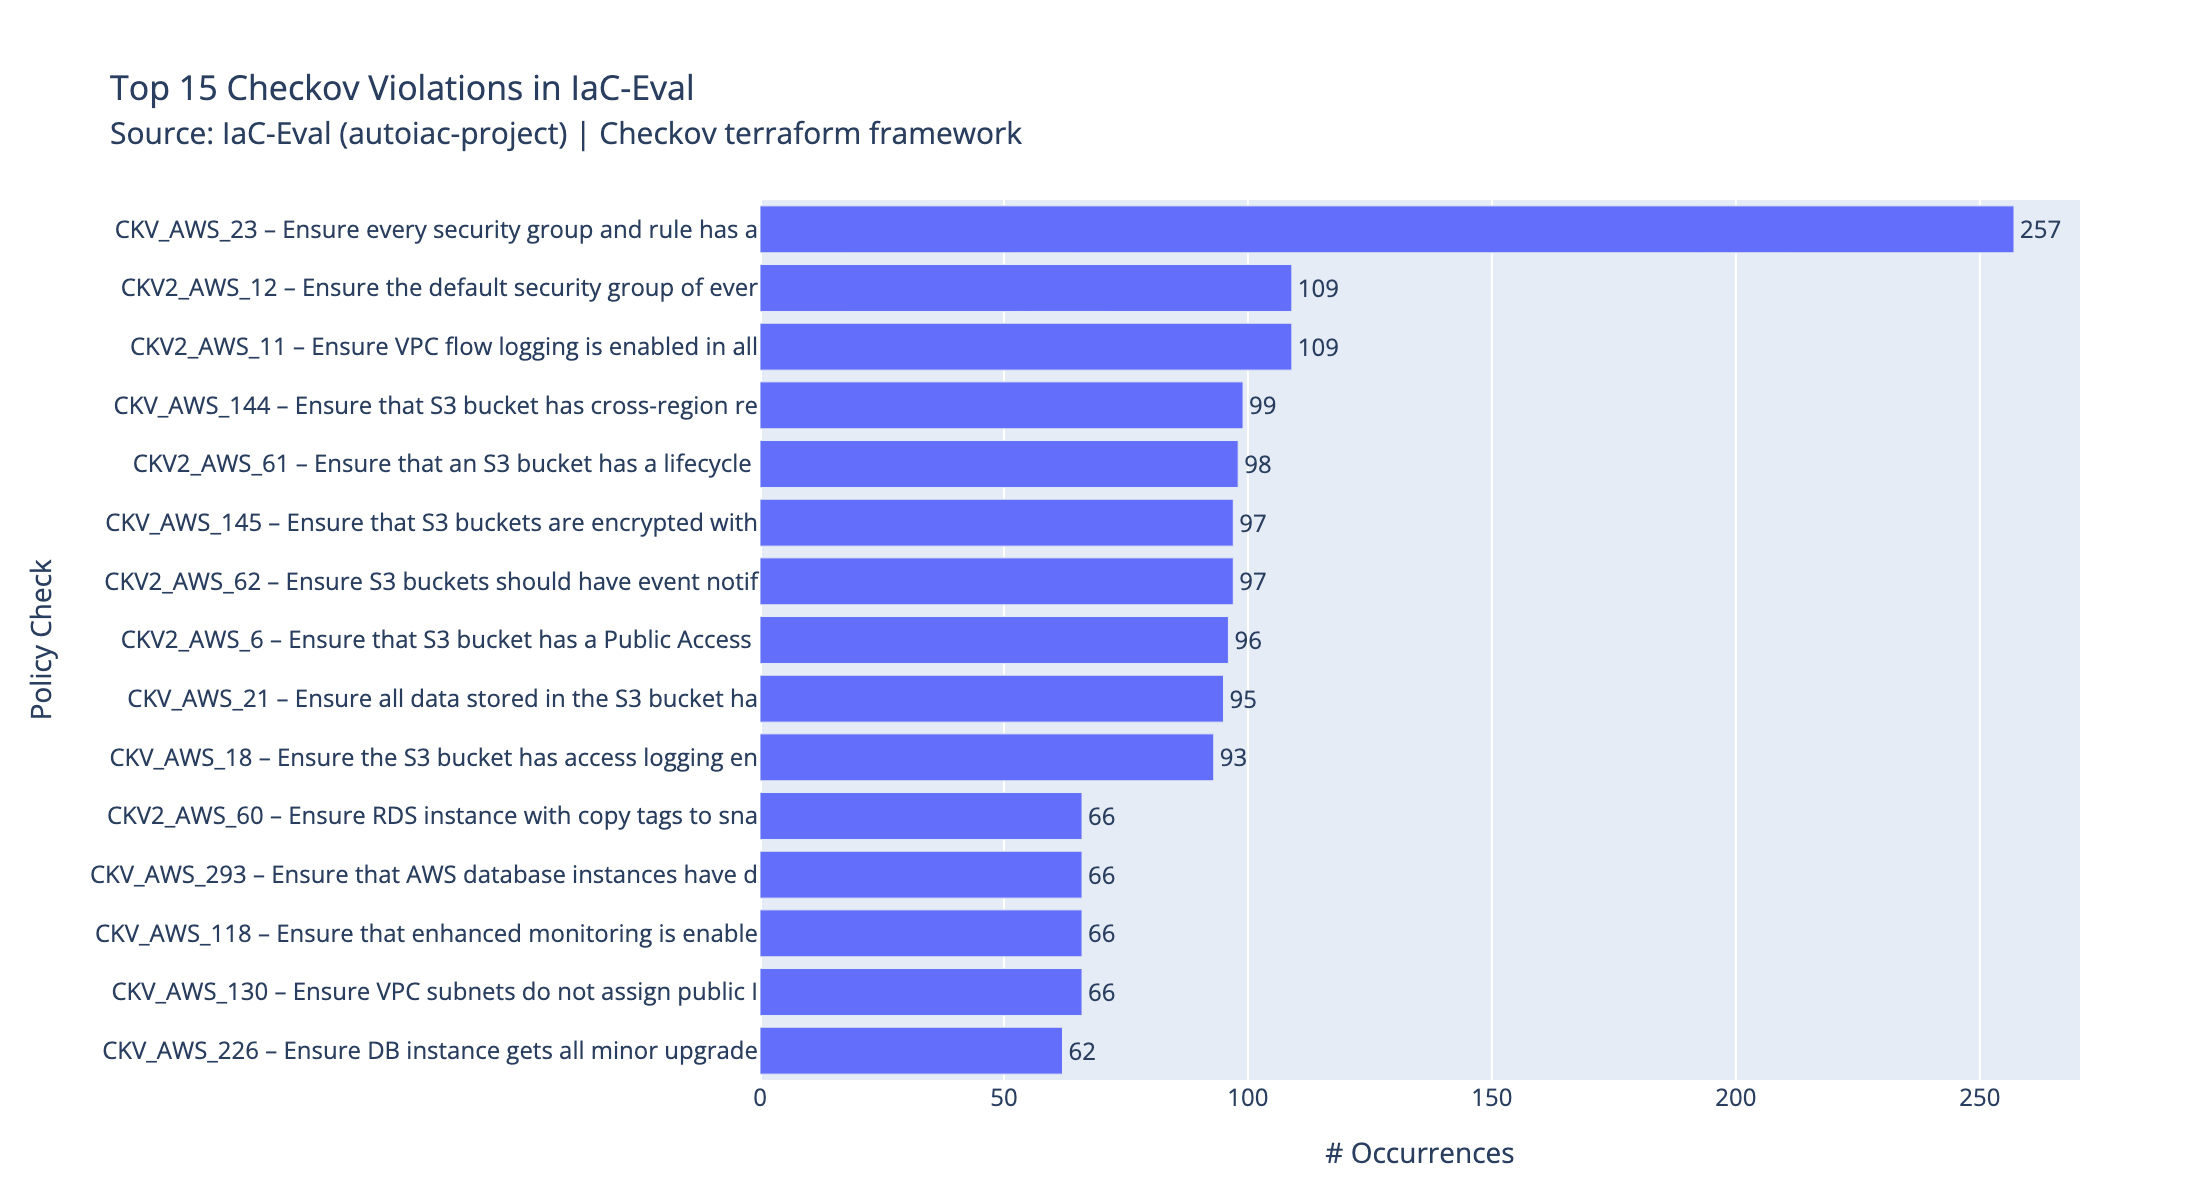

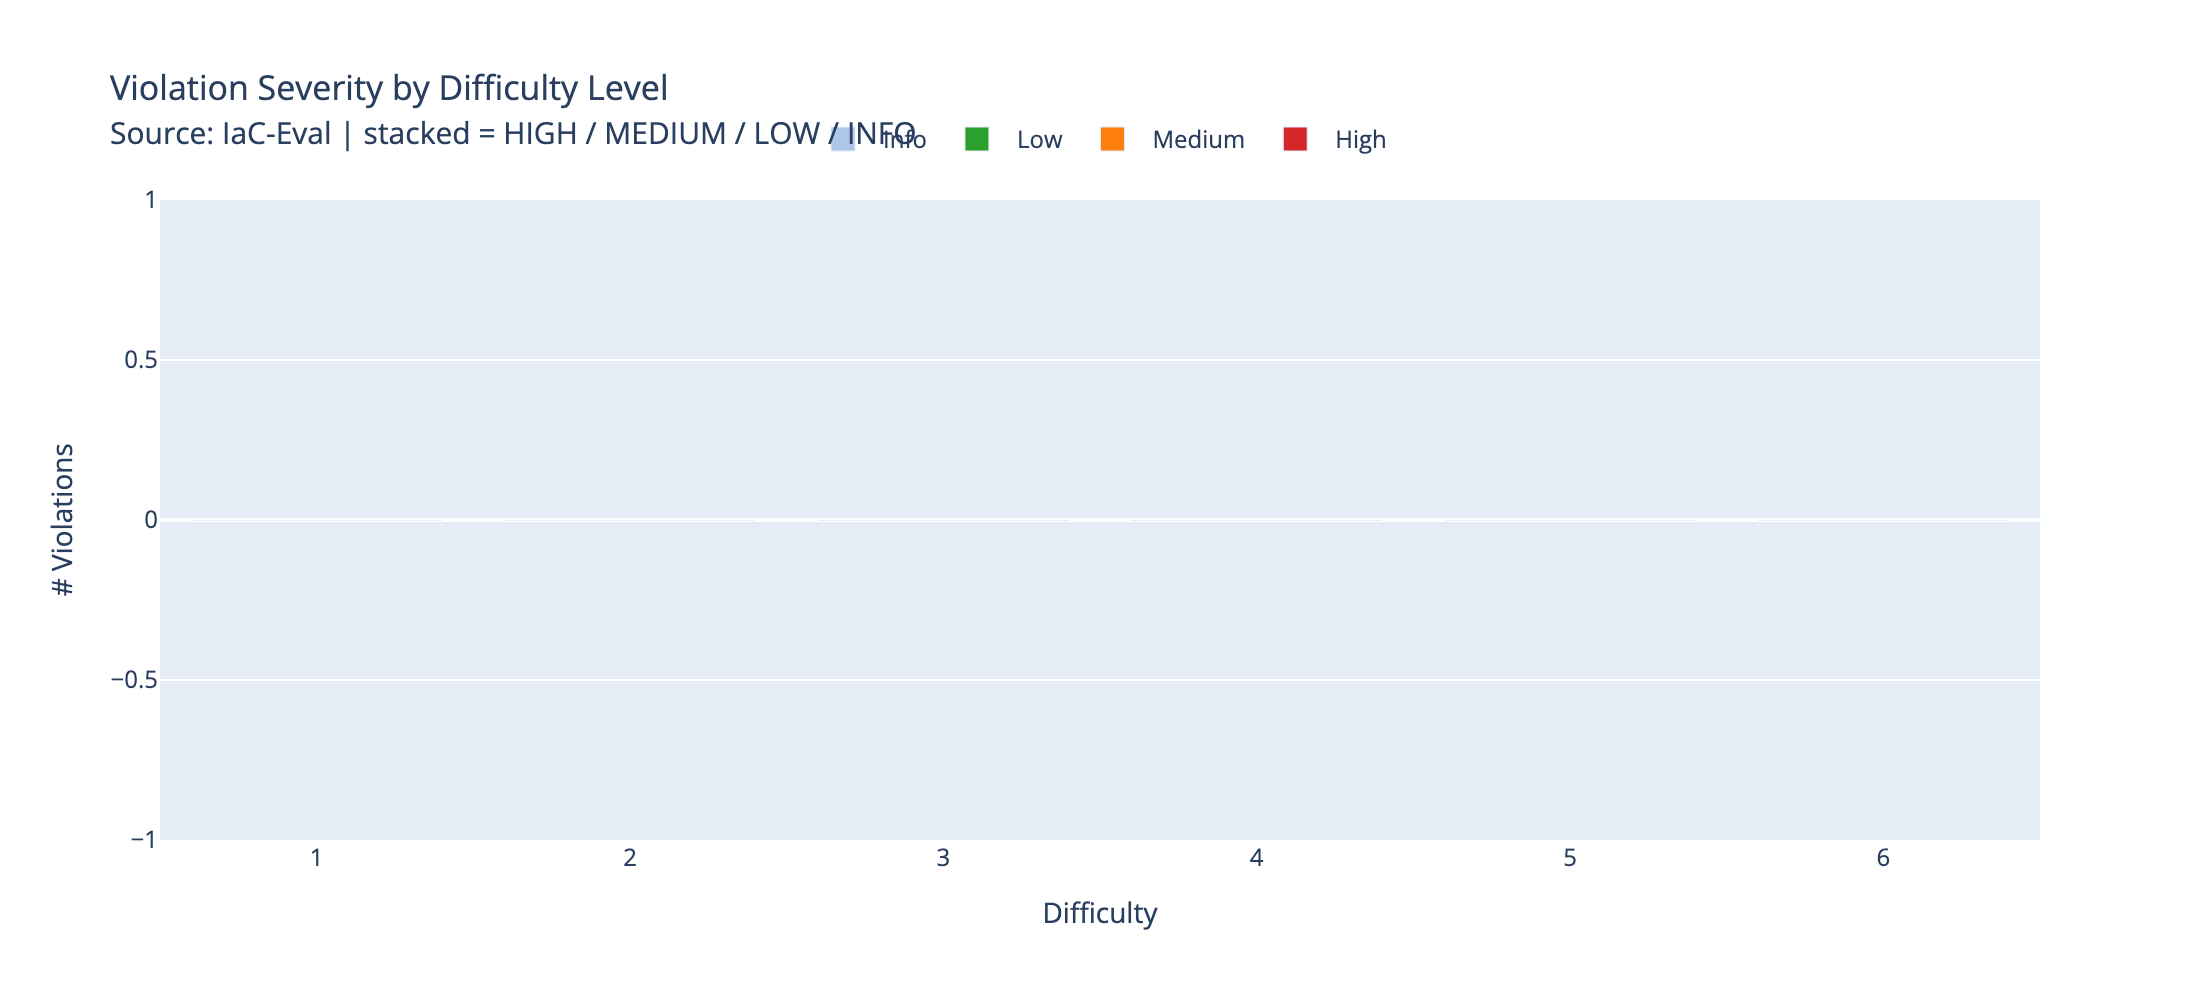

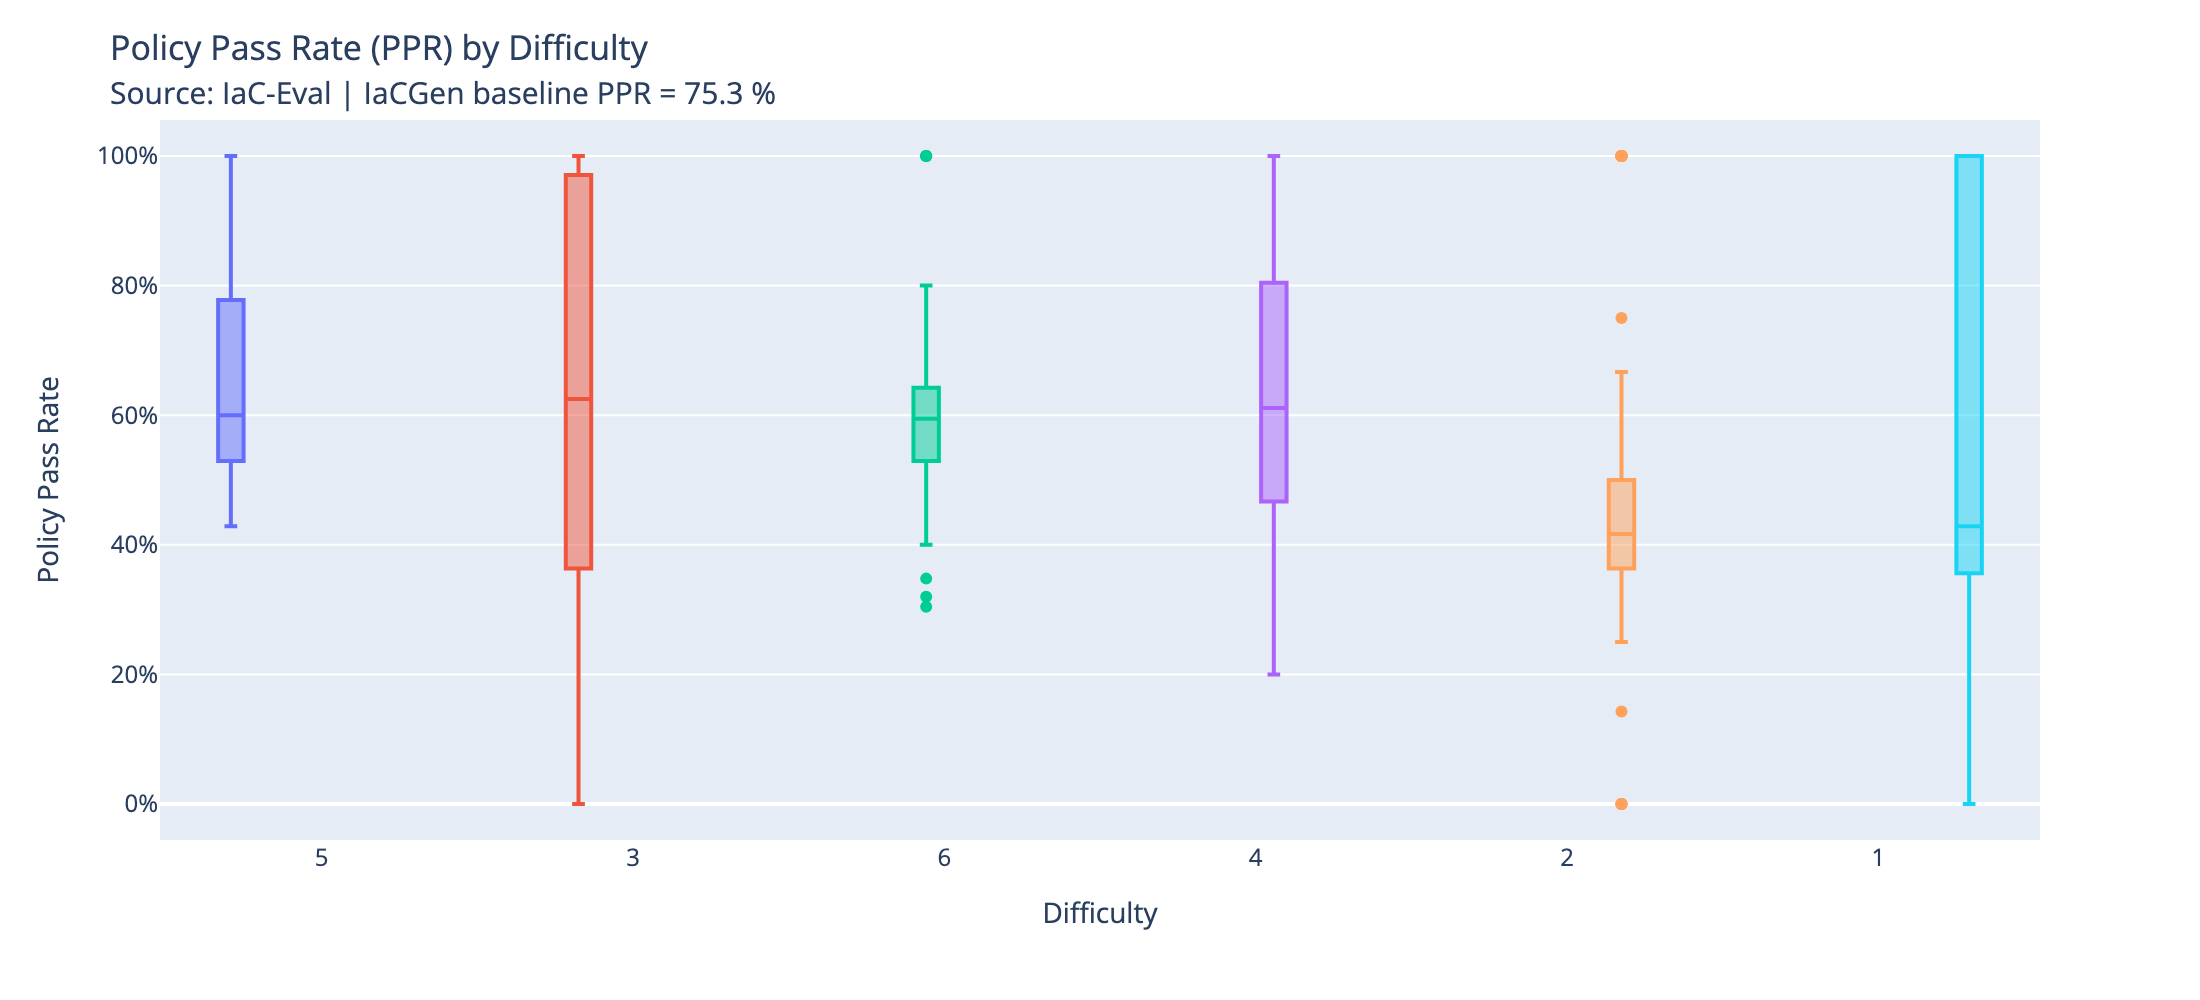

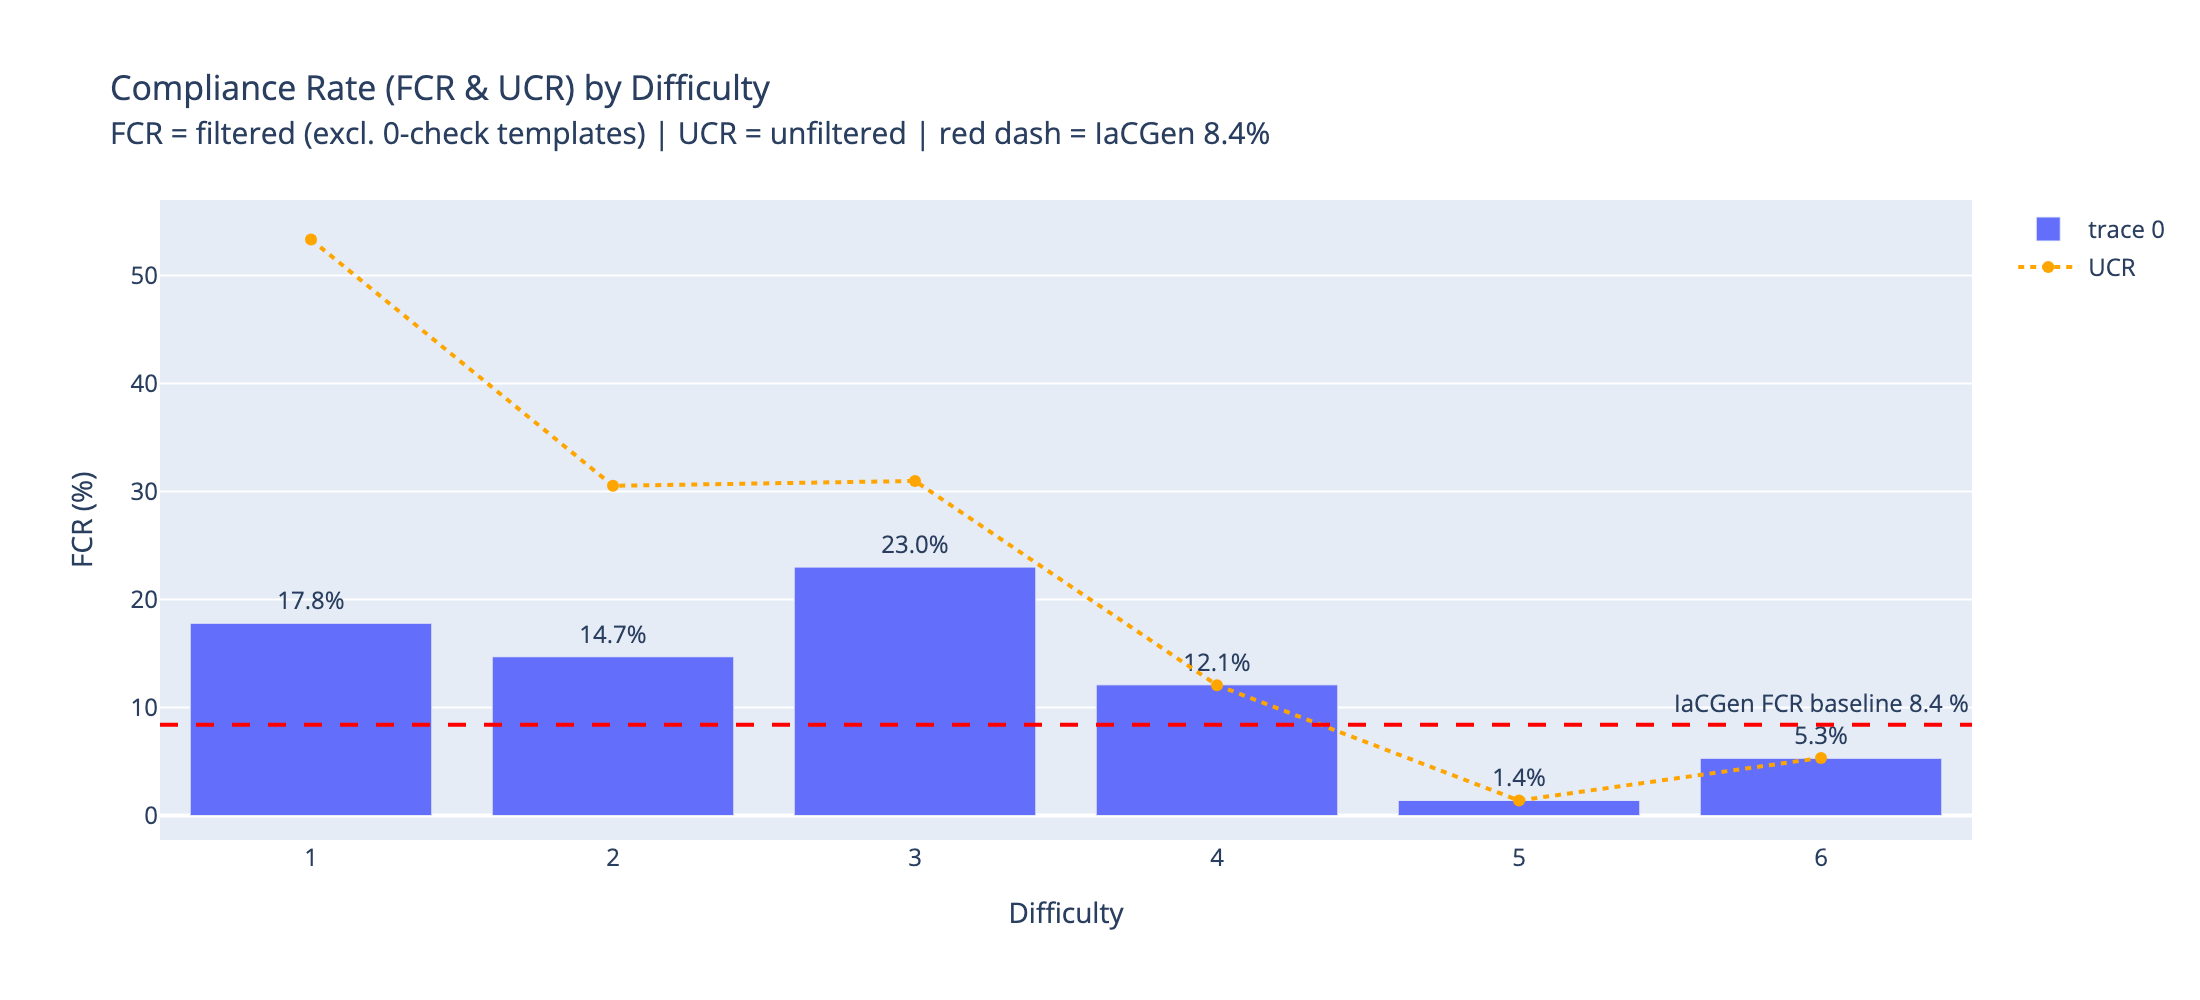

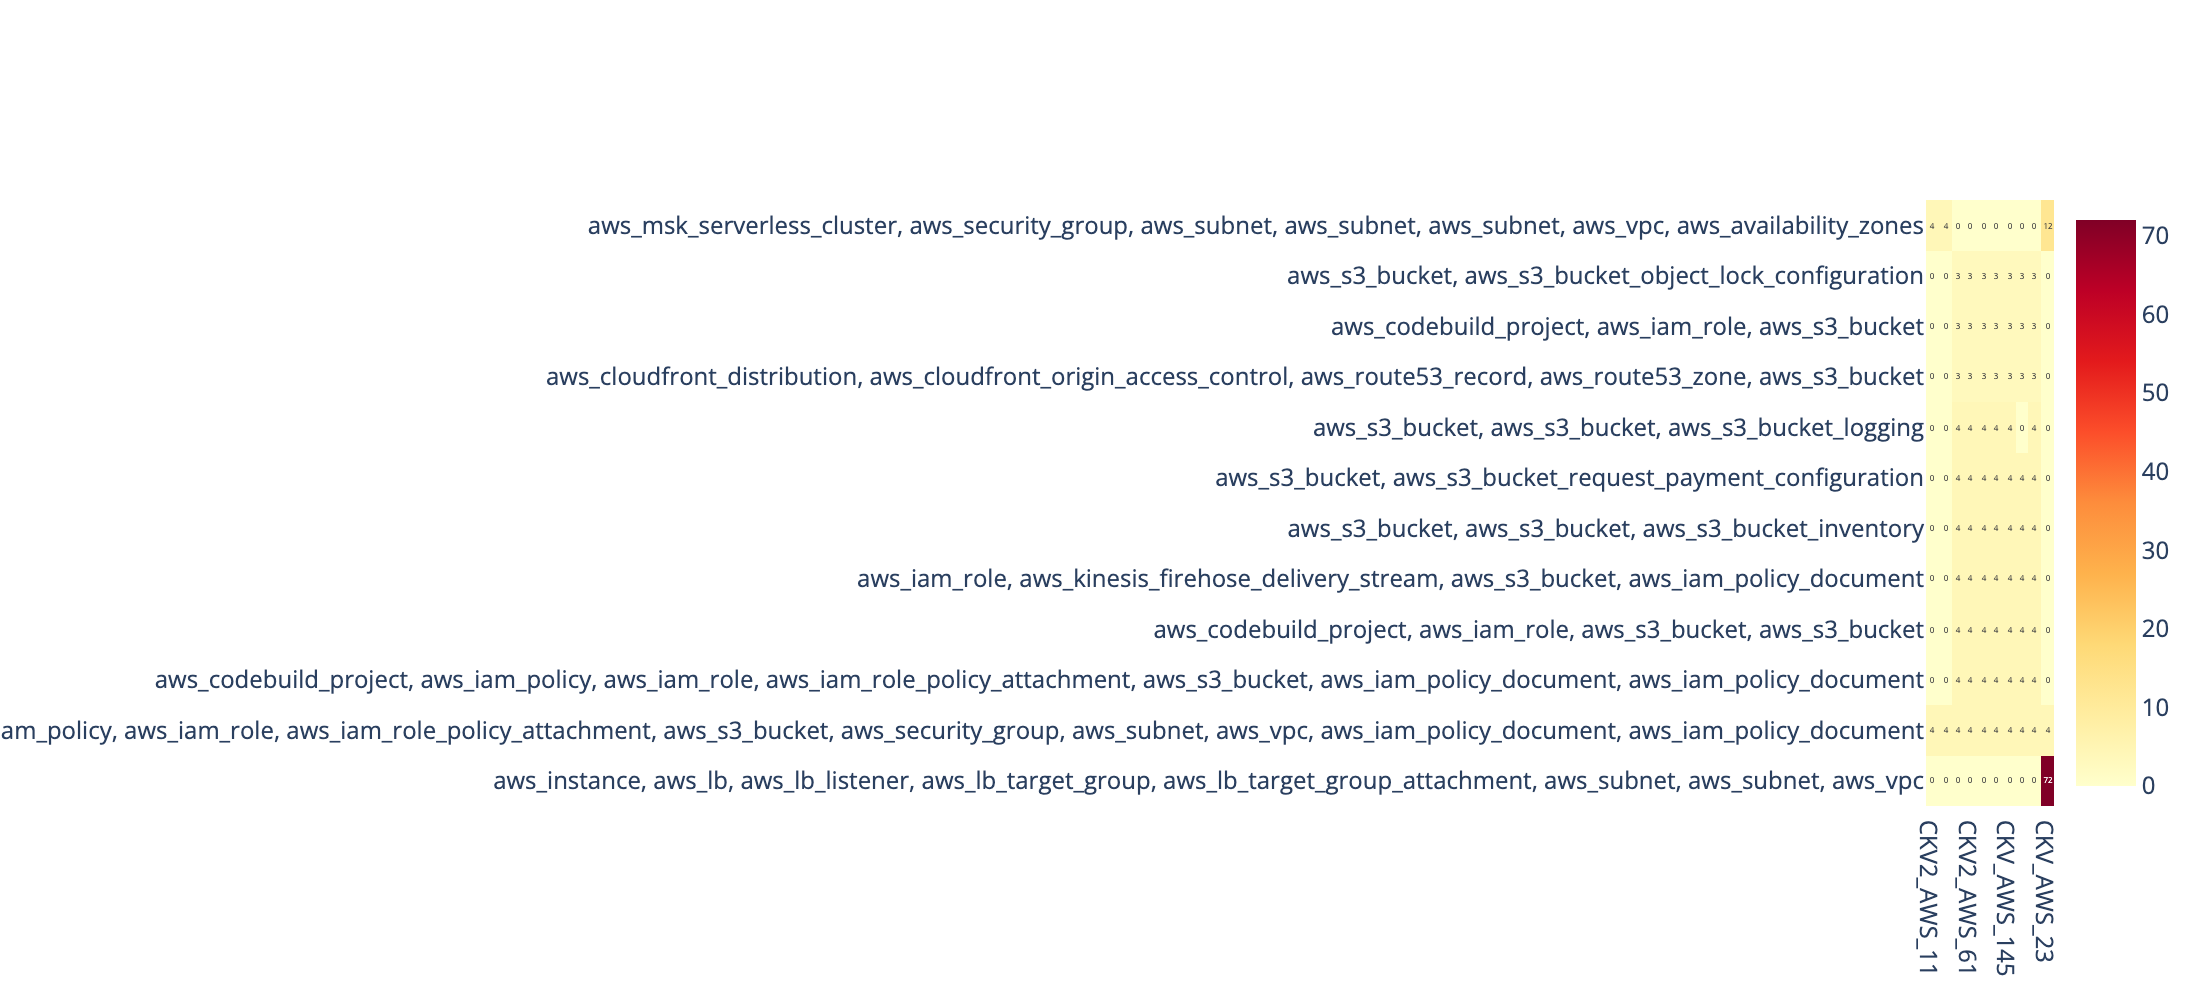

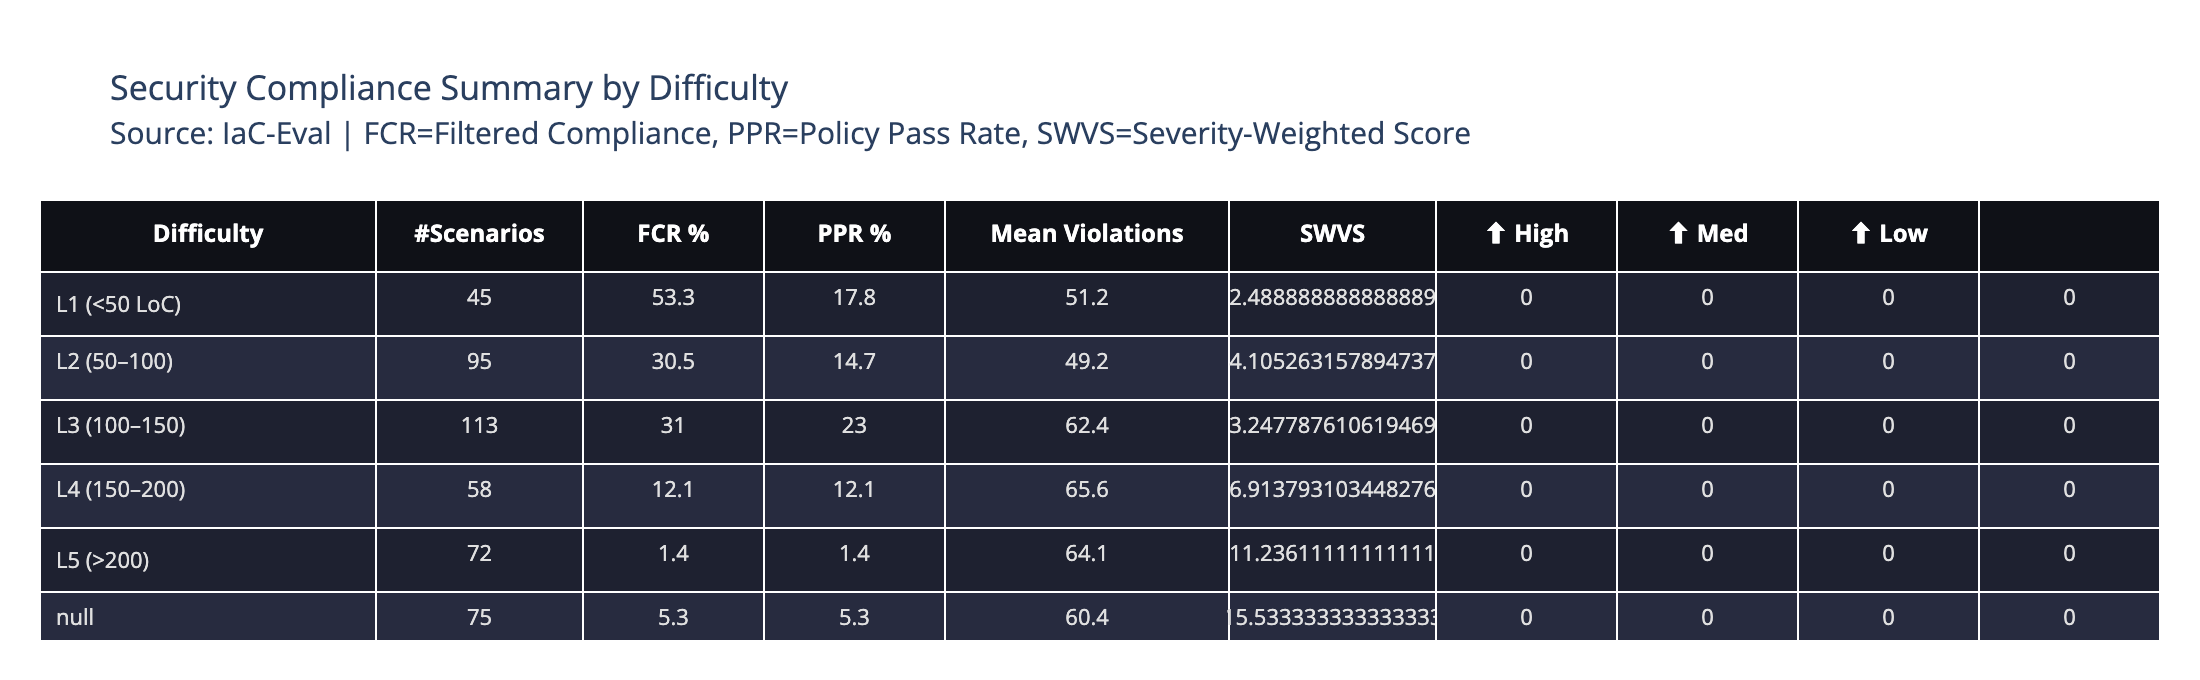

All 6 figures saved → output/checkov_audit


In [27]:
import json as _json

top15 = top_violations.head(15).sort_values('count')
label = top15['check_id'] + ' – ' + top15['check_name'].fillna('')
label = label.str[:55]

fig1 = go.Figure(go.Bar(
    x=top15['count'], y=label, orientation='h',
    text=top15['count'], textposition='outside',
))
fig1.update_layout(
    title=dict(text=(
        'Top 15 Checkov Violations in IaC-Eval<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval (autoiac-project) | Checkov terraform framework"
        "</span>"
    )),
    xaxis_title='# Occurrences',
    yaxis_title='Policy Check',
    margin=dict(l=380, r=60, t=100, b=60),
    height=600,
)
fig1.update_traces(cliponaxis=False)
fig1.show()
with open(str(OUTPUT_DIR / 'top15_violations.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Top 15 Checkov policy violations across IaC-Eval templates',
                'description': 'Horizontal bar chart counting each failed Checkov check'}, f)

sev_cols   = ['severity_high', 'severity_medium', 'severity_low', 'severity_info']
sev_labels = ['High', 'Medium', 'Low', 'Info']
sev_colors = ['#d62728', '#ff7f0e', '#2ca02c', '#aec7e8']

sev_by_diff = df.groupby(_DIFF_COL)[sev_cols].sum().reset_index()

fig2 = go.Figure()
for col, label2, color in zip(sev_cols, sev_labels, sev_colors):
    fig2.add_bar(
        x=sev_by_diff[_DIFF_COL].astype(str),
        y=sev_by_diff[col],
        name=label2,
        marker_color=color,
    )
fig2.update_layout(
    barmode='stack',
    title=dict(text=(
        'Violation Severity by Difficulty Level<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval | stacked = HIGH / MEDIUM / LOW / INFO"
        "</span>"
    )),
    xaxis_title='Difficulty',
    yaxis_title='# Violations',
    legend=dict(orientation='h', yanchor='bottom', y=1.05, xanchor='center', x=0.5),
)
fig2.show()
with open(str(OUTPUT_DIR / 'severity_by_difficulty.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Violation severity distribution by DPIaC-Eval difficulty',
                'description': 'Stacked bar chart with HIGH/MEDIUM/LOW/INFO per difficulty level'}, f)

fig3 = px.box(
    df.dropna(subset=['policy_pass_rate']),
    x=df.dropna(subset=['policy_pass_rate'])[_DIFF_COL].astype(str),
    y='policy_pass_rate',
    color=df.dropna(subset=['policy_pass_rate'])[_DIFF_COL].astype(str),
    points='outliers',
    category_orders={_DIFF_COL: [str(i) for i in range(1, 6)]},
)
fig3.update_layout(
    title=dict(text=(
        'Policy Pass Rate (PPR) by Difficulty<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval | IaCGen baseline PPR = 75.3 %"
        "</span>"
    )),
    xaxis_title='Difficulty',
    yaxis_title='Policy Pass Rate',
    showlegend=False,
)
fig3.update_yaxes(tickformat='.0%')
fig3.show()
with open(str(OUTPUT_DIR / 'ppr_by_difficulty.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Policy pass rate spread per difficulty level',
                'description': 'Box plot of PPR showing IQR + outliers by difficulty'}, f)

fcr = (
    df.groupby(_DIFF_COL)['filtered_compliance']
    .mean()
    .reset_index()
    .rename(columns={'filtered_compliance': 'fcr'})
)
fcr['fcr_pct'] = (fcr['fcr'] * 100).round(1)

ucr_by_diff = (
    df.groupby(_DIFF_COL)['failed_checks']
    .apply(lambda x: (x == 0).mean() * 100)
    .reset_index(name='ucr_pct')
)

fig4 = go.Figure(go.Bar(
    x=fcr[_DIFF_COL].astype(str),
    y=fcr['fcr_pct'],
    text=fcr['fcr_pct'].astype(str) + '%',
    textposition='outside',
))
fig4.add_hline(
    y=8.4, line_dash='dash', line_color='red',
    annotation_text='IaCGen FCR baseline 8.4 %',
    annotation_position='top right',
)
fig4.update_layout(
    title=dict(text=(
        'Filtered Compliance Rate (FCR) by Difficulty<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval | red dash = IaCGen 8.4 % baseline"
        "</span>"
    )),
    xaxis_title='Difficulty',
    yaxis_title='FCR (%)',
)
fig4.add_trace(go.Scatter(
    x=ucr_by_diff[_DIFF_COL].astype(str),
    y=ucr_by_diff['ucr_pct'],
    mode='lines+markers',
    name='UCR',
    line=dict(color='orange', dash='dot'),
))
fig4.update_layout(
    title="Compliance Rate (FCR & UCR) by Difficulty<br>"
          "<span style='font-size:15px;font-weight:normal;'>"
          "FCR = filtered (excl. 0-check templates) | UCR = unfiltered | red dash = IaCGen 8.4%"
          "</span>"
)
fig4.update_traces(cliponaxis=False)
fig4.show()
with open(str(OUTPUT_DIR / 'fcr_by_difficulty.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Filtered compliance rate per difficulty vs IaCGen baseline',
                'description': 'Bar chart of FCR% by difficulty with IaCGen 8.4% reference line'}, f)

top10_ids = top_violations['check_id'].head(10).tolist()
heat_df   = all_violations[all_violations['check_id'].isin(top10_ids)]
heat_piv  = (
    heat_df.groupby([_RES_COL, 'check_id'])
    .size()
    .unstack(fill_value=0)
)
heat_piv = heat_piv.loc[heat_piv.sum(axis=1).nlargest(12).index]

fig5 = go.Figure(go.Heatmap(
    z=heat_piv.values,
    x=heat_piv.columns.tolist(),
    y=heat_piv.index.tolist(),
    colorscale='YlOrRd',
    text=heat_piv.values,
    texttemplate='%{text}',
))
fig5.show()
fig5.update_layout(
    title=dict(text=(
        'Violation Heatmap: Resource × Check ID<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval | top-12 resource types, top-10 check IDs"
        "</span>"
    )),
    xaxis_title='Check ID',
    yaxis_title='Resource Type',
    margin=dict(l=200, r=40, t=100, b=120),
    height=600,
)
with open(str(OUTPUT_DIR / 'violation_heatmap.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Heatmap of top-10 Checkov violations per AWS resource type',
                'description': 'Cell values = raw violation count; rows = resource, cols = check ID'}, f)

tbl = summary_table.copy()
tbl[_DIFF_COL] = tbl[_DIFF_COL].map({
    1: 'L1 (<50 LoC)', 2: 'L2 (50–100)',
    3: 'L3 (100–150)', 4: 'L4 (150–200)', 5: 'L5 (>200)'
})

n = len(tbl)
fills = [['#1e2130' if i % 2 == 0 else '#272b3f' for i in range(n)]] * len(tbl.columns)
hdrs  = ['Difficulty', '#Scenarios', 'FCR %', 'PPR %',
         'Mean Violations', 'SWVS', '⬆ High', '⬆ Med', '⬆ Low']

fig6 = go.Figure(go.Table(
    columnwidth=[130, 80, 70, 70, 110, 80, 70, 70, 70],
    header=dict(
        values    =[f'<b>{h}</b>' for h in hdrs],
        fill_color='#0f1117', font=dict(color='white', size=12),
        align='center', height=36,
    ),
    cells=dict(
        values    =[tbl[c].tolist() for c in tbl.columns],
        fill_color=fills,
        font=dict(color='#e0e0e0', size=11),
        align=['left'] + ['center'] * (len(hdrs) - 1),
        height=32,
    ),
))
fig6.update_layout(
    title=dict(text=(
        'Security Compliance Summary by Difficulty<br>'
        "<span style='font-size:15px;font-weight:normal;'>"
        "Source: IaC-Eval | FCR=Filtered Compliance, PPR=Policy Pass Rate, SWVS=Severity-Weighted Score"
        "</span>"
    )),
    margin=dict(l=20, r=20, t=100, b=20), height=340,
)
fig6.show()
with open(str(OUTPUT_DIR / 'compliance_summary_table.png.meta.json'), 'w') as f:
    _json.dump({'caption': 'Checkov security compliance summary per difficulty level',
                'description': 'Table with FCR, PPR, mean violations, SWVS, and severity counts'}, f)

print('All 6 figures saved →', OUTPUT_DIR)

In [28]:
total   = len(df)
n_with_checks = (df['total_checks'] > 0).sum()

ucr = (df['failed_checks'] == 0).mean()
fcr = df.loc[df['total_checks'] > 0, 'failed_checks'].eq(0).mean()
ppr = df.loc[df['total_checks'] > 0, 'policy_pass_rate'].mean()

print(f"\nCheckov scan complete")
print(f"  Templates scanned                    : {total:,}")
print(f"  Templates with applicable checks     : {n_with_checks:,}  ({n_with_checks/total*100:.1f}%)")
print(f"  Unfiltered Compliance Rate  (UCR)    : {ucr*100:.1f}%   ← denominator: all {total}")
print(f"  Filtered   Compliance Rate  (FCR)    : {fcr*100:.1f}%   ← denominator: {n_with_checks} with checks")
print(f"  Mean Policy Pass Rate       (PPR)    : {ppr*100:.1f}%   ← denominator: {n_with_checks} with checks")
print(f"  Total violations found               : {df['failed_checks'].sum():,}")


Checkov scan complete
  Templates scanned                    : 458
  Templates with applicable checks     : 418  (91.3%)
  Unfiltered Compliance Rate  (UCR)    : 21.8%   ← denominator: all 458
  Filtered   Compliance Rate  (FCR)    : 14.4%   ← denominator: 418 with checks
  Mean Policy Pass Rate       (PPR)    : 59.5%   ← denominator: 418 with checks
  Total violations found               : 3,244


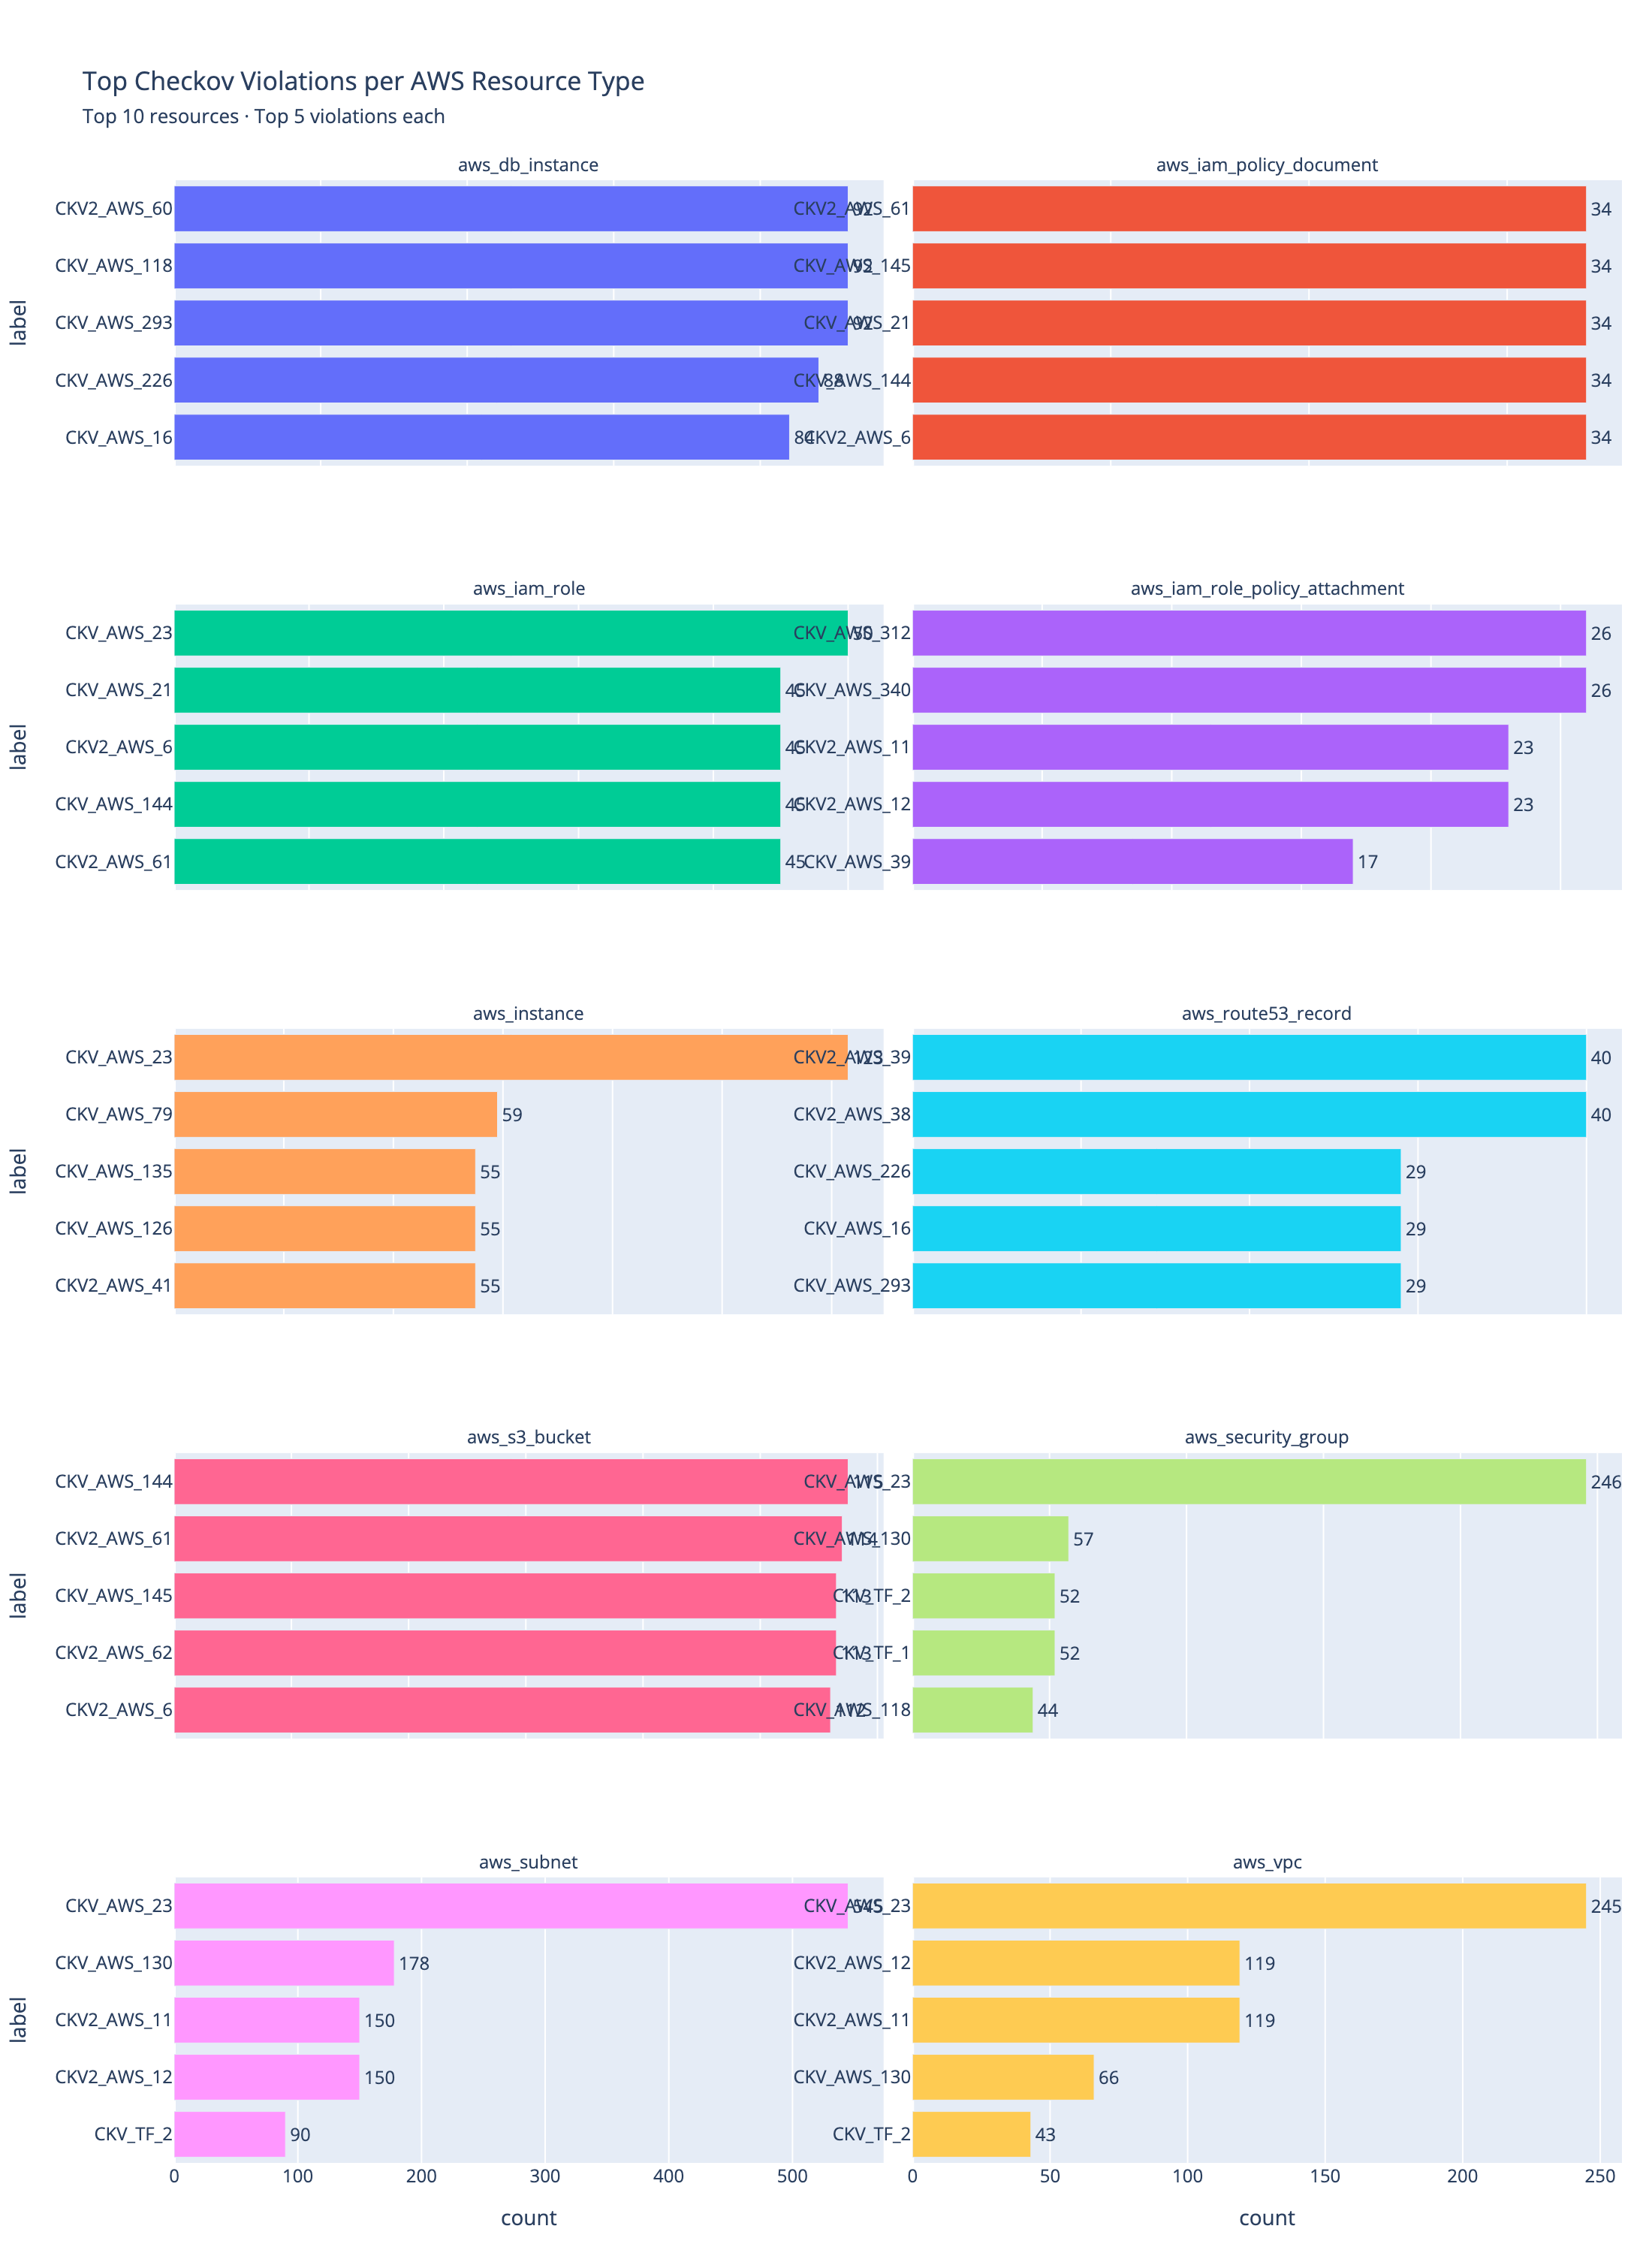


Top 10 resources by total violations:
resource
aws_subnet                        3297
aws_vpc                           1679
aws_security_group                1368
aws_s3_bucket                     1250
aws_iam_role                      1174
aws_db_instance                   1031
aws_instance                       764
aws_iam_policy_document            648
aws_route53_record                 602
aws_iam_role_policy_attachment     484


In [29]:
import ast

df_exploded = df[[_RES_COL, 'violation_ids', 'violation_names']].copy()

rows = []
for _, row in df_exploded.iterrows():
    ids   = row['violation_ids']   if isinstance(row['violation_ids'],   list) else []
    names = row['violation_names'] if isinstance(row['violation_names'], list) else []
    if isinstance(ids,   str): ids   = json.loads(ids)
    if isinstance(names, str): names = json.loads(names)
    for cid, cname in zip(ids, names):
        if cid:
            rows.append({'resource': row[_RES_COL], 'check_id': cid, 'check_name': cname})

df_long = pd.DataFrame(rows)

df_long['resource'] = df_long['resource'].str.split(',')
df_long = df_long.explode('resource')
df_long['resource'] = df_long['resource'].str.strip()

violation_counts = (
    df_long.groupby(['resource', 'check_id', 'check_name'])
    .size()
    .reset_index(name='count')
)

TOP_VIOLATIONS_PER_RESOURCE = 5
TOP_RESOURCES = 10

top_per_resource = (
    violation_counts
    .sort_values('count', ascending=False)
    .groupby('resource')
    .head(TOP_VIOLATIONS_PER_RESOURCE)
)

resource_totals = (
    violation_counts.groupby('resource')['count']
    .sum()
    .sort_values(ascending=False)
)
top_resources = resource_totals.head(TOP_RESOURCES).index.tolist()

plot_df = (
    top_per_resource[top_per_resource['resource'].isin(top_resources)]
    .copy()
)

plot_df['label'] = plot_df['check_id']

fig = px.bar(
    plot_df.sort_values(['resource', 'count'], ascending=[True, True]),
    x='count',
    y='label',
    color='resource',
    facet_col='resource',
    facet_col_wrap=2,
    orientation='h',
    text='count',
    hover_data={'check_name': True, 'check_id': True, 'count': True, 'resource': False},
    title='Top Checkov Violations per AWS Resource Type<br>'
          '<span style="font-size:13px;font-weight:normal">'
          f'Top {TOP_RESOURCES} resources · Top {TOP_VIOLATIONS_PER_RESOURCE} violations each'
          '</span>',
    color_discrete_sequence=px.colors.qualitative.Plotly,
)

fig.update_traces(textposition='outside', cliponaxis=False)
fig.update_layout(
    height=300 * ((len(top_resources) + 1) // 2),
    showlegend=False,
    margin=dict(t=120, l=20, r=20, b=60),
)
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
fig.update_yaxes(matches=None, showticklabels=True)
fig.update_xaxes(matches=None)

fig.show()

print(f"\nTop {TOP_RESOURCES} resources by total violations:")
print(resource_totals.head(TOP_RESOURCES).to_string())

## IaC-Eval — Trivy detail

In [30]:
import ast

def _remap_violations_json(violations_json: str) -> str:
    try:
        violations = json.loads(violations_json)
    except Exception:
        return violations_json
    for v in violations:
        cid = v.get('check_id', '')
        v['check_title'] = AVD_TITLE_MAP.get(cid, v.get('check_title', cid))
    return json.dumps(violations)

df_trivy['violations_json'] = df_trivy['violations_json'].apply(_remap_violations_json)

all_violations = []
for vj in df_trivy['violations_json']:
    try:
        all_violations.extend(json.loads(vj))
    except Exception:
        pass

df_violations = pd.DataFrame(all_violations)

df_violations['check_title'] = df_violations['check_id'].map(AVD_TITLE_MAP).fillna(
    df_violations['check_title']
)

top_trivy_violations = (
    df_violations.groupby(['check_id', 'check_title'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

trivy_summary = (
    df_trivy.groupby(_DIFF_COL)
    .agg(
        scenarios             = (_CODE_COL,              'count'),
        pct_compliant         = ('filtered_compliance',  'mean'),
        mean_ppr              = ('policy_pass_rate',     'mean'),
        mean_violations       = ('failed_checks',        'mean'),
        mean_swvs             = ('swvs',                 'mean'),
        total_critical        = ('severity_critical',    'sum'),
        total_high            = ('severity_high',        'sum'),
        total_medium          = ('severity_medium',      'sum'),
        total_low             = ('severity_low',         'sum'),
    )
    .reset_index()
)
trivy_summary['pct_compliant']   = (trivy_summary['pct_compliant'].fillna(0) * 100).round(1)
trivy_summary['mean_ppr']        = (trivy_summary['mean_ppr'].fillna(0)      * 100).round(1)
trivy_summary['mean_violations'] = trivy_summary['mean_violations'].round(1)
trivy_summary['mean_swvs']       = trivy_summary['mean_swvs'].round(2)

print(trivy_summary.to_string(index=False))
top_trivy_violations.head(20)

 Difficulty  scenarios  pct_compliant  mean_ppr  mean_violations  mean_swvs  total_critical  total_high  total_medium  total_low
          1         45           60.0      61.4              1.5       3.22               0          23            31         14
          2         95           38.9      38.9              3.5       8.28               0         192            66         79
          3        113           36.3      36.9              1.8       4.18               0          95            74         39
          4         58           25.9      25.9              4.5      11.12              23         110            94         35
          5         72            8.3       8.3              6.9      15.78              57         191            85        165
          6         75            6.7       6.7             10.2      22.36              61         278           173        253


,check_id,check_title,count
50,AWS-0124,Missing description for security group rule.,178
61,AWS-0178,VPC Flow Logs is a feature that enables you to...,109
56,AWS-0132,S3 encryption should use Customer Managed Keys,96
38,AWS-0087,S3 Access block should block public policy,95
41,AWS-0091,S3 Access Block should Ignore Public ACL,94
37,AWS-0086,S3 Access block should block public ACL,94
43,AWS-0094,S3 buckets should each define an aws_s3_bucket...,94
42,AWS-0093,S3 Access block should restrict public bucket ...,94
39,AWS-0089,S3 Bucket Logging,94
40,AWS-0090,S3 Data should be versioned,93


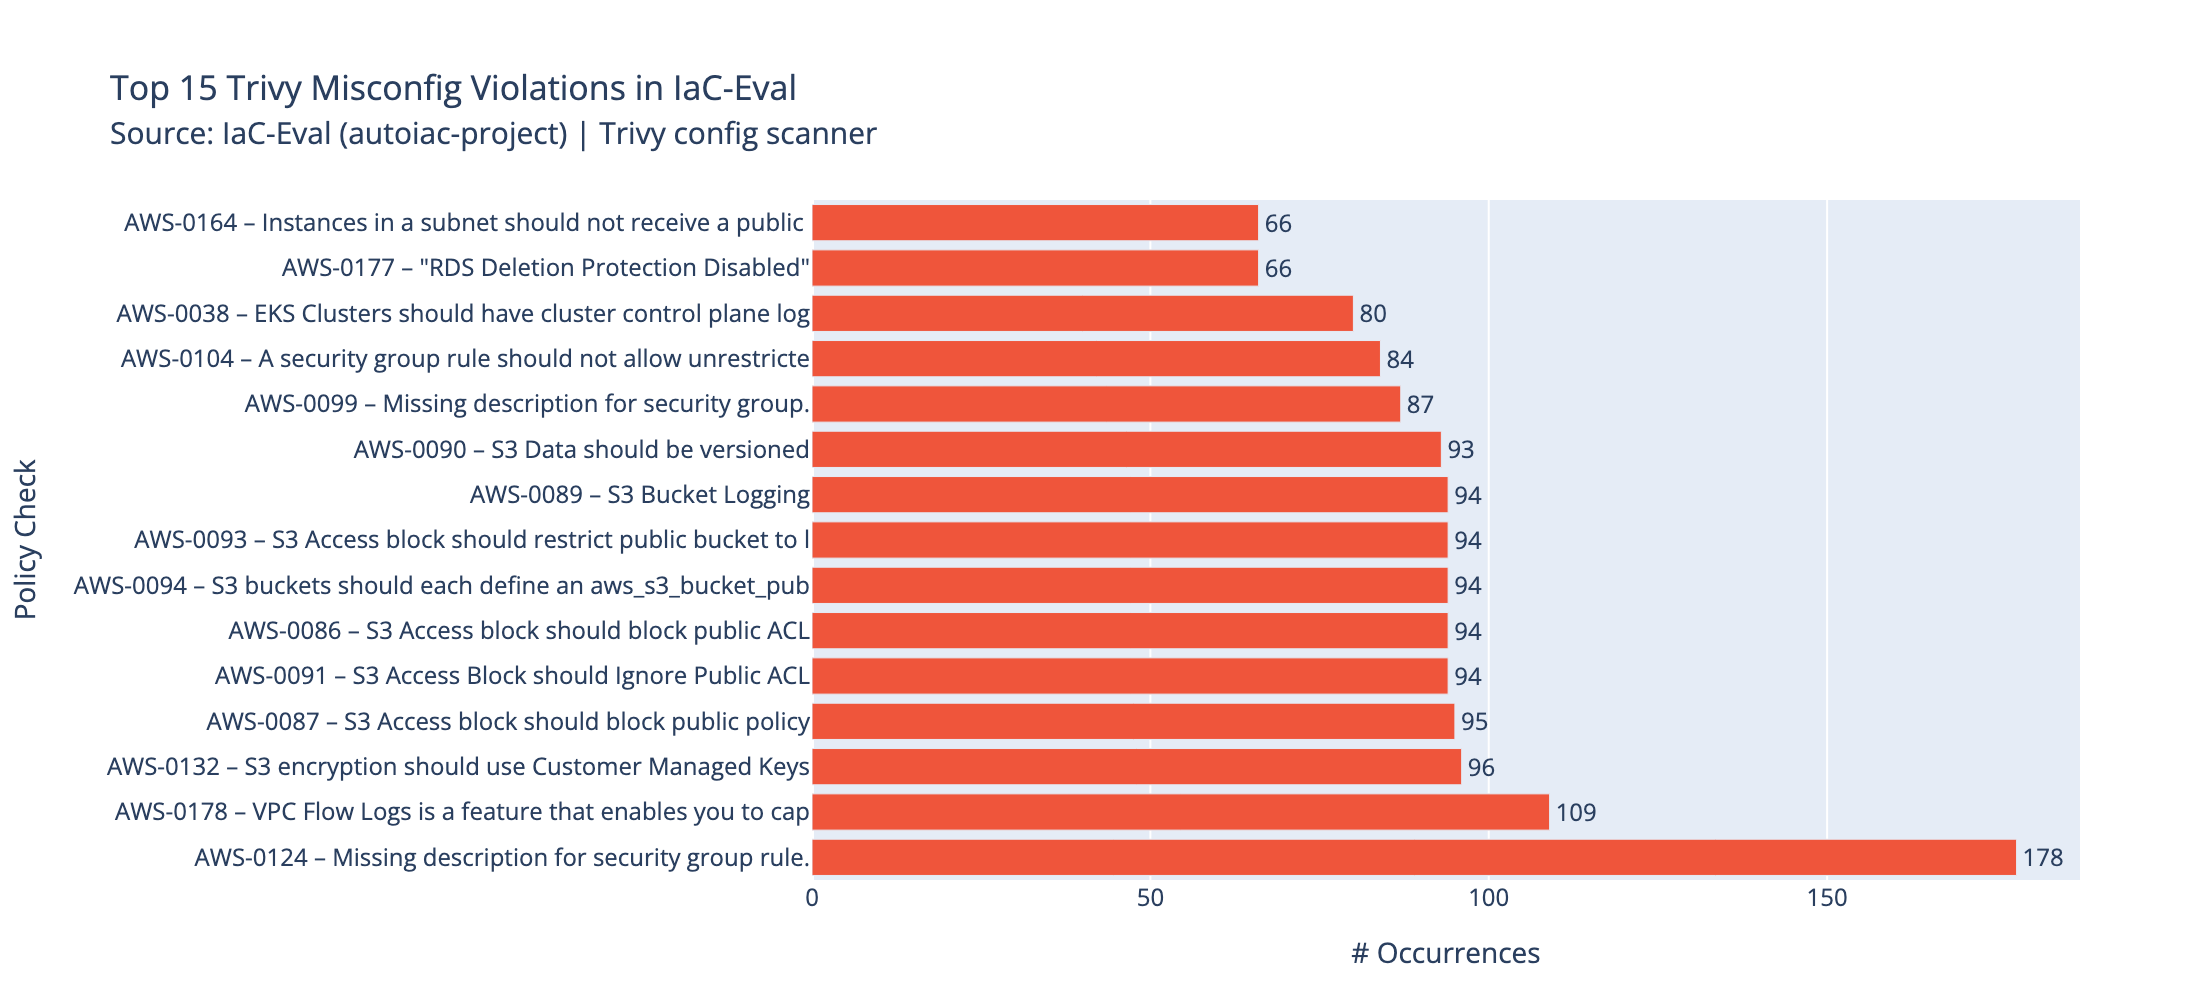

In [31]:
top15 = top_trivy_violations.head(15).copy()
top15['label'] = top15.apply(
    lambda r: f"{r['check_id']} – {str(r['check_title'])[:50]}", axis=1
)

fig_top = go.Figure(go.Bar(
    x=top15['count'],
    y=top15['label'],
    orientation='h',
    text=top15['count'],
    textposition='outside',
    cliponaxis=False,
    marker_color='#EF553B',
))
fig_top.update_layout(
    title="Top 15 Trivy Misconfig Violations in IaC-Eval<br>"
          "<span style='font-size:15px;font-weight:normal;'>"
          "Source: IaC-Eval (autoiac-project) | Trivy config scanner</span>",
    xaxis_title='# Occurrences',
    yaxis_title='Policy Check',
    margin=dict(l=380, r=60, t=100, b=60),
    autosize=True,
)
fig_top.show()

top_trivy_violations.to_csv(TRIVY_OUTPUT_DIR / 'trivy_top15_violations.csv', index=False)

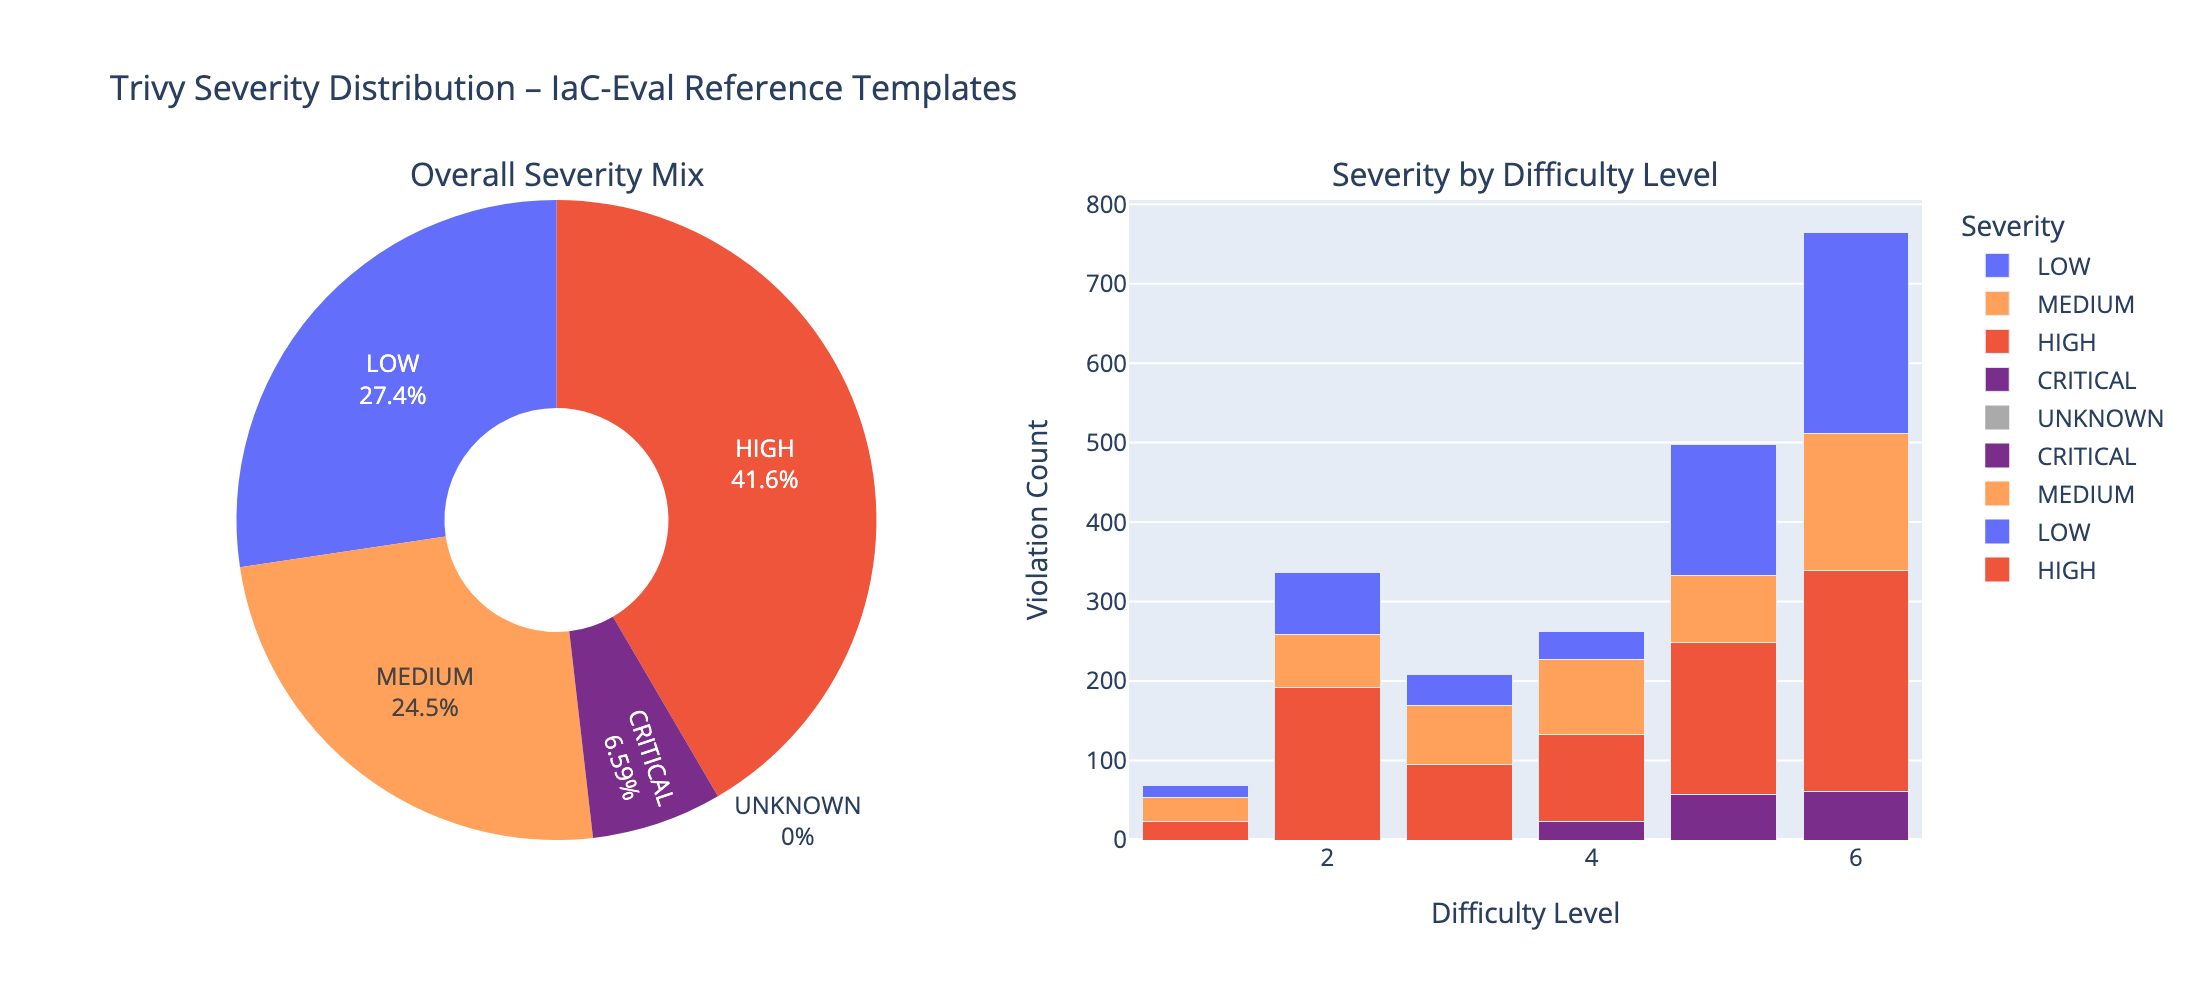

In [32]:
sev_totals = {
    'CRITICAL': int(df_trivy['severity_critical'].sum()),
    'HIGH':     int(df_trivy['severity_high'].sum()),
    'MEDIUM':   int(df_trivy['severity_medium'].sum()),
    'LOW':      int(df_trivy['severity_low'].sum()),
    'UNKNOWN':  int(df_trivy['severity_unknown'].sum()),
}
sev_colors = {
    'CRITICAL': '#7B2D8B', 'HIGH': '#EF553B',
    'MEDIUM':   '#FFA15A', 'LOW':  '#636EFA', 'UNKNOWN': '#AAAAAA'
}

fig_sev = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'pie'}, {'type': 'bar'}]],
    subplot_titles=('Overall Severity Mix', 'Severity by Difficulty Level'),
)

fig_sev.add_trace(go.Pie(
    labels=list(sev_totals.keys()),
    values=list(sev_totals.values()),
    marker_colors=[sev_colors[s] for s in sev_totals],
    hole=0.35,
    textinfo='label+percent',
), row=1, col=1)

for sev, col_name in [
    ('CRITICAL', 'total_critical'), ('HIGH', 'total_high'),
    ('MEDIUM',   'total_medium'),   ('LOW',  'total_low'),
]:
    fig_sev.add_trace(go.Bar(
        x=trivy_summary[_DIFF_COL],
        y=trivy_summary[col_name],
        name=sev,
        marker_color=sev_colors[sev],
    ), row=1, col=2)

fig_sev.update_layout(
    title='Trivy Severity Distribution – IaC-Eval Reference Templates',
    barmode='stack',
    xaxis_title='Difficulty Level',
    yaxis_title='Violation Count',
    legend_title='Severity',
    height=500,
)
fig_sev.show()

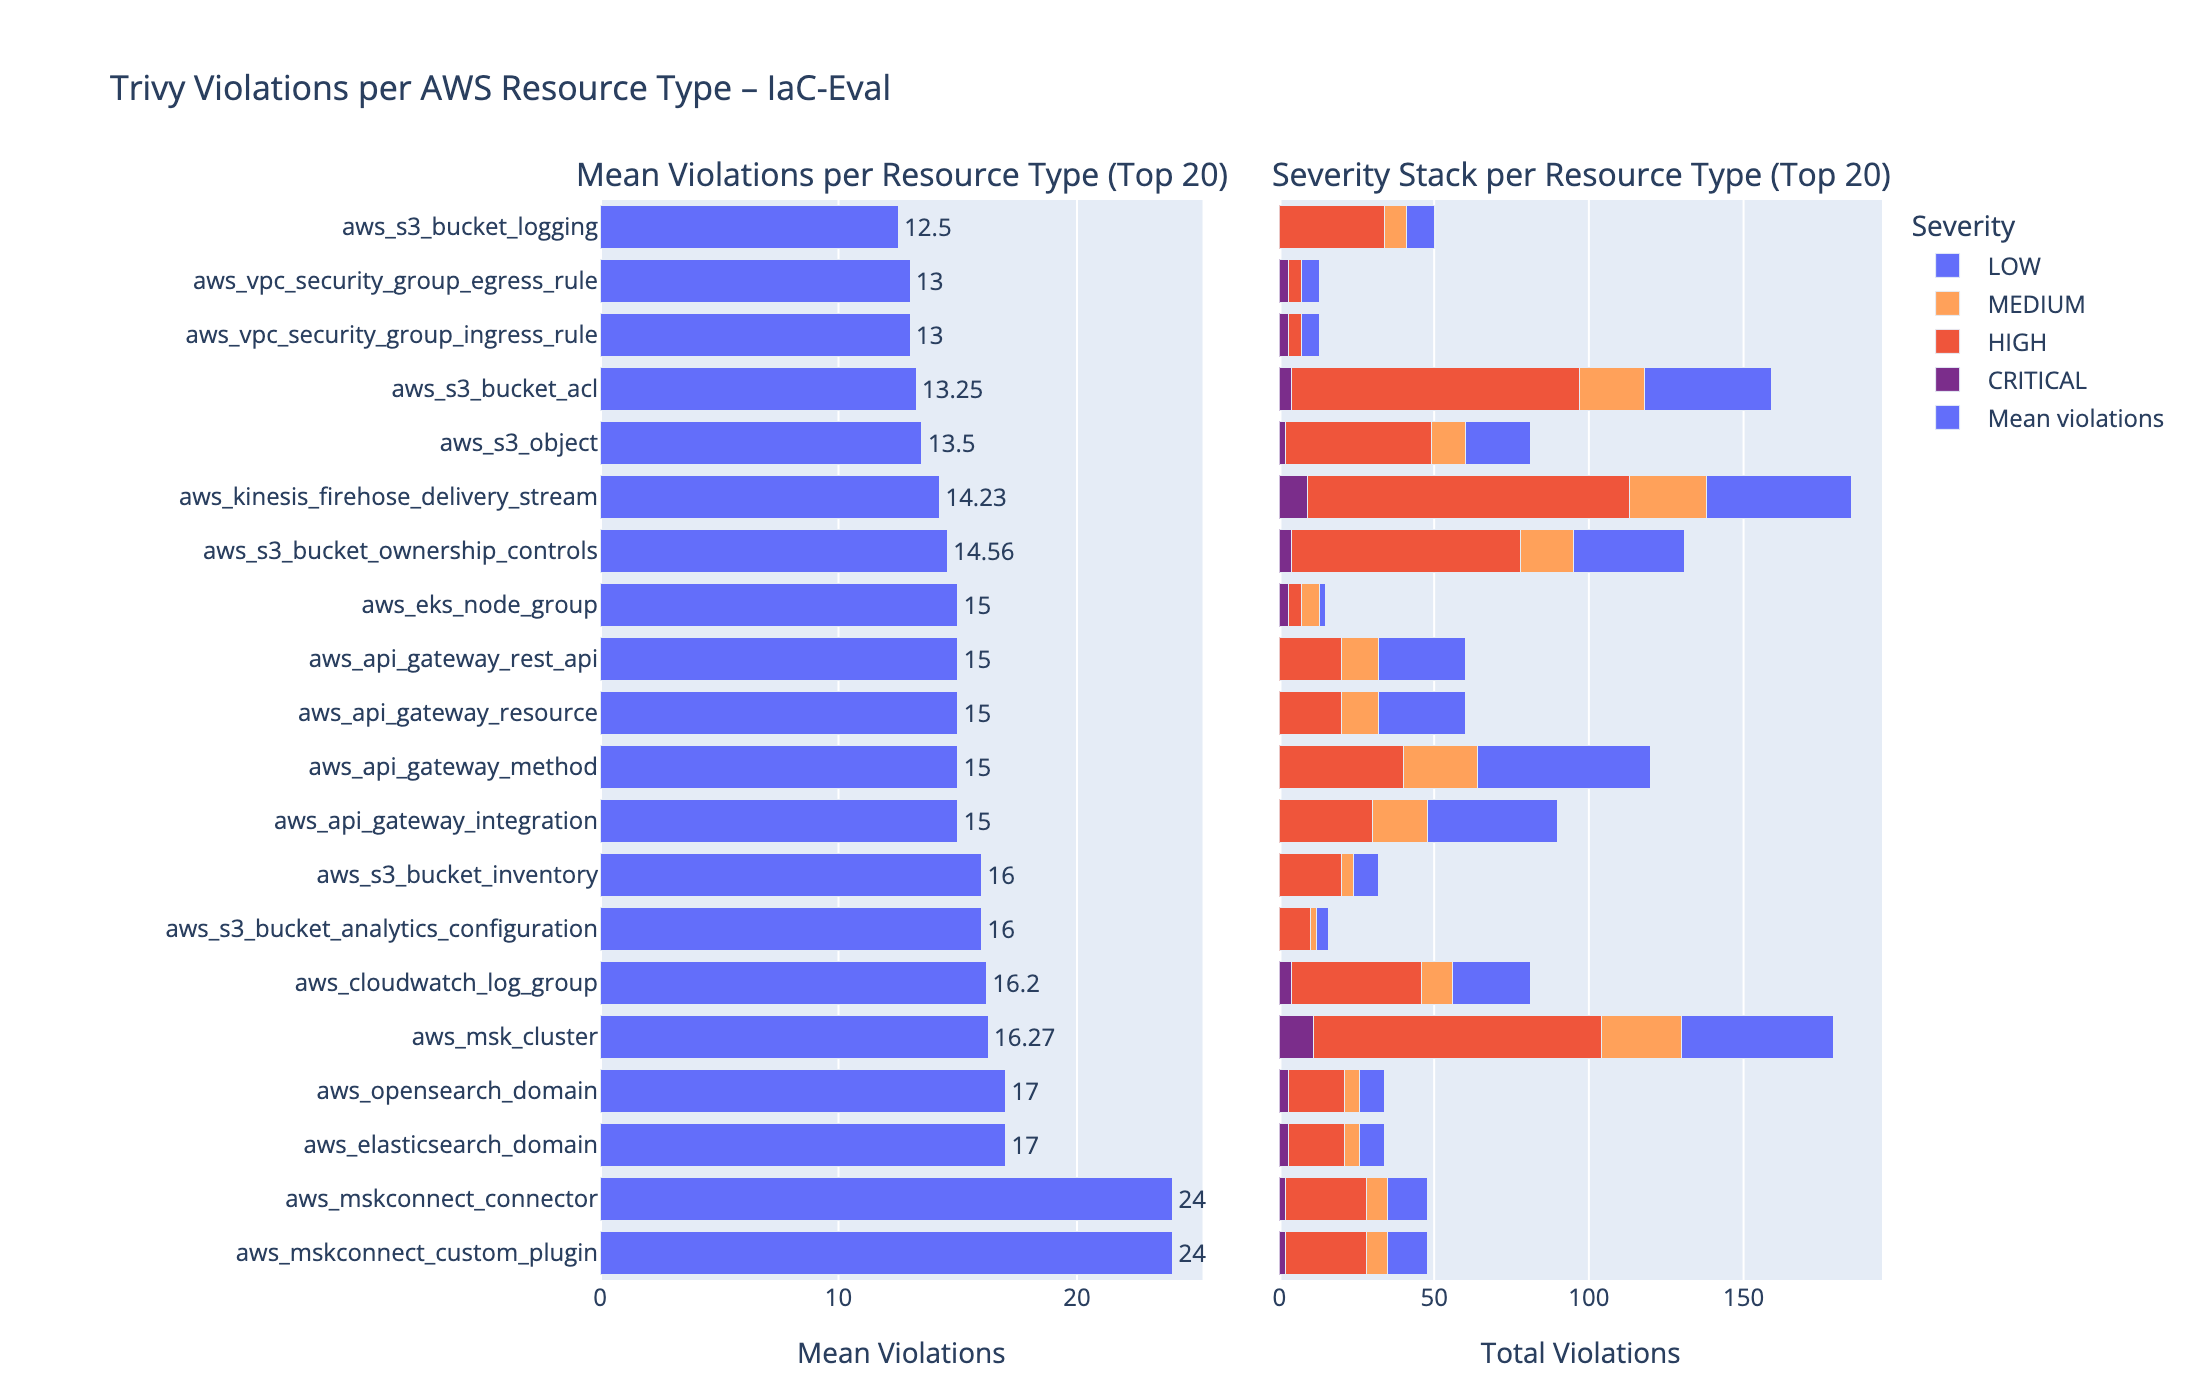

In [33]:
df_res_exploded = df_trivy.copy()
df_res_exploded[_RES_COL] = df_res_exploded[_RES_COL].str.split(r',\s*')
df_res_exploded = df_res_exploded.explode(_RES_COL)
df_res_exploded[_RES_COL] = df_res_exploded[_RES_COL].str.strip()

res_summary = (
    df_res_exploded.groupby(_RES_COL)
    .agg(
        scenario_count  = (_CODE_COL,             'count'),
        mean_violations = ('failed_checks',        'mean'),
        mean_swvs       = ('swvs',                 'mean'),
        pct_compliant   = ('filtered_compliance',  'mean'),
        total_critical  = ('severity_critical',    'sum'),
        total_high      = ('severity_high',        'sum'),
        total_medium    = ('severity_medium',      'sum'),
        total_low       = ('severity_low',         'sum'),
    )
    .reset_index()
    .sort_values('mean_violations', ascending=False)
)
res_summary['pct_compliant'] = (res_summary['pct_compliant'] * 100).round(1)
res_summary['mean_violations']= res_summary['mean_violations'].round(2)
res_summary['mean_swvs']      = res_summary['mean_swvs'].round(2)

top_res = res_summary.head(20)

fig_res = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        'Mean Violations per Resource Type (Top 20)',
        'Severity Stack per Resource Type (Top 20)',
    ),
    horizontal_spacing=0.06,
)

fig_res.add_trace(go.Bar(
    x=top_res['mean_violations'],
    y=top_res[_RES_COL],
    orientation='h',
    name='Mean violations',
    marker_color='#636EFA',
    text=top_res['mean_violations'],
    textposition='outside',
    cliponaxis=False,
), row=1, col=1)

for sev, col_name in [
    ('CRITICAL', 'total_critical'), ('HIGH', 'total_high'),
    ('MEDIUM',   'total_medium'),   ('LOW',  'total_low'),
]:
    fig_res.add_trace(go.Bar(
        x=top_res[col_name],
        y=top_res[_RES_COL],
        orientation='h',
        name=sev,
        marker_color=sev_colors[sev],
        showlegend=True,
    ), row=1, col=2)

fig_res.update_layout(
    title='Trivy Violations per AWS Resource Type – IaC-Eval',
    barmode='stack',
    height=700,
    margin=dict(l=300, r=80, t=100, b=60),
    legend_title='Severity',
)
fig_res.update_xaxes(title_text='Mean Violations', row=1, col=1)
fig_res.update_xaxes(title_text='Total Violations', row=1, col=2)
fig_res.update_yaxes(showticklabels=False, row=1, col=2)

fig_res.show()

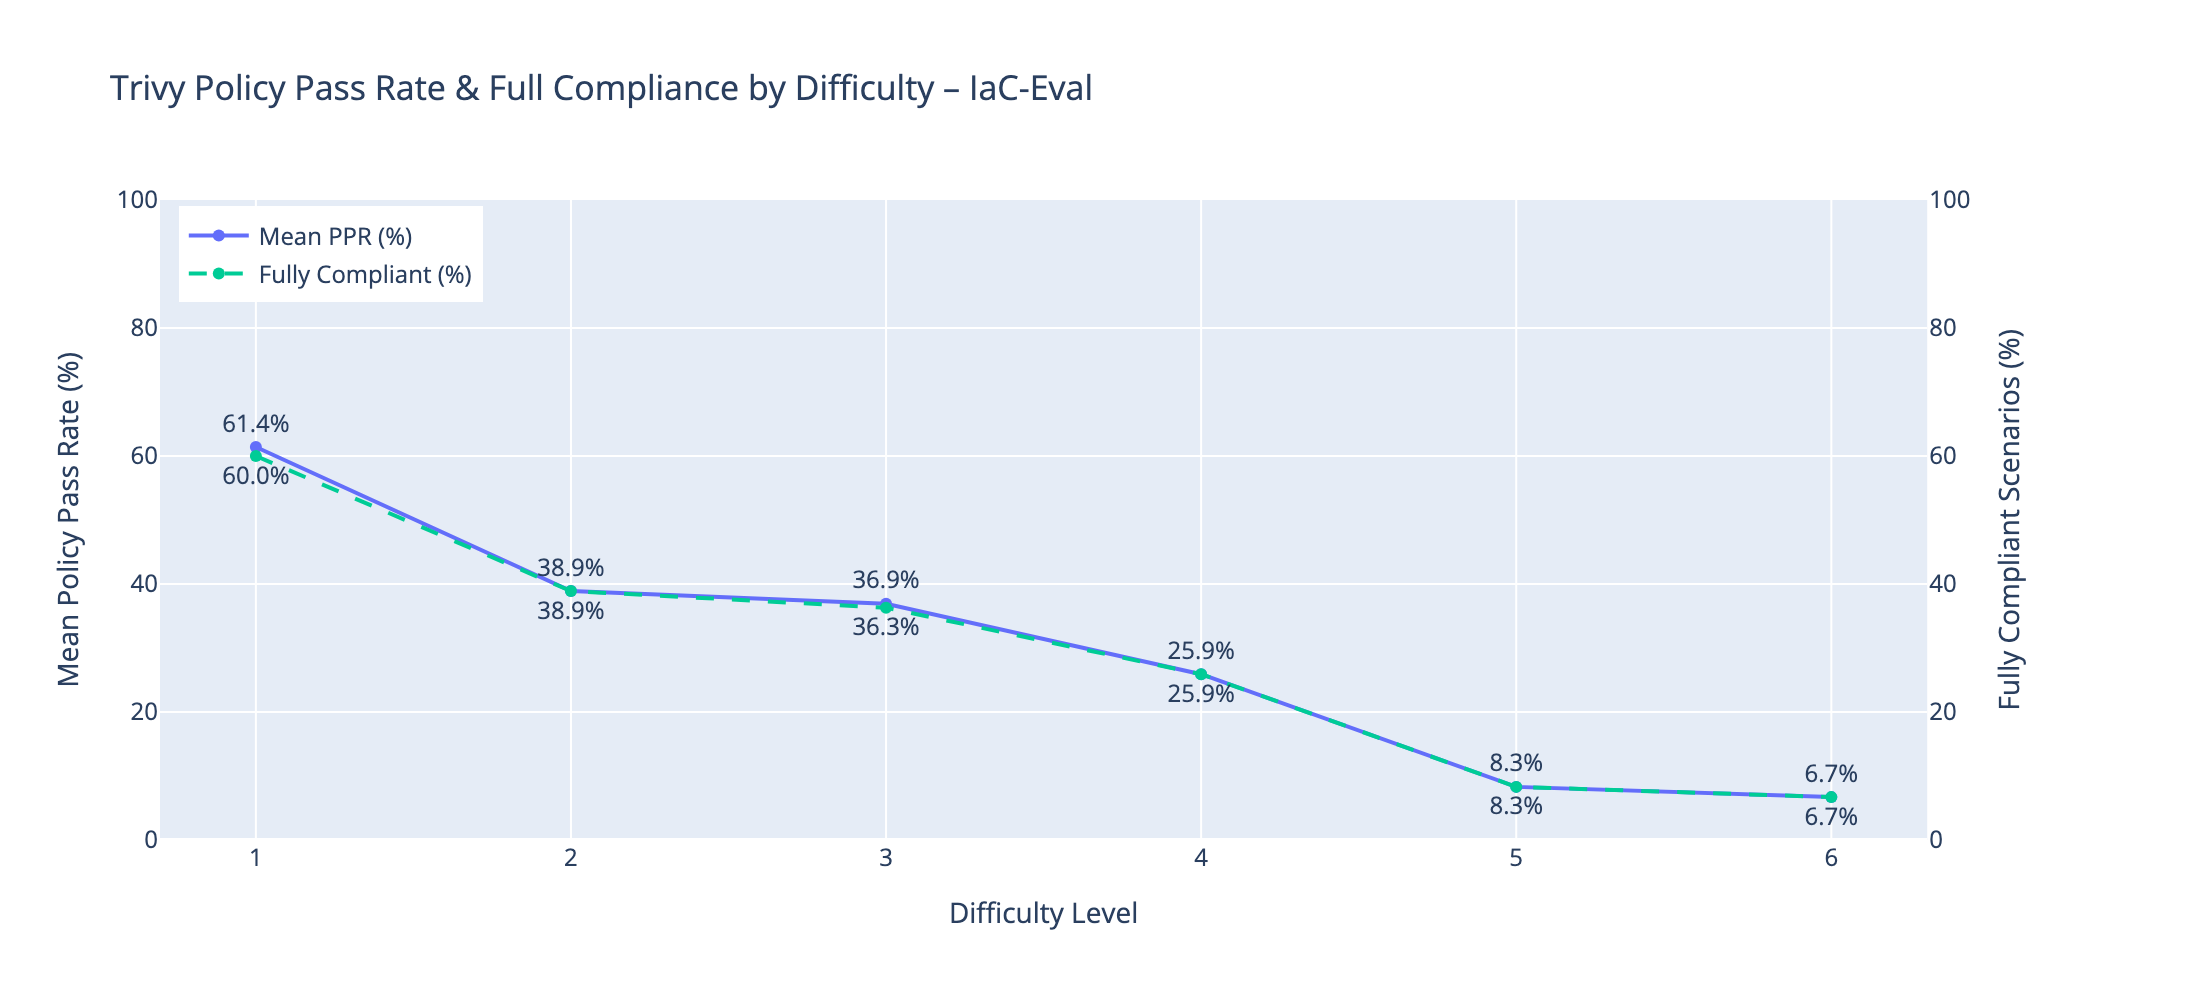

In [34]:
fig_ppr = make_subplots(specs=[[{'secondary_y': True}]])

fig_ppr.add_trace(go.Scatter(
    x=trivy_summary[_DIFF_COL],
    y=trivy_summary['mean_ppr'],
    mode='lines+markers+text',
    text=trivy_summary['mean_ppr'].apply(lambda v: f'{v:.1f}%'),
    textposition='top center',
    name='Mean PPR (%)',
    line=dict(color='#636EFA', width=2),
), secondary_y=False)

fig_ppr.add_trace(go.Scatter(
    x=trivy_summary[_DIFF_COL],
    y=trivy_summary['pct_compliant'],
    mode='lines+markers+text',
    text=trivy_summary['pct_compliant'].apply(lambda v: f'{v:.1f}%'),
    textposition='bottom center',
    name='Fully Compliant (%)',
    line=dict(color='#00CC96', width=2, dash='dash'),
), secondary_y=True)

fig_ppr.update_layout(
    title='Trivy Policy Pass Rate & Full Compliance by Difficulty – IaC-Eval',
    xaxis_title='Difficulty Level',
    legend=dict(x=0.01, y=0.99),
)
fig_ppr.update_yaxes(title_text='Mean Policy Pass Rate (%)', secondary_y=False, range=[0, 100])
fig_ppr.update_yaxes(title_text='Fully Compliant Scenarios (%)', secondary_y=True, range=[0, 100])

fig_ppr.show()

In [35]:
total   = len(df_trivy)
n_with_checks = (df['total_checks'] > 0).sum()

ucr = (df_trivy['failed_checks'] == 0).mean()
fcr = df_trivy.loc[df['total_checks'] > 0, 'failed_checks'].eq(0).mean()
ppr = df_trivy.loc[df['total_checks'] > 0, 'policy_pass_rate'].mean()

print(f"\nCheckov scan complete")
print(f"  Templates scanned                    : {total:,}")
print(f"  Templates with applicable checks     : {n_with_checks:,}  ({n_with_checks/total*100:.1f}%)")
print(f"  Unfiltered Compliance Rate  (UCR)    : {ucr*100:.1f}%   ← denominator: all {total}")
print(f"  Filtered   Compliance Rate  (FCR)    : {fcr*100:.1f}%   ← denominator: {n_with_checks} with checks")
print(f"  Mean Policy Pass Rate       (PPR)    : {ppr*100:.1f}%   ← denominator: {n_with_checks} with checks")
print(f"  Total violations found               : {df['failed_checks'].sum():,}")


Checkov scan complete
  Templates scanned                    : 458
  Templates with applicable checks     : 418  (91.3%)
  Unfiltered Compliance Rate  (UCR)    : 29.3%   ← denominator: all 458
  Filtered   Compliance Rate  (FCR)    : 22.5%   ← denominator: 418 with checks
  Mean Policy Pass Rate       (PPR)    : 22.1%   ← denominator: 418 with checks
  Total violations found               : 3,244


## Unified — all sources (IaC-Eval + Multi-IaC-Eval, CFN + TF)

In [36]:
SEVERITY_COLS = ['severity_critical', 'severity_high', 'severity_medium', 'severity_low', 'severity_info', 'severity_unknown']

def _agg_tool_stats(df_scan: pd.DataFrame, tool_name: str) -> pd.DataFrame:
    merged = df_unified[['scenario_id', 'source', 'language']].merge(df_scan, on='scenario_id', how='left')
    for col in SEVERITY_COLS + ['total_checks', 'passed_checks', 'failed_checks']:
        if col not in merged.columns:
            merged[col] = 0
    merged[SEVERITY_COLS + ['total_checks', 'passed_checks', 'failed_checks']] = (
        merged[SEVERITY_COLS + ['total_checks', 'passed_checks', 'failed_checks']].fillna(0)
    )
    agg = merged.groupby(['source', 'language']).agg(
        n_scenarios=('scenario_id', 'count'),
        checks_processed=('total_checks', 'sum'),
        checks_passed=('passed_checks', 'sum'),
        checks_failed=('failed_checks', 'sum'),
        **{c: (c, 'sum') for c in SEVERITY_COLS},
    ).reset_index()
    agg['pass_rate_pct'] = (agg['checks_passed'] / agg['checks_processed'].replace(0, pd.NA) * 100).round(1)
    agg.insert(0, 'tool', tool_name)
    return agg

checks_summary = pd.concat([
    _agg_tool_stats(df_trivy_all, 'Trivy'),
    _agg_tool_stats(df_checkov_all, 'Checkov'),
], ignore_index=True)

int_cols = ['n_scenarios', 'checks_processed', 'checks_passed', 'checks_failed'] + SEVERITY_COLS
checks_summary[int_cols] = checks_summary[int_cols].astype(int)

print("=== Checks processed vs passed, by tool + source/language ===")
print(checks_summary[['tool', 'source', 'language', 'n_scenarios', 'checks_processed',
                       'checks_passed', 'checks_failed', 'pass_rate_pct']].to_string(index=False))
print("\n=== ...and the failed-check counts broken down by severity ===")
print(checks_summary[['tool', 'source', 'language'] + SEVERITY_COLS].to_string(index=False))

checks_summary.to_csv(CACHE_DIR / 'checks_processed_by_severity.csv', index=False)
print(f"\nSaved → {CACHE_DIR / 'checks_processed_by_severity.csv'}")

=== Checks processed vs passed, by tool + source/language ===
   tool                       source       language  n_scenarios  checks_processed  checks_passed  checks_failed  pass_rate_pct
  Trivy AmazonScience/Multi-IaC-Eval cloudformation          176              5804           5239            565           90.3
  Trivy AmazonScience/Multi-IaC-Eval      terraform          223              7158           6750            408           94.3
  Trivy     autoiac-project/iac-eval      terraform          369              7283           5560           1723           76.3
Checkov AmazonScience/Multi-IaC-Eval cloudformation          176              2029           1636            393           80.6
Checkov AmazonScience/Multi-IaC-Eval      terraform          223              1307            817            490           62.5
Checkov     autoiac-project/iac-eval      terraform          369              6111           3550           2561           58.1

=== ...and the failed-check counts broken

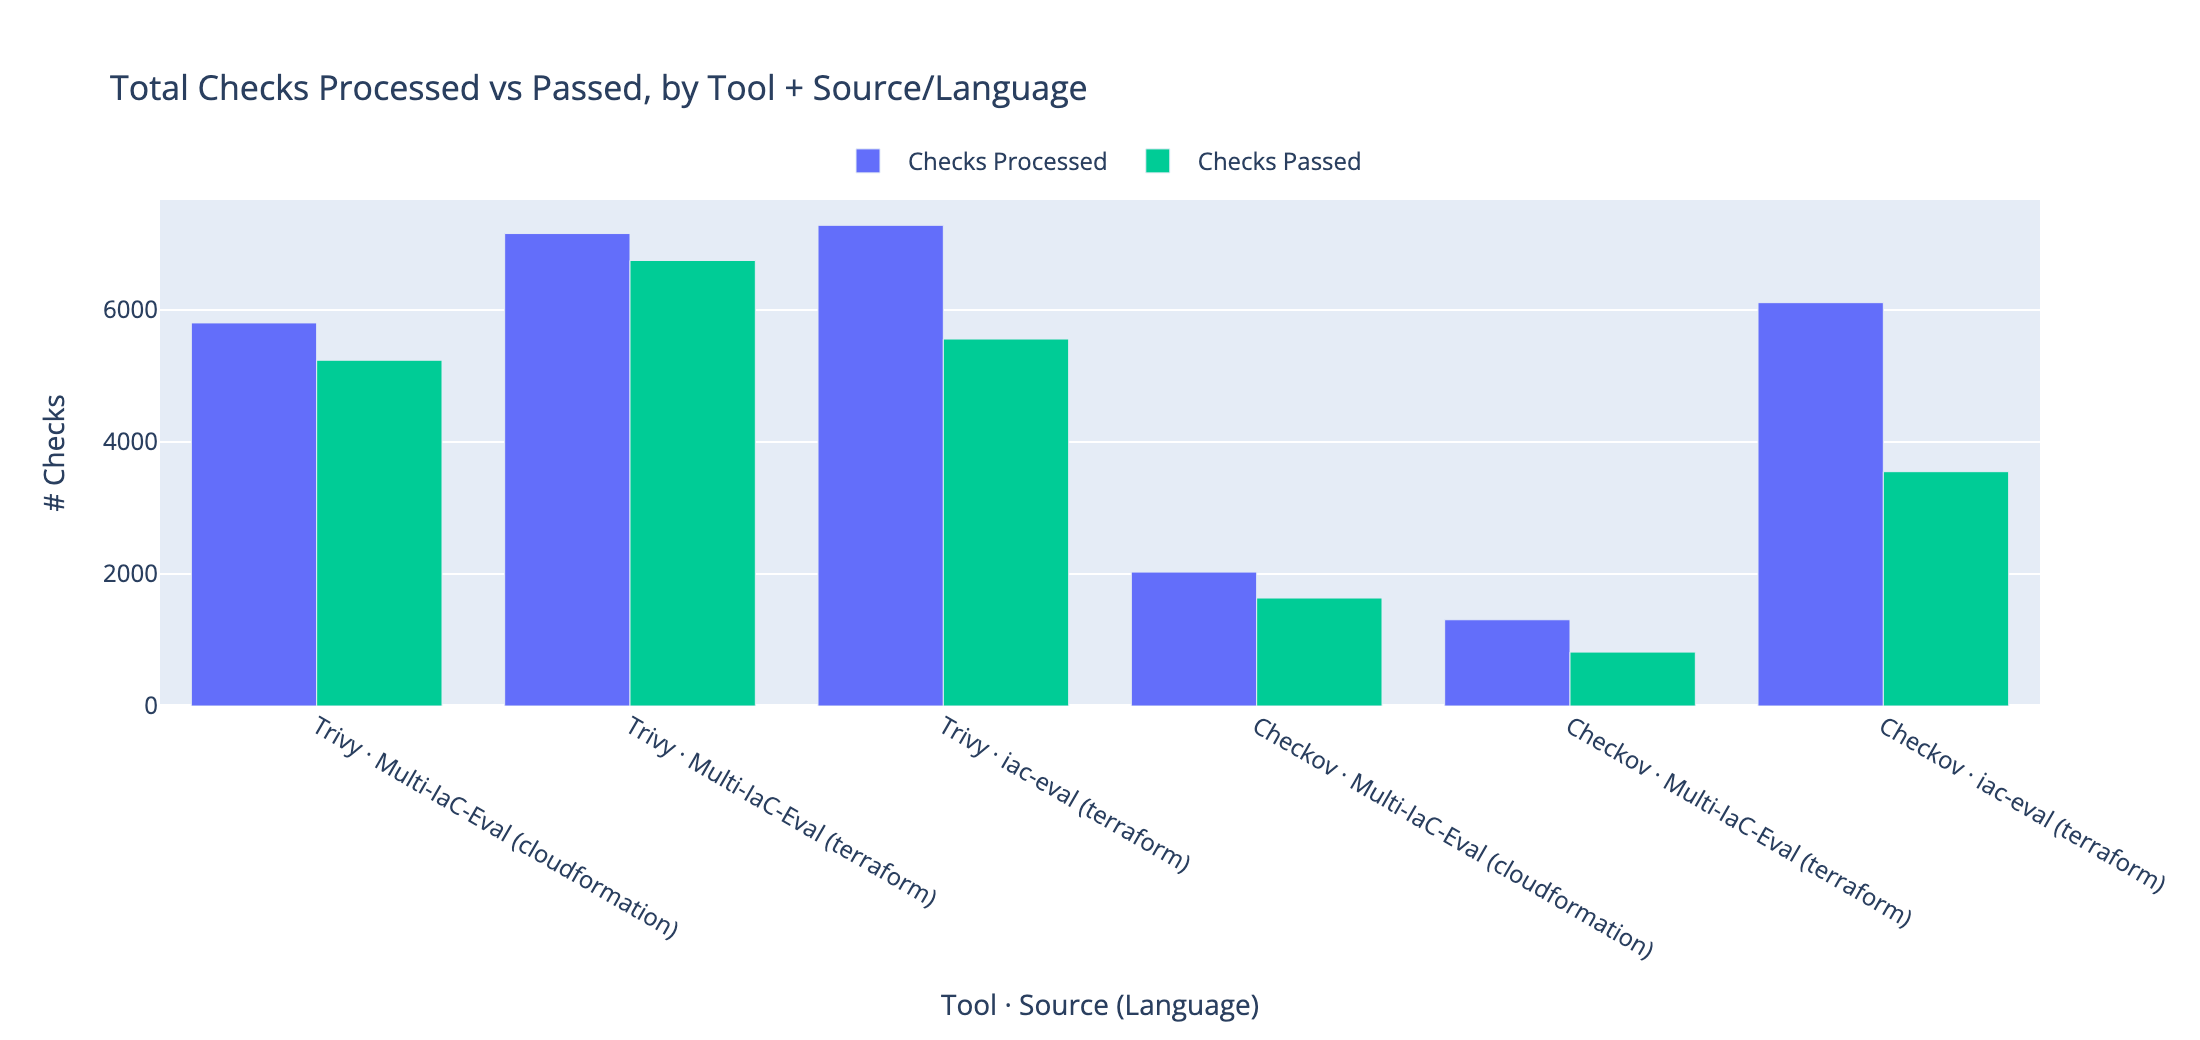

In [37]:
_checks_labels = checks_summary.apply(
    lambda r: f"{r['tool']} · {r['source'].split('/')[-1]} ({r['language']})", axis=1,
)
fig_checks_bar = go.Figure()
fig_checks_bar.add_trace(go.Bar(name='Checks Processed', x=_checks_labels, y=checks_summary['checks_processed'], marker_color='#636EFA'))
fig_checks_bar.add_trace(go.Bar(name='Checks Passed', x=_checks_labels, y=checks_summary['checks_passed'], marker_color='#00CC96'))
fig_checks_bar.update_layout(
    barmode='group',
    title='Total Checks Processed vs Passed, by Tool + Source/Language',
    xaxis_title='Tool · Source (Language)', yaxis_title='# Checks',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='center', x=0.5),
    height=520,
)
fig_checks_bar.show()

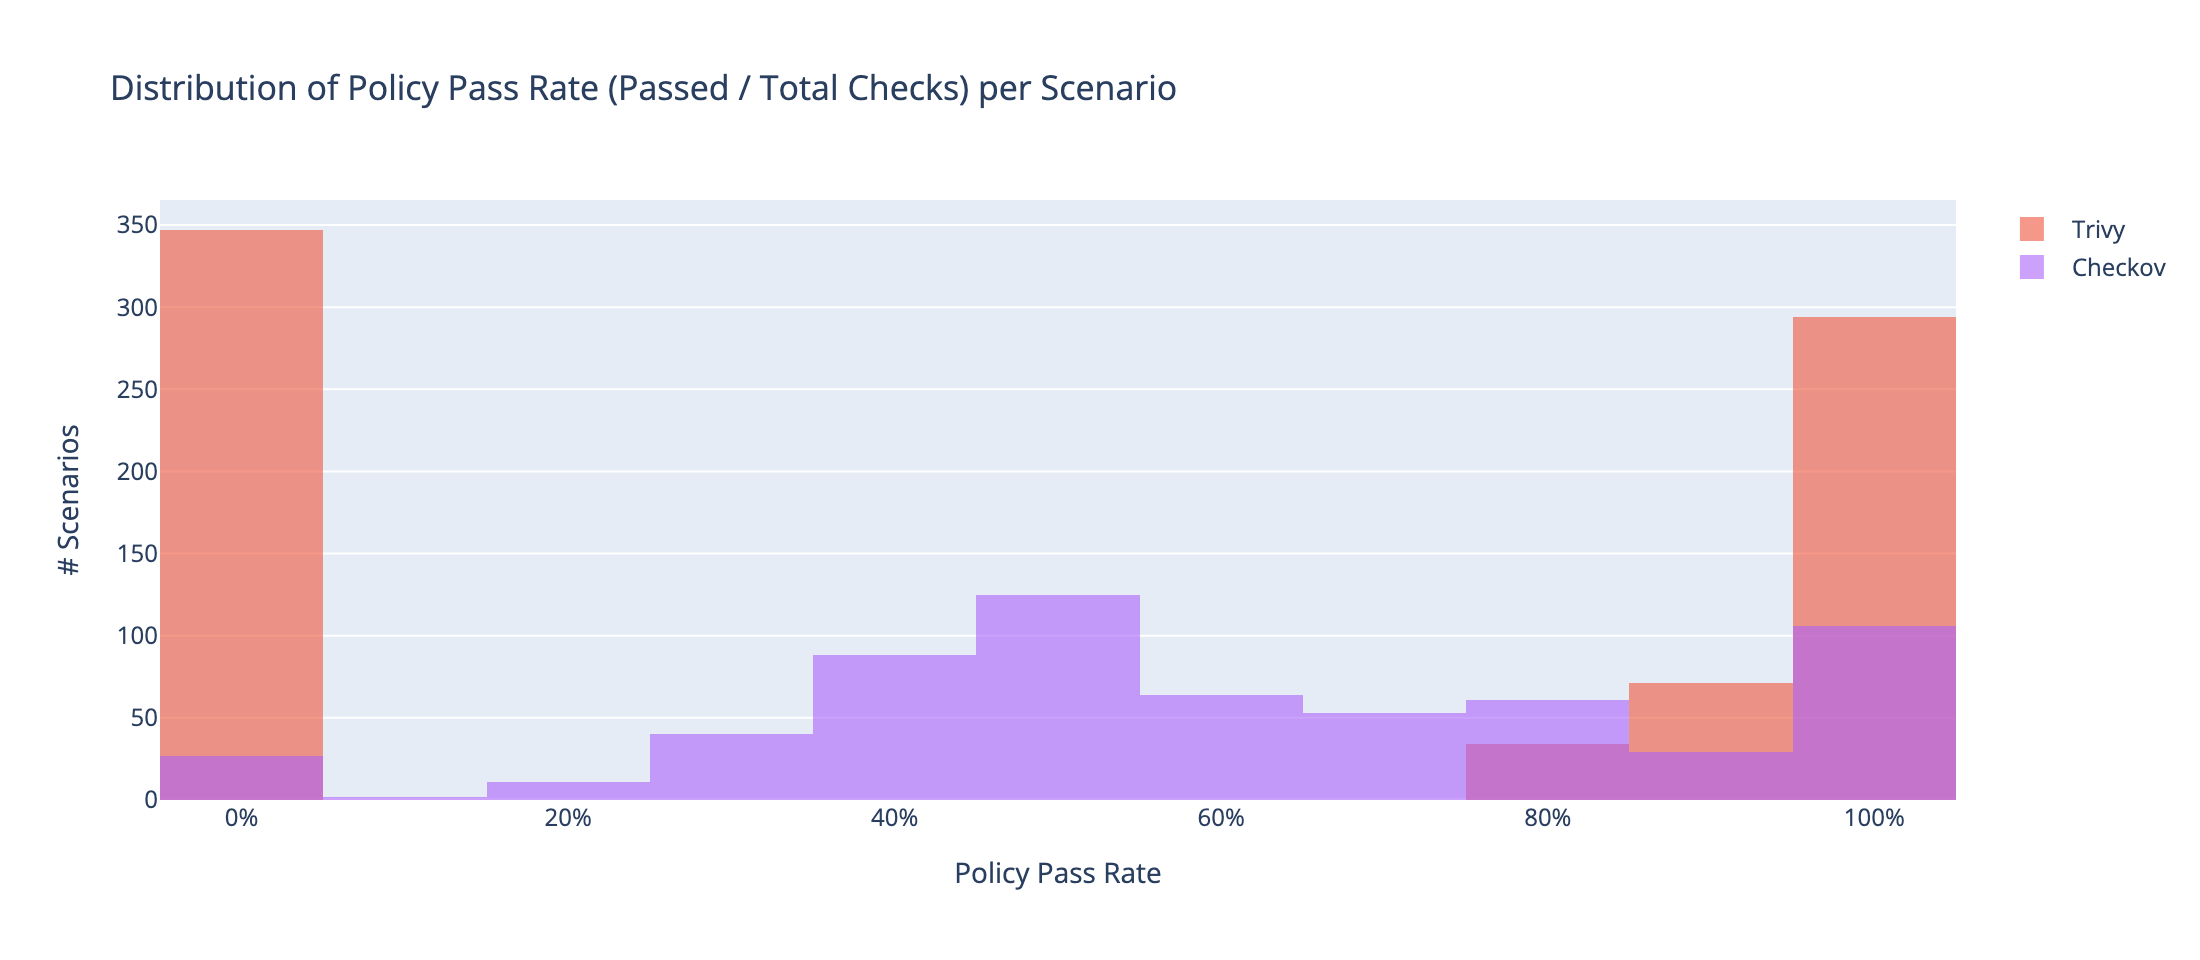

Trivy scenarios with applicable checks   : 746 / 768   (median pass rate 83.3%)
Checkov scenarios with applicable checks : 606 / 768   (median pass rate 57.1%)


In [38]:
_trivy_rates = df_trivy_all[df_trivy_all['total_checks'] > 0].copy()
_trivy_rates['pass_rate'] = _trivy_rates['passed_checks'] / _trivy_rates['total_checks']
_checkov_rates = df_checkov_all[df_checkov_all['total_checks'] > 0].copy()
_checkov_rates['pass_rate'] = _checkov_rates['passed_checks'] / _checkov_rates['total_checks']

fig_passrate_dist = go.Figure()
fig_passrate_dist.add_trace(go.Histogram(x=_trivy_rates['pass_rate'], name='Trivy', opacity=0.6, nbinsx=20, marker_color='#EF553B'))
fig_passrate_dist.add_trace(go.Histogram(x=_checkov_rates['pass_rate'], name='Checkov', opacity=0.6, nbinsx=20, marker_color='#AB63FA'))
fig_passrate_dist.update_layout(
    barmode='overlay',
    title='Distribution of Policy Pass Rate (Passed / Total Checks) per Scenario',
    xaxis_title='Policy Pass Rate', yaxis_title='# Scenarios',
    xaxis_tickformat='.0%', height=480,
)
fig_passrate_dist.show()

print(f"Trivy scenarios with applicable checks   : {len(_trivy_rates):,} / {len(df_trivy_all):,}   "
      f"(median pass rate {_trivy_rates['pass_rate'].median()*100:.1f}%)")
print(f"Checkov scenarios with applicable checks : {len(_checkov_rates):,} / {len(df_checkov_all):,}   "
      f"(median pass rate {_checkov_rates['pass_rate'].median()*100:.1f}%)")

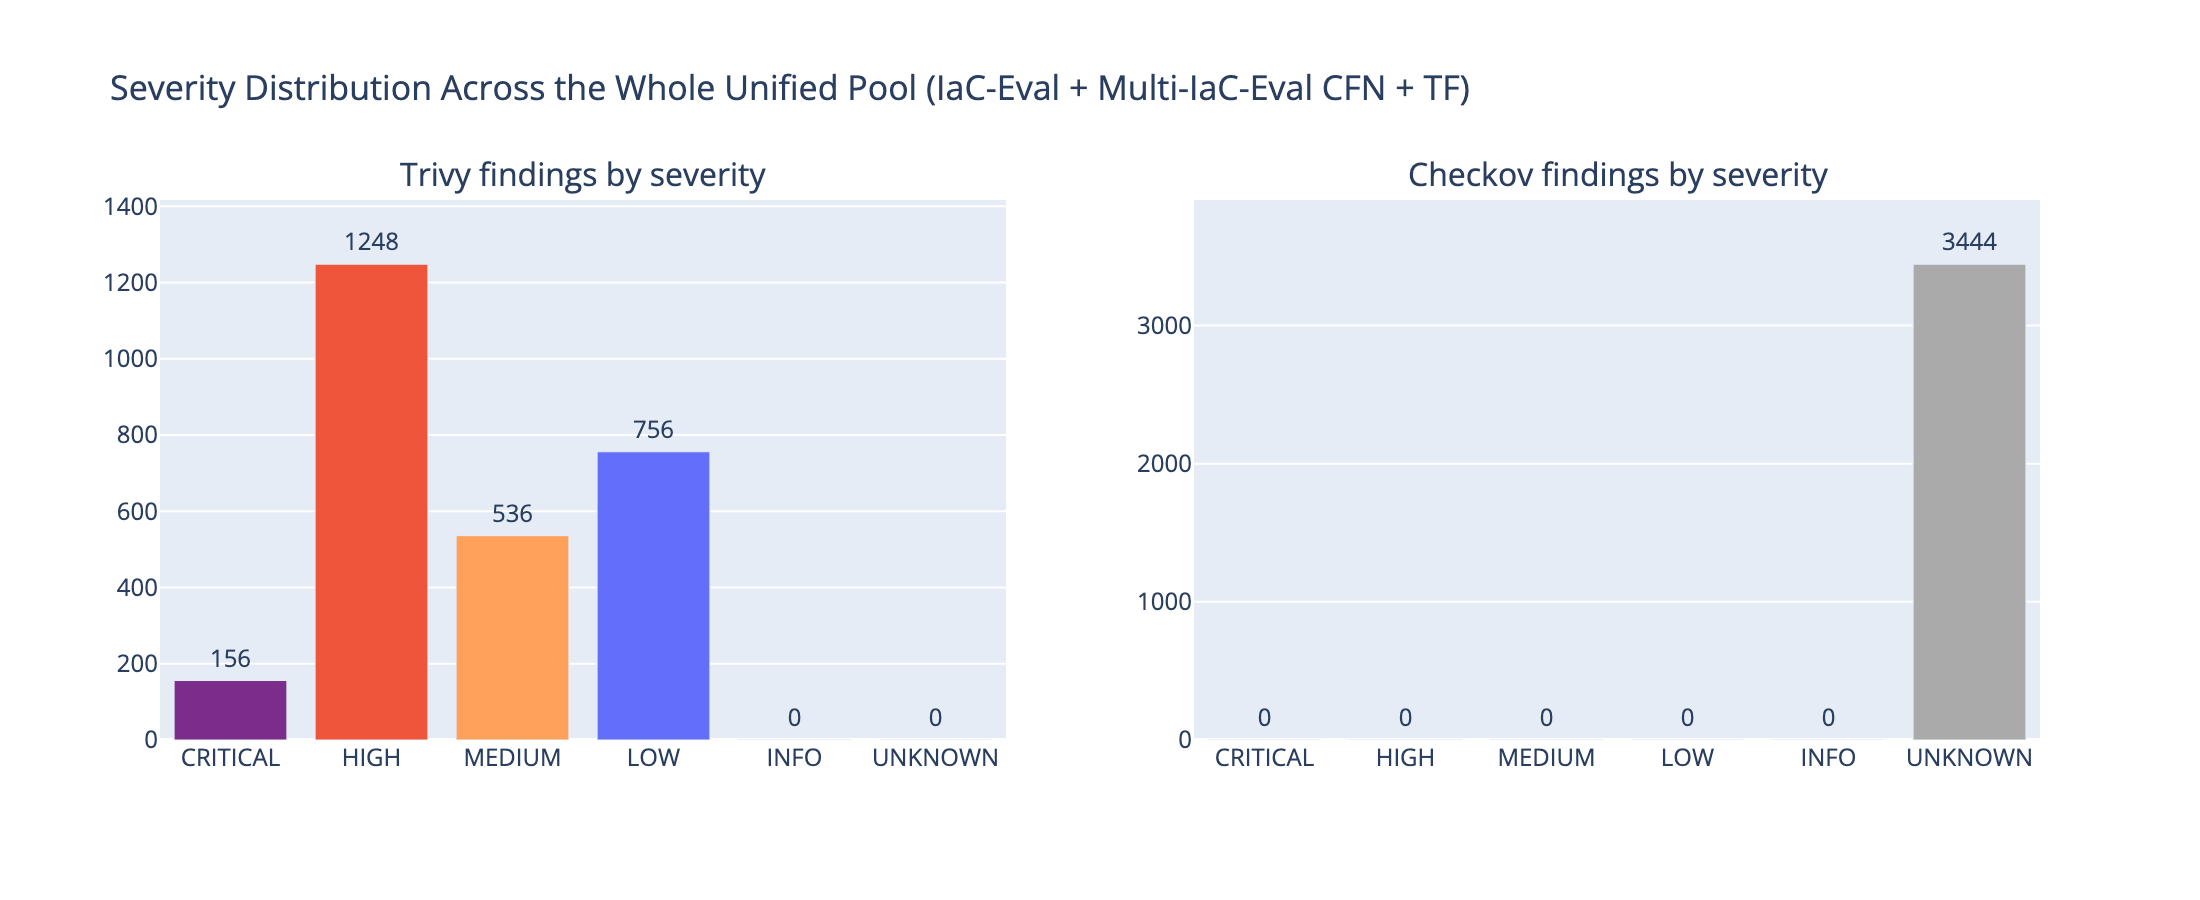

In [39]:
sev_labels = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'INFO', 'UNKNOWN']
sev_colors = {'CRITICAL': '#7B2D8B', 'HIGH': '#EF553B', 'MEDIUM': '#FFA15A',
              'LOW': '#636EFA', 'INFO': '#AEC7E8', 'UNKNOWN': '#AAAAAA'}

fig_sev_ext = make_subplots(
    rows=1, cols=2, subplot_titles=('Trivy findings by severity', 'Checkov findings by severity'),
)
for col_idx, tool_name in [(1, 'Trivy'), (2, 'Checkov')]:
    tool_totals = checks_summary[checks_summary['tool'] == tool_name][SEVERITY_COLS].sum()
    fig_sev_ext.add_trace(go.Bar(
        x=sev_labels,
        y=[tool_totals[f'severity_{s.lower()}'] for s in sev_labels],
        marker_color=[sev_colors[s] for s in sev_labels],
        text=[int(tool_totals[f'severity_{s.lower()}']) for s in sev_labels],
        textposition='outside',
        showlegend=False,
    ), row=1, col=col_idx)

fig_sev_ext.update_layout(
    title='Severity Distribution Across the Whole Unified Pool (IaC-Eval + Multi-IaC-Eval CFN + TF)',
    height=450,
)
fig_sev_ext.show()

=== Lint validity rate (cfn-lint / TFLint), by source/language ===
                      source       language   n  lint_pass_n  lint_pass_pct
AmazonScience/Multi-IaC-Eval cloudformation 176           72           40.9
AmazonScience/Multi-IaC-Eval      terraform 223          223          100.0
    autoiac-project/iac-eval      terraform 369          369          100.0


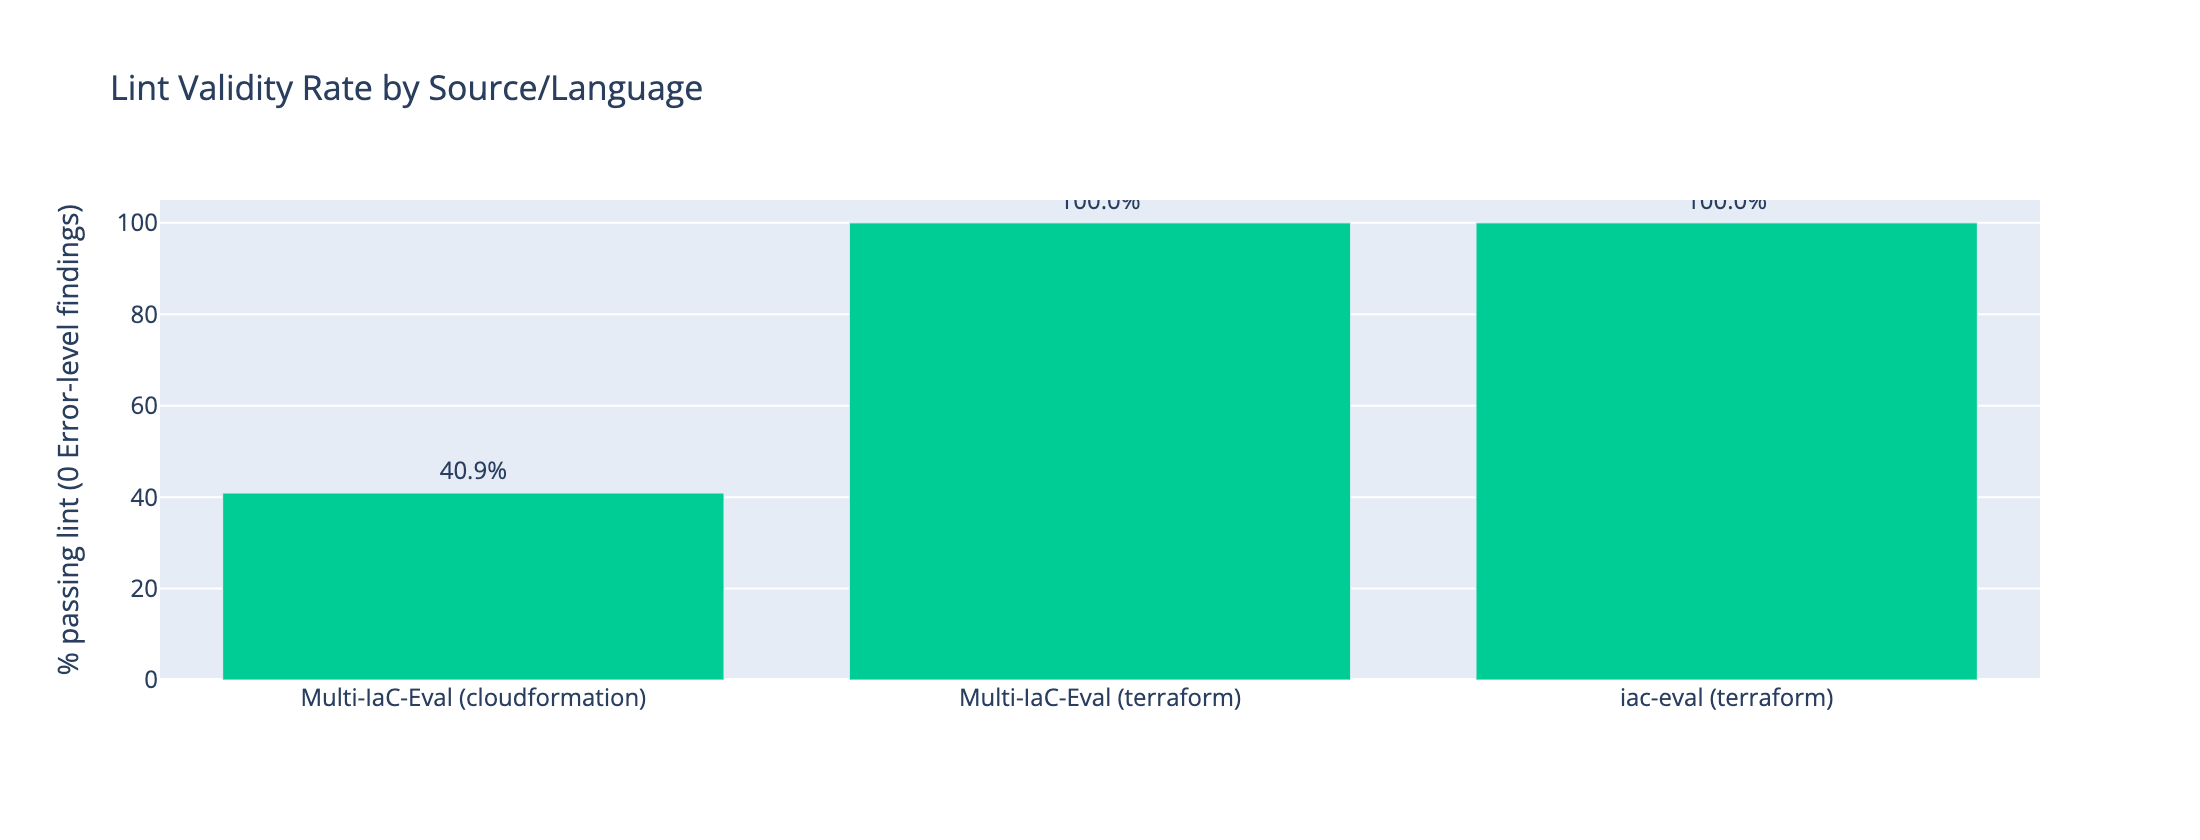

In [40]:
lint_joined = df_unified[['scenario_id', 'source', 'language']].merge(
    df_lint_all[['scenario_id', 'lint_pass']], on='scenario_id', how='left',
)
lint_summary = lint_joined.groupby(['source', 'language']).agg(
    n=('scenario_id', 'count'),
    lint_pass_n=('lint_pass', lambda s: (s == True).sum()),
    lint_pass_pct=('lint_pass', lambda s: pd.to_numeric(s, errors='coerce').mean() * 100),
).reset_index()
lint_summary['lint_pass_pct'] = lint_summary['lint_pass_pct'].round(1)
lint_summary['label'] = lint_summary.apply(lambda r: f"{r['source'].split('/')[-1]} ({r['language']})", axis=1)

print("=== Lint validity rate (cfn-lint / TFLint), by source/language ===")
print(lint_summary[['source', 'language', 'n', 'lint_pass_n', 'lint_pass_pct']].to_string(index=False))

fig_lint_ext = go.Figure(go.Bar(
    x=lint_summary['label'], y=lint_summary['lint_pass_pct'],
    text=lint_summary['lint_pass_pct'].apply(lambda v: f'{v:.1f}%'), textposition='outside',
    marker_color='#00CC96',
))
fig_lint_ext.update_layout(
    title='Lint Validity Rate by Source/Language',
    yaxis_title='% passing lint (0 Error-level findings)', yaxis_range=[0, 105], height=420,
)
fig_lint_ext.show()

=== Security pass rate — scenarios with no findings / no critical+high findings, per benchmark ===
   tool                       benchmark  n_scenarios  no_findings  pct_no_findings  findings_but_no_crit_high  has_crit_high  pct_no_crit_high
  Trivy Multi-IaC-Eval (cloudformation)          176           24             13.6                         40            112              36.4
  Trivy      Multi-IaC-Eval (terraform)          223          131             58.7                         16             76              65.9
  Trivy            iac-eval (terraform)          369          108             29.3                         51            210              43.1
Checkov Multi-IaC-Eval (cloudformation)          176           24             13.6                        152              0             100.0
Checkov      Multi-IaC-Eval (terraform)          223           21              9.4                        202              0             100.0
Checkov            iac-eval (terraform)    

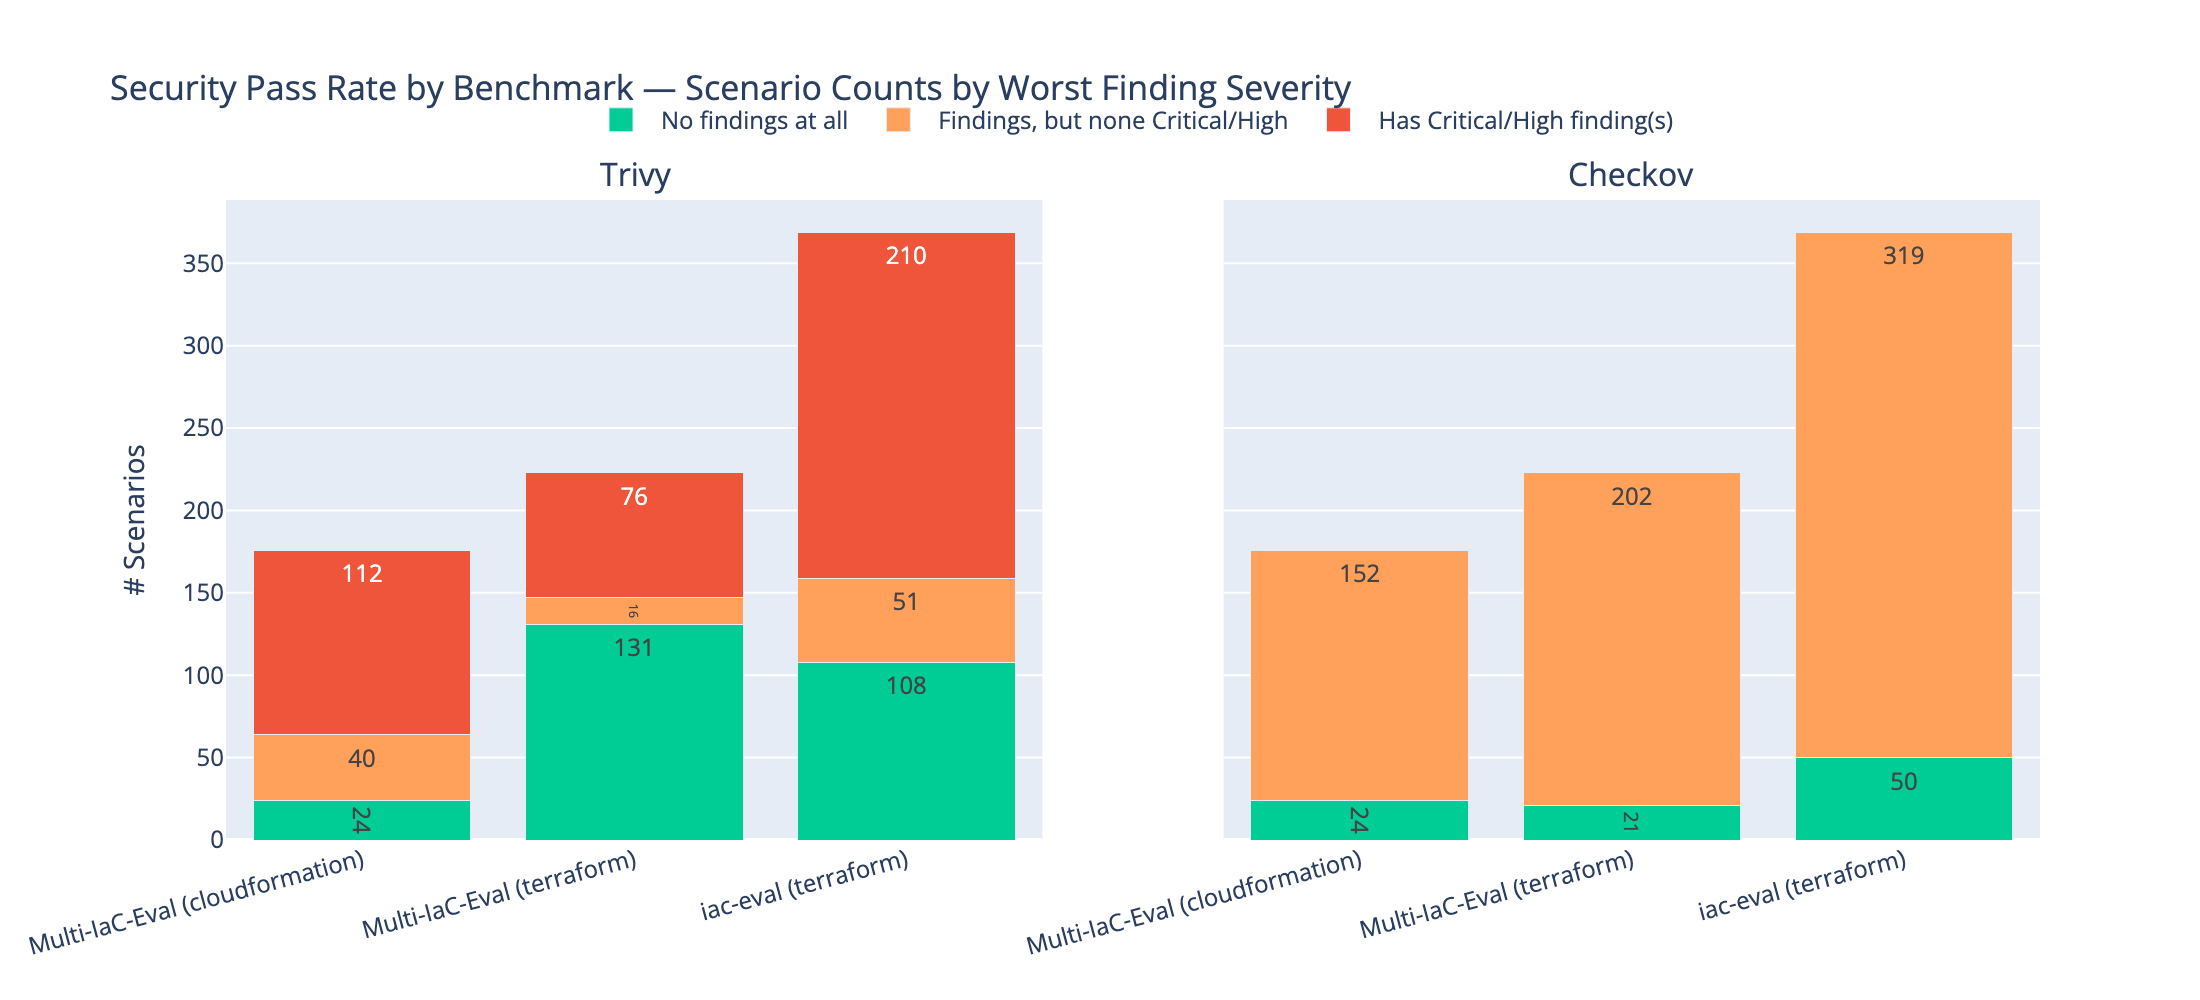

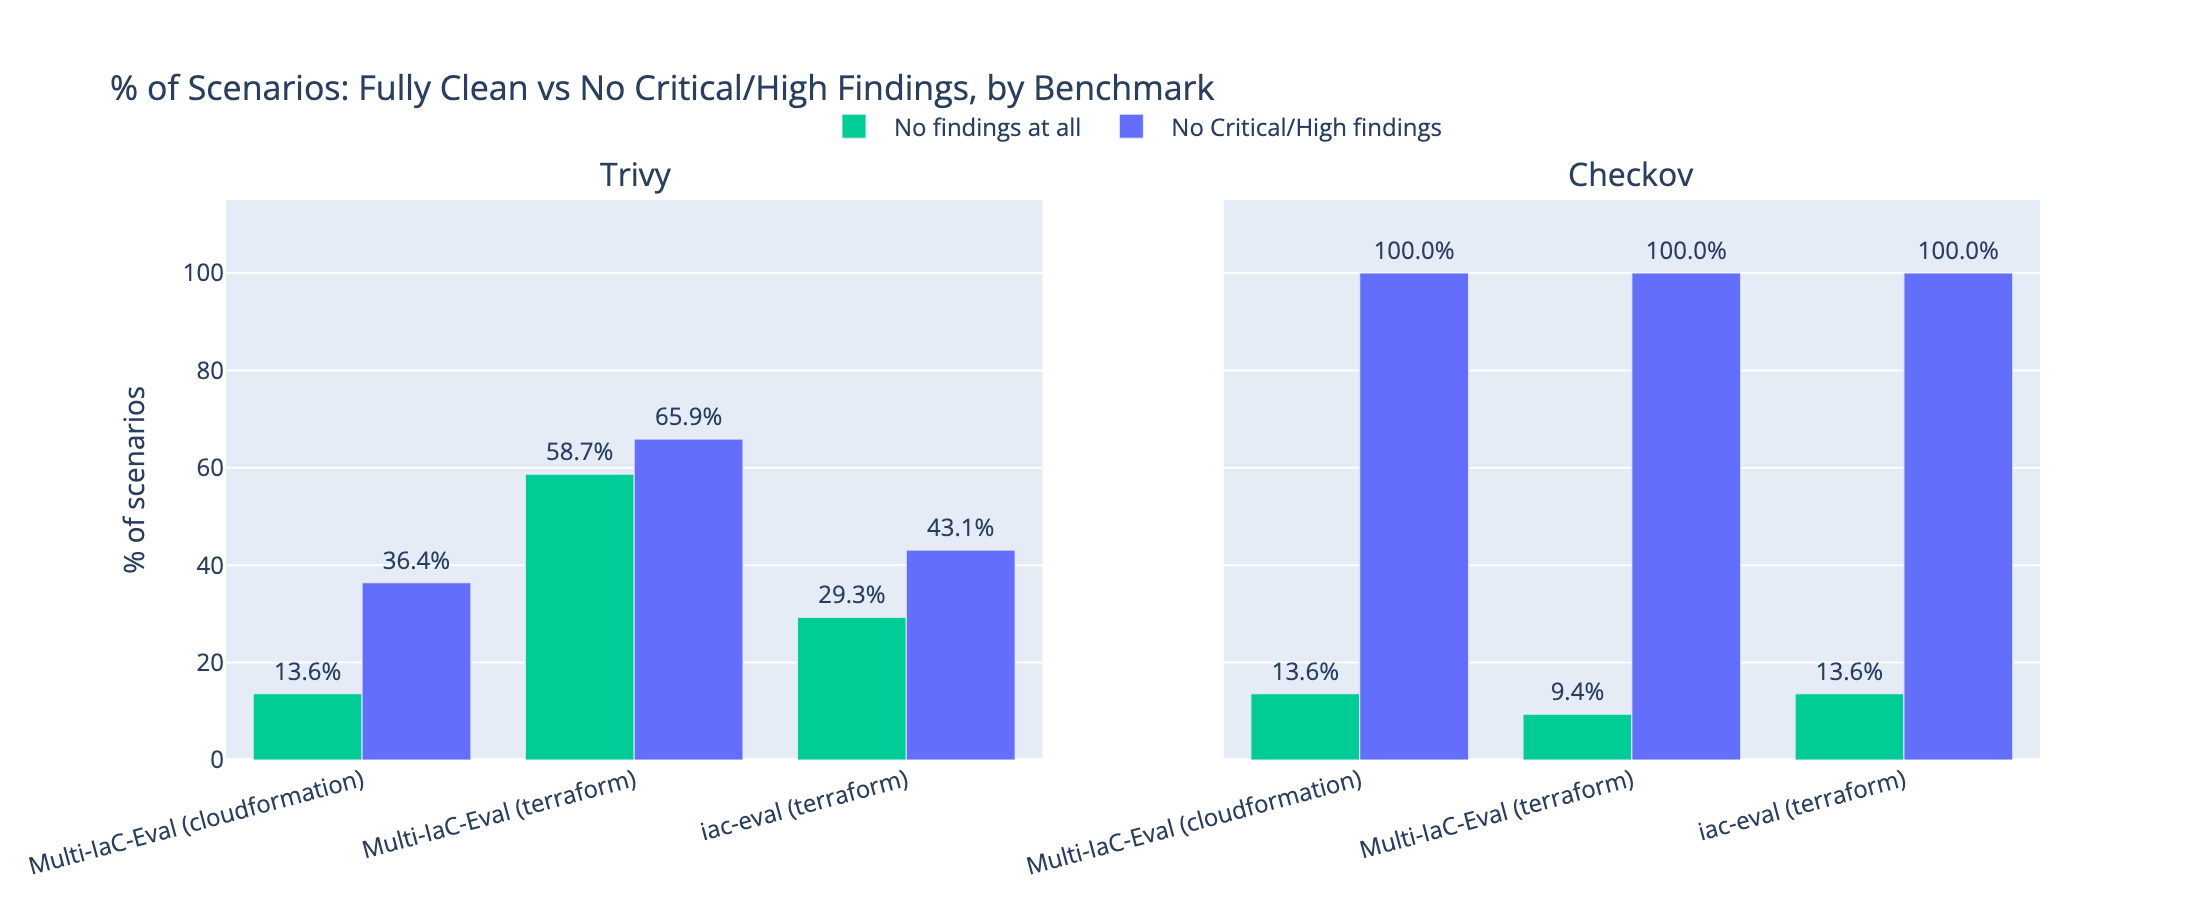


Saved -> output/benchmark_security_audit/security_passrate_summary.csv


In [41]:
def _compliance_breakdown_by_source(df_scan: pd.DataFrame, tool_name: str) -> pd.DataFrame:
    merged = df_unified[['scenario_id', 'source', 'language']].merge(df_scan, on='scenario_id', how='inner')
    rows = []
    for (src, lang), g in merged.groupby(['source', 'language']):
        n = len(g)
        no_findings = int(g['filtered_compliance'].astype(bool).sum())
        no_crit_high = int(((g['severity_critical'] == 0) & (g['severity_high'] == 0)).sum())
        findings_but_no_crit_high = no_crit_high - no_findings
        has_crit_high = n - no_crit_high
        rows.append({
            'tool': tool_name, 'source': src, 'language': lang, 'n_scenarios': n,
            'no_findings': no_findings,
            'findings_but_no_crit_high': findings_but_no_crit_high,
            'has_crit_high': has_crit_high,
        })
    return pd.DataFrame(rows)

compliance_summary = pd.concat([
    _compliance_breakdown_by_source(df_trivy_all, 'Trivy'),
    _compliance_breakdown_by_source(df_checkov_all, 'Checkov'),
], ignore_index=True)
compliance_summary['benchmark'] = compliance_summary.apply(
    lambda r: f"{r['source'].split('/')[-1]} ({r['language']})", axis=1,
)
compliance_summary['pct_no_findings'] = (
    compliance_summary['no_findings'] / compliance_summary['n_scenarios'] * 100
).round(1)
compliance_summary['pct_no_crit_high'] = (
    (compliance_summary['no_findings'] + compliance_summary['findings_but_no_crit_high'])
    / compliance_summary['n_scenarios'] * 100
).round(1)

print("=== Security pass rate — scenarios with no findings / no critical+high findings, per benchmark ===")
print(compliance_summary[['tool', 'benchmark', 'n_scenarios', 'no_findings', 'pct_no_findings',
                           'findings_but_no_crit_high', 'has_crit_high', 'pct_no_crit_high']]
      .to_string(index=False))
print("\n⚠️  Checkov's severity fields are a known no-op in this environment (open-source "
      "Checkov 3.2.513 never populates severity on failed checks -- confirmed empirically "
      "against real CFN and TF templates, 100% null/0). Its 'no critical/high' figures above "
      "are therefore trivially 100% and should NOT be read as 'Checkov found nothing severe' "
      "-- it never tags severity at all. Trivy's severity_critical/high ARE genuinely populated "
      "and are the only trustworthy severity signal in this notebook; lean on Trivy's numbers "
      "for anything severity-weighted, and treat Checkov's 'findings vs no findings' split "
      "(total_checks/failed_checks) as its own useful signal instead.")

_benchmarks = sorted(compliance_summary['benchmark'].unique())
fig_compliance = make_subplots(
    rows=1, cols=2, subplot_titles=('Trivy', 'Checkov'), shared_yaxes=True,
)
_bucket_colors = {
    'no_findings': '#00CC96', 'findings_but_no_crit_high': '#FFA15A', 'has_crit_high': '#EF553B',
}
_bucket_labels = {
    'no_findings': 'No findings at all',
    'findings_but_no_crit_high': 'Findings, but none Critical/High',
    'has_crit_high': 'Has Critical/High finding(s)',
}
for col_idx, tool_name in [(1, 'Trivy'), (2, 'Checkov')]:
    sub = compliance_summary[compliance_summary['tool'] == tool_name].set_index('benchmark').reindex(_benchmarks)
    for bucket in ['no_findings', 'findings_but_no_crit_high', 'has_crit_high']:
        fig_compliance.add_trace(go.Bar(
            name=_bucket_labels[bucket], x=_benchmarks, y=sub[bucket],
            marker_color=_bucket_colors[bucket], text=sub[bucket], textposition='inside',
            showlegend=(col_idx == 1),
            legendgroup=bucket,
        ), row=1, col=col_idx)

fig_compliance.update_layout(
    barmode='stack',
    title='Security Pass Rate by Benchmark — Scenario Counts by Worst Finding Severity',
    yaxis_title='# Scenarios', height=500,
    legend=dict(orientation='h', yanchor='bottom', y=1.08, xanchor='center', x=0.5),
)
fig_compliance.update_xaxes(tickangle=-15)
fig_compliance.show()

fig_clean_rate = make_subplots(rows=1, cols=2, subplot_titles=('Trivy', 'Checkov'), shared_yaxes=True)
for col_idx, tool_name in [(1, 'Trivy'), (2, 'Checkov')]:
    sub = compliance_summary[compliance_summary['tool'] == tool_name].set_index('benchmark').reindex(_benchmarks)
    fig_clean_rate.add_trace(go.Bar(
        name='No findings at all', x=_benchmarks, y=sub['pct_no_findings'], marker_color='#00CC96',
        text=sub['pct_no_findings'].apply(lambda v: f'{v:.1f}%'), textposition='outside',
        showlegend=(col_idx == 1), legendgroup='no_findings',
    ), row=1, col=col_idx)
    fig_clean_rate.add_trace(go.Bar(
        name='No Critical/High findings', x=_benchmarks, y=sub['pct_no_crit_high'], marker_color='#636EFA',
        text=sub['pct_no_crit_high'].apply(lambda v: f'{v:.1f}%'), textposition='outside',
        showlegend=(col_idx == 1), legendgroup='no_crit_high',
    ), row=1, col=col_idx)

fig_clean_rate.update_layout(
    barmode='group',
    title='% of Scenarios: Fully Clean vs No Critical/High Findings, by Benchmark',
    yaxis_title='% of scenarios', yaxis_range=[0, 115], height=460,
    legend=dict(orientation='h', yanchor='bottom', y=1.08, xanchor='center', x=0.5),
)
fig_clean_rate.update_xaxes(tickangle=-15)
fig_clean_rate.show()

compliance_summary.to_csv(CACHE_DIR / 'security_passrate_summary.csv', index=False)
print(f"\nSaved -> {CACHE_DIR / 'security_passrate_summary.csv'}")

## Deployable rate (real-AWS)

=== Deployable rate (real AWS), by source/language ===
                      source       language  n_total  n_tested  deploy_pass_n  deploy_pass_pct_of_tested
AmazonScience/Multi-IaC-Eval cloudformation      176       176             22                       12.5
AmazonScience/Multi-IaC-Eval      terraform      223       223             41                       18.4
    autoiac-project/iac-eval      terraform      369       369             70                       19.0


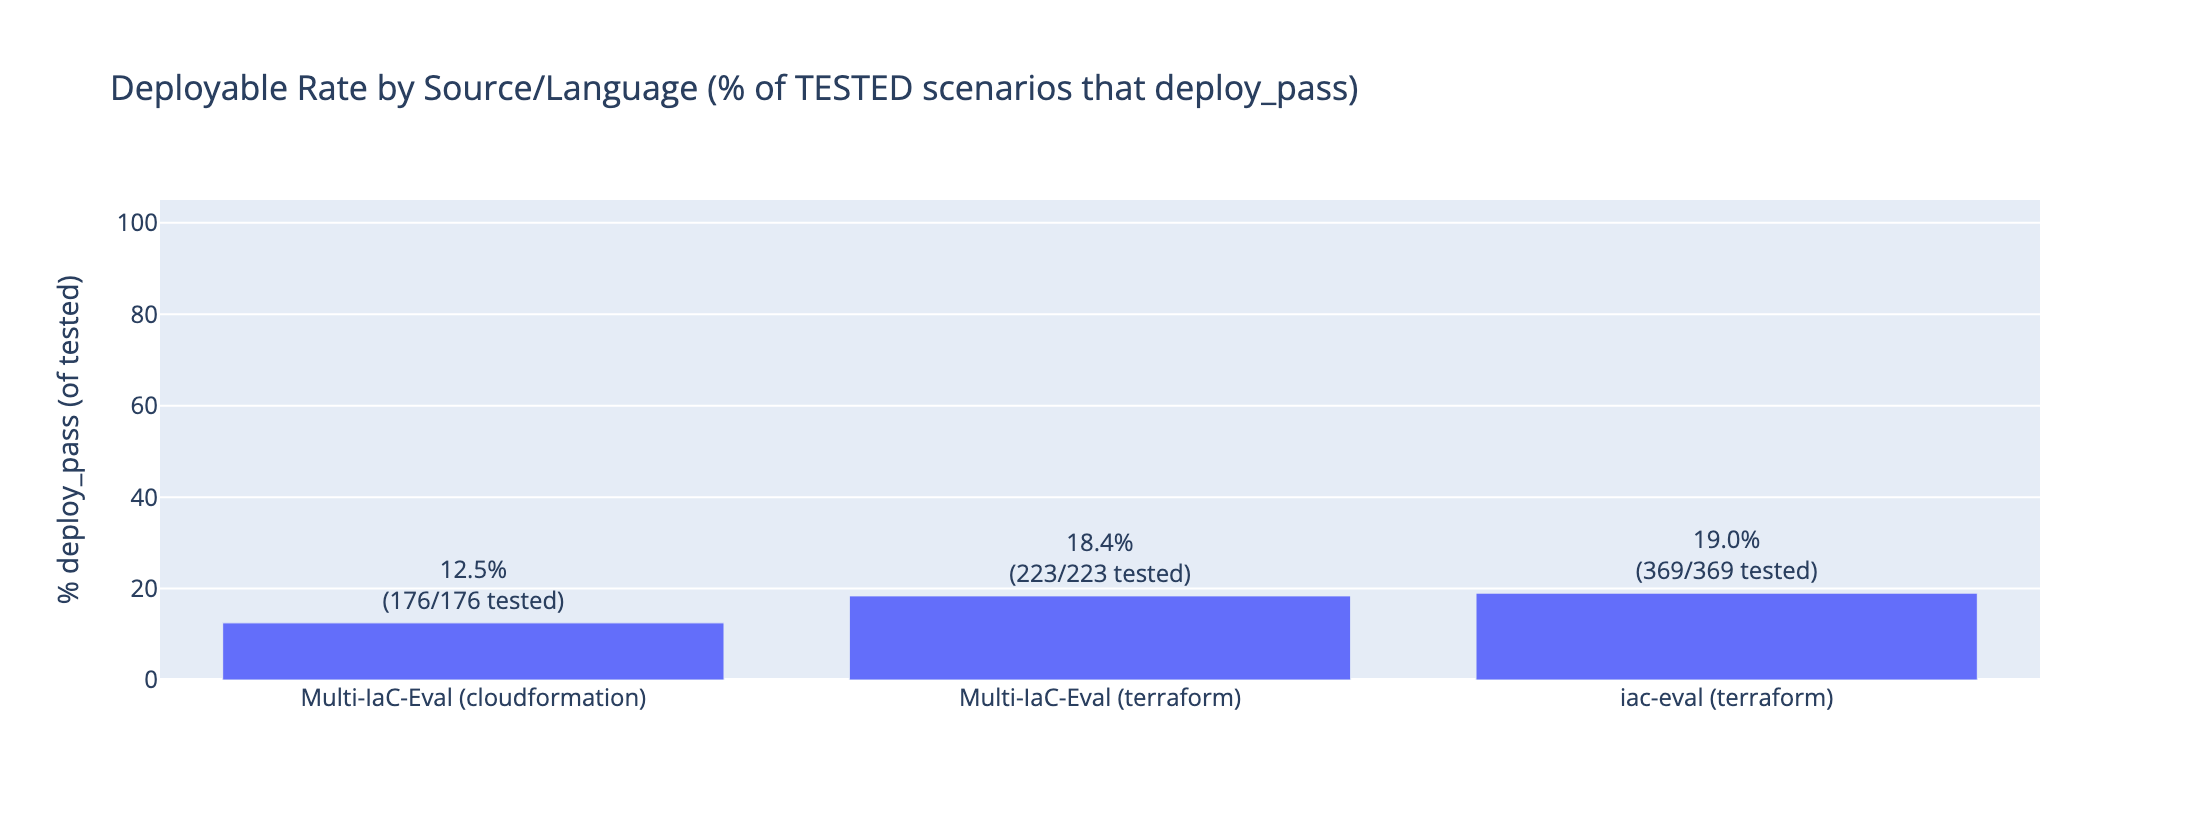

In [42]:
_DEPLOY_CACHE_PATH = CACHE_DIR / 'deploy_cache.csv'

if _DEPLOY_CACHE_PATH.exists() and len(pd.read_csv(_DEPLOY_CACHE_PATH)) > 0:
    dc = pd.read_csv(_DEPLOY_CACHE_PATH)
    dc_joined = df_unified[['scenario_id', 'source', 'language']].merge(dc, on='scenario_id', how='left')
    deploy_summary = dc_joined.groupby(['source', 'language']).agg(
        n_total=('scenario_id', 'count'),
        n_tested=('deploy_pass', lambda s: s.notna().sum()),
        deploy_pass_n=('deploy_pass', lambda s: (s == True).sum()),
    ).reset_index()
    deploy_summary['deploy_pass_pct_of_tested'] = (
        deploy_summary['deploy_pass_n'] / deploy_summary['n_tested'].replace(0, pd.NA) * 100
    ).round(1)
    print("=== Deployable rate (real AWS), by source/language ===")
    print(deploy_summary.to_string(index=False))

    fig_deploy = go.Figure(go.Bar(
        x=deploy_summary.apply(lambda r: f"{r['source'].split('/')[-1]} ({r['language']})", axis=1),
        y=deploy_summary['deploy_pass_pct_of_tested'],
        text=deploy_summary.apply(
            lambda r: f"{r['deploy_pass_pct_of_tested']:.1f}%<br>({r['n_tested']}/{r['n_total']} tested)"
            if pd.notna(r['deploy_pass_pct_of_tested']) else f"0/{r['n_total']} tested",
            axis=1,
        ),
        textposition='outside', marker_color='#636EFA',
    ))
    fig_deploy.update_layout(
        title='Deployable Rate by Source/Language (% of TESTED scenarios that deploy_pass)',
        yaxis_title='% deploy_pass (of tested)', yaxis_range=[0, 105], height=420,
    )
    fig_deploy.show()
else:
    print("⏸️  No real-AWS deploy results yet — the gated deploy section below hasn't been run.")
    print(f"    (looked for {_DEPLOY_CACHE_PATH}, which doesn't exist or is empty)")
    print("\n    Pool awaiting a deployability check:")
    print(df_unified.groupby(['source', 'language']).size().rename('n_scenarios').to_string())

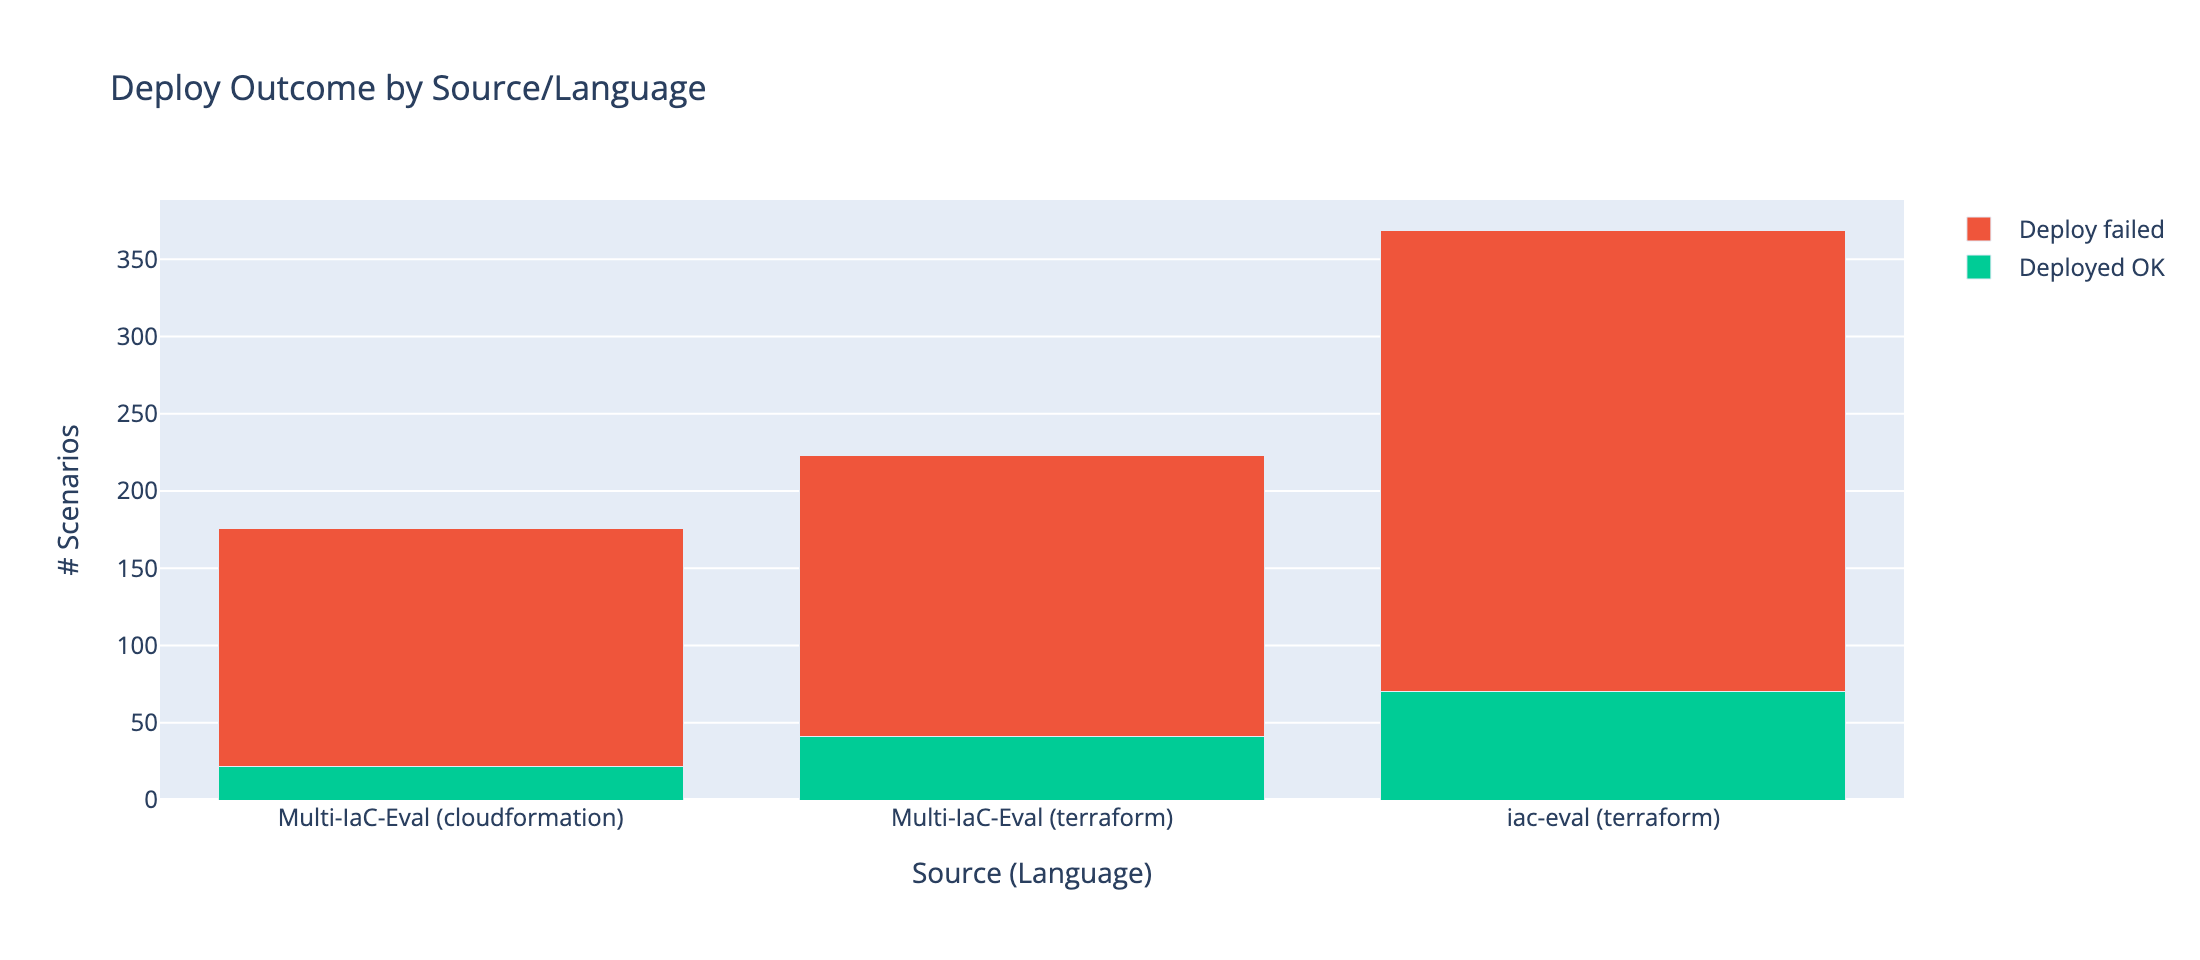

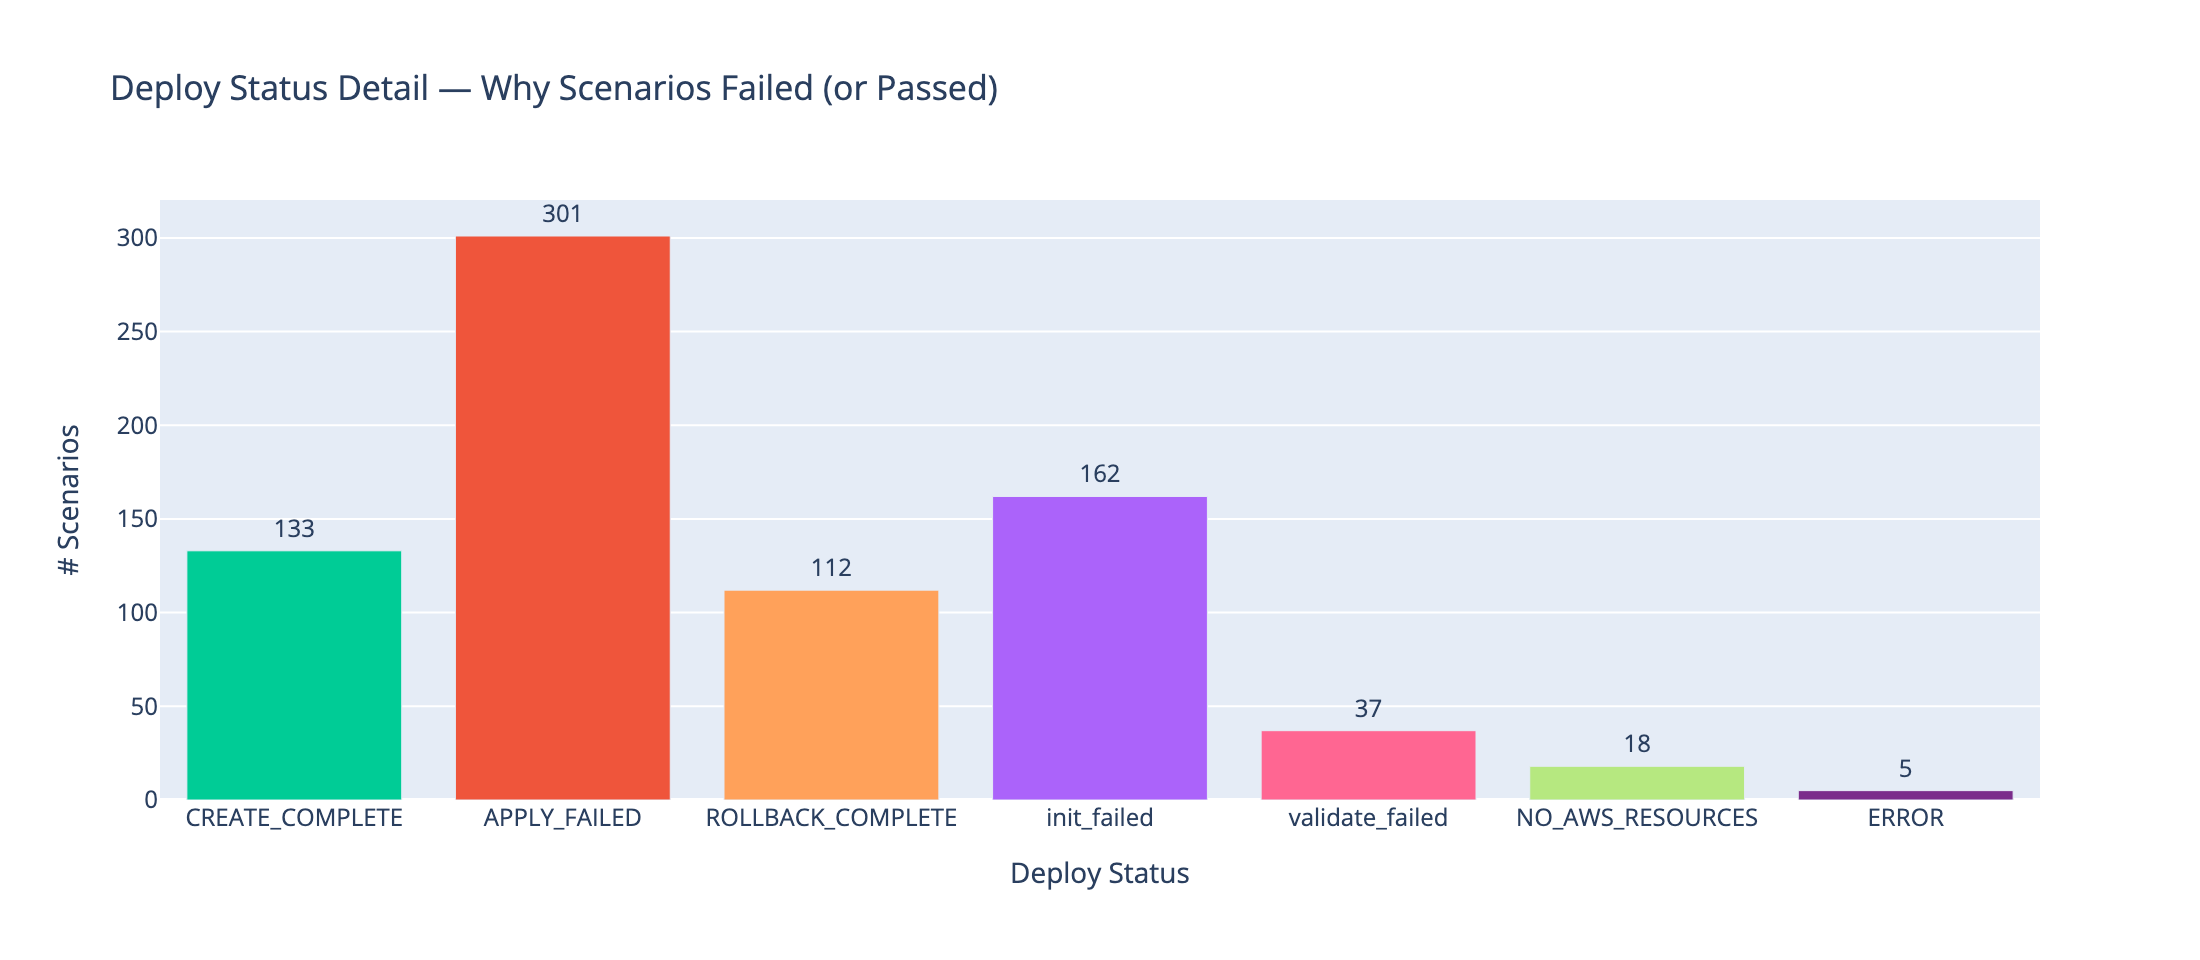

In [43]:
if _DEPLOY_CACHE_PATH.exists() and len(pd.read_csv(_DEPLOY_CACHE_PATH)) > 0:
    dc_full = df_unified[['scenario_id', 'source', 'language']].merge(
        pd.read_csv(_DEPLOY_CACHE_PATH), on='scenario_id', how='left',
    )

    def _outcome(row):
        if pd.isna(row['deploy_pass']):
            return 'Not yet tested'
        return 'Deployed OK' if row['deploy_pass'] else 'Deploy failed'

    dc_full['outcome'] = dc_full.apply(_outcome, axis=1)
    outcome_counts = (
        dc_full.groupby(['source', 'language', 'outcome']).size()
        .reset_index(name='count')
    )
    outcome_counts['label'] = outcome_counts.apply(lambda r: f"{r['source'].split('/')[-1]} ({r['language']})", axis=1)

    fig_outcome = go.Figure()
    outcome_colors = {'Deployed OK': '#00CC96', 'Deploy failed': '#EF553B', 'Not yet tested': '#AAAAAA'}
    for outcome_name in ['Deployed OK', 'Deploy failed', 'Not yet tested']:
        sub = outcome_counts[outcome_counts['outcome'] == outcome_name]
        fig_outcome.add_trace(go.Bar(
            name=outcome_name, x=sub['label'], y=sub['count'], marker_color=outcome_colors[outcome_name],
        ))
    fig_outcome.update_layout(
        barmode='stack', title='Deploy Outcome by Source/Language',
        xaxis_title='Source (Language)', yaxis_title='# Scenarios', height=480,
    )
    fig_outcome.show()

    status_counts = dc_full['deploy_status'].value_counts(dropna=False).reset_index()
    status_counts.columns = ['deploy_status', 'count']
    status_counts['deploy_status'] = status_counts['deploy_status'].fillna('(not yet tested)')
    status_order = ['CREATE_COMPLETE', 'APPLY_FAILED', 'ROLLBACK_COMPLETE', 'init_failed',
                     'validate_failed', 'NO_AWS_RESOURCES', 'ERROR', 'APPLY_TIMEOUT', '(not yet tested)']
    status_counts['deploy_status'] = pd.Categorical(
        status_counts['deploy_status'],
        categories=[s for s in status_order if s in status_counts['deploy_status'].values]
                    + [s for s in status_counts['deploy_status'].unique() if s not in status_order],
        ordered=True,
    )
    status_counts = status_counts.sort_values('deploy_status')
    status_color_map = {
        'CREATE_COMPLETE': '#00CC96', 'APPLY_FAILED': '#EF553B', 'ROLLBACK_COMPLETE': '#FFA15A',
        'init_failed': '#AB63FA', 'validate_failed': '#FF6692', 'NO_AWS_RESOURCES': '#B6E880',
        'ERROR': '#7B2D8B', 'APPLY_TIMEOUT': '#FECB52', '(not yet tested)': '#AAAAAA',
    }
    fig_status = go.Figure(go.Bar(
        x=status_counts['deploy_status'].astype(str), y=status_counts['count'],
        marker_color=[status_color_map.get(s, '#636EFA') for s in status_counts['deploy_status'].astype(str)],
        text=status_counts['count'], textposition='outside',
    ))
    fig_status.update_layout(
        title='Deploy Status Detail — Why Scenarios Failed (or Passed)',
        xaxis_title='Deploy Status', yaxis_title='# Scenarios', height=480,
    )
    fig_status.show()
else:
    print("(no deploy cache yet — nothing to chart)")

## Multi-IaC-Eval — dedicated charts

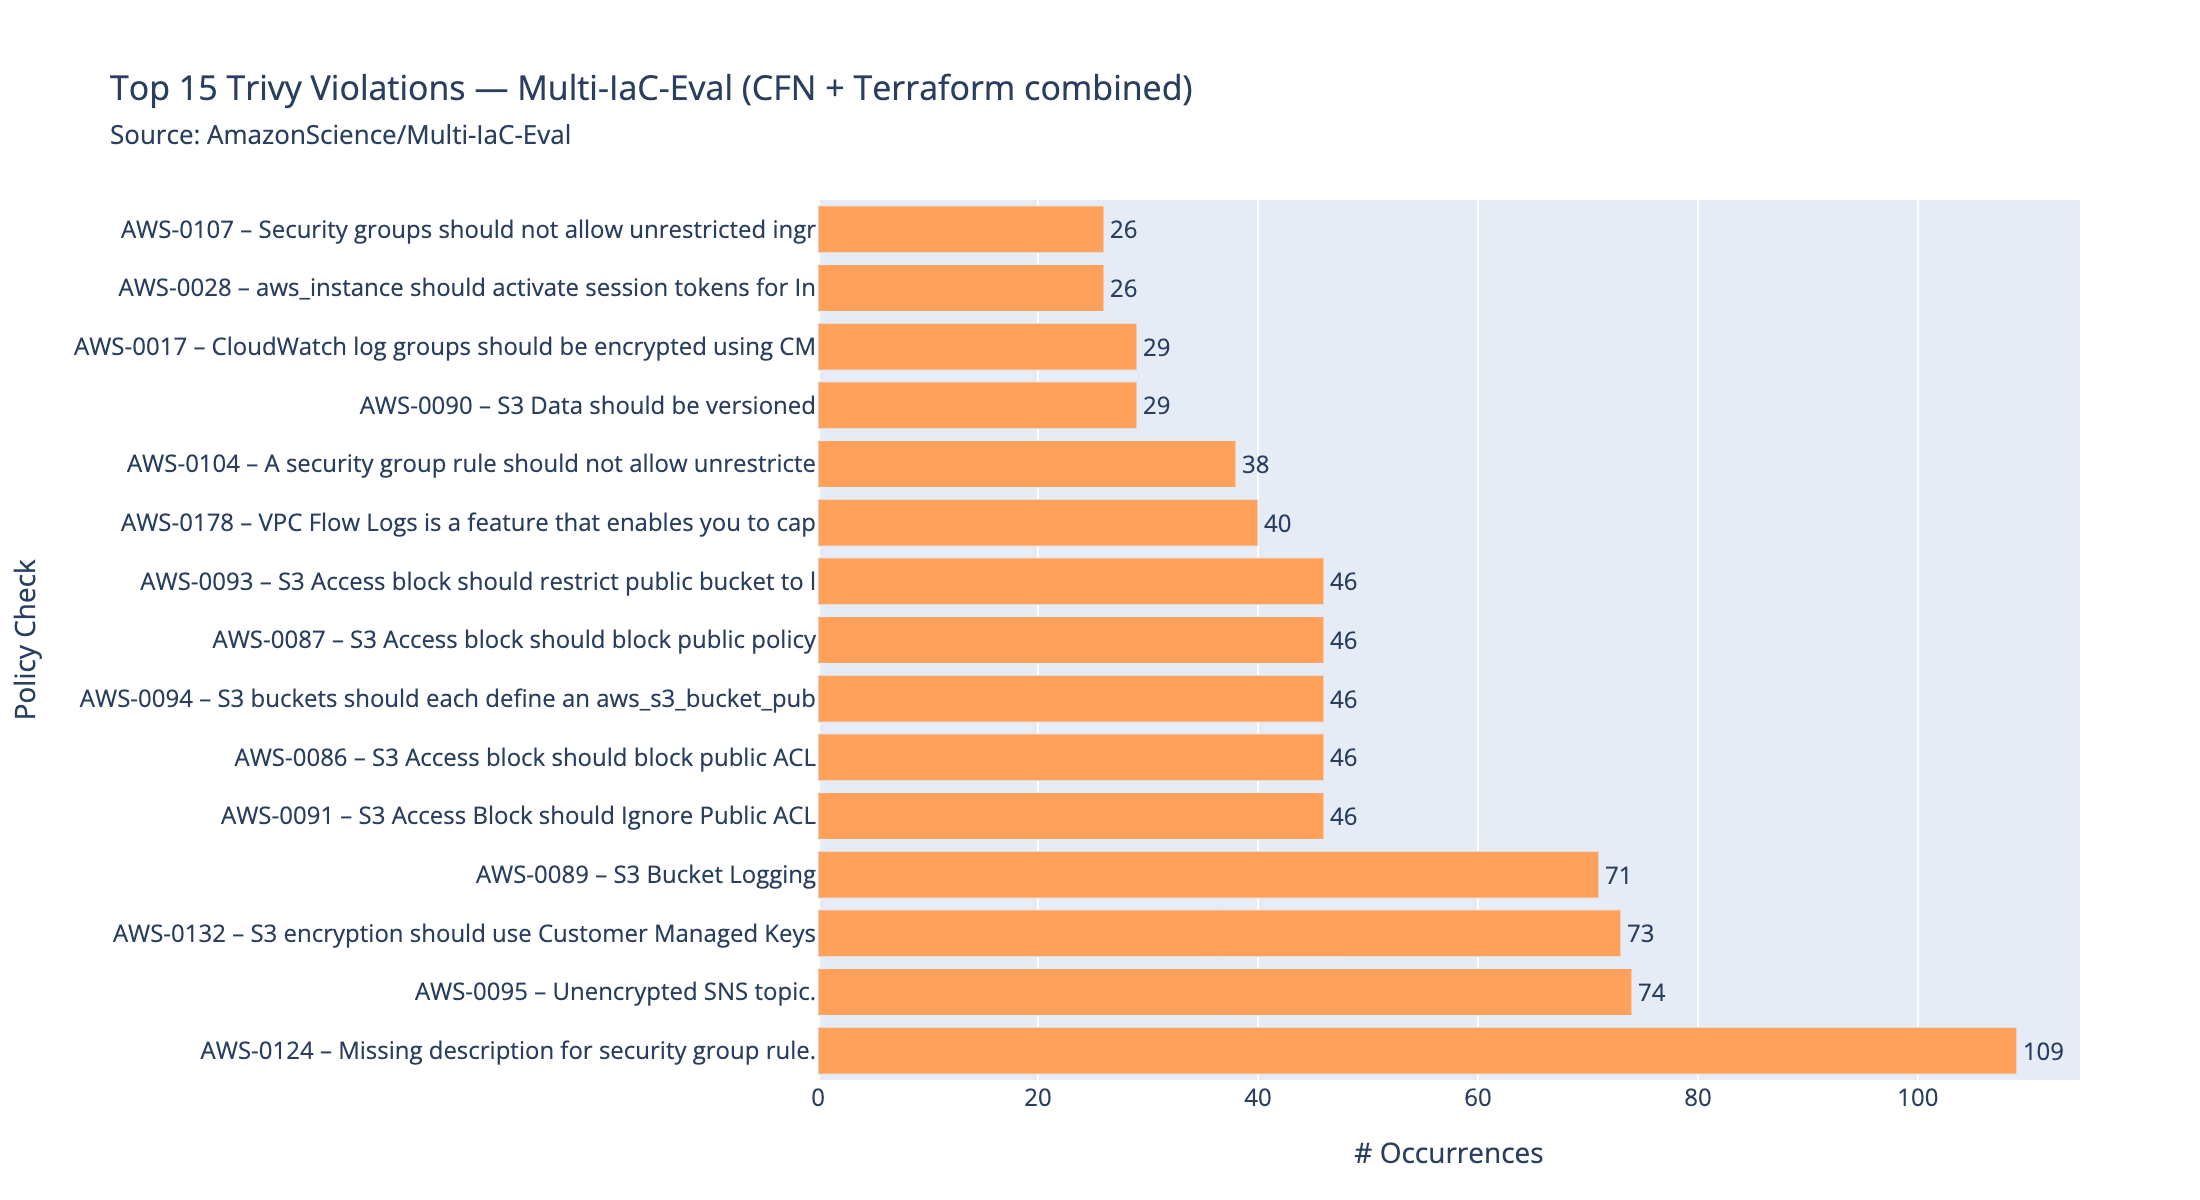

In [44]:
multi_mask = df_unified['source'] == MULTI_IAC_EVAL_SOURCE
multi_trivy = df_unified.loc[multi_mask, ['scenario_id', 'language']].merge(
    df_trivy_all[['scenario_id', 'violations']], on='scenario_id', how='left',
)

_multi_viol_rows = []
for _, row in multi_trivy.iterrows():
    for v in (row['violations'] or []):
        _multi_viol_rows.append({'check_id': v.get('check_id', ''), 'check_title': v.get('check_title', ''),
                                  'language': row['language']})
df_multi_viol = pd.DataFrame(_multi_viol_rows)

if df_multi_viol.empty:
    print("No Trivy violations recorded for Multi-IaC-Eval (nothing to chart).")
else:
    top_multi = (
        df_multi_viol.groupby(['check_id', 'check_title']).size().reset_index(name='count')
        .sort_values('count', ascending=False).head(15)
    )
    top_multi['label'] = top_multi.apply(lambda r: f"{r['check_id']} – {str(r['check_title'])[:50]}", axis=1)

    fig_multi_top = go.Figure(go.Bar(
        x=top_multi['count'], y=top_multi['label'], orientation='h',
        text=top_multi['count'], textposition='outside', cliponaxis=False,
        marker_color='#FFA15A',
    ))
    fig_multi_top.update_layout(
        title="Top 15 Trivy Violations — Multi-IaC-Eval (CFN + Terraform combined)<br>"
              "<span style='font-size:13px;font-weight:normal;'>Source: AmazonScience/Multi-IaC-Eval</span>",
        xaxis_title='# Occurrences', yaxis_title='Policy Check',
        margin=dict(l=380, r=60, t=100, b=60), height=600,
    )
    fig_multi_top.show()

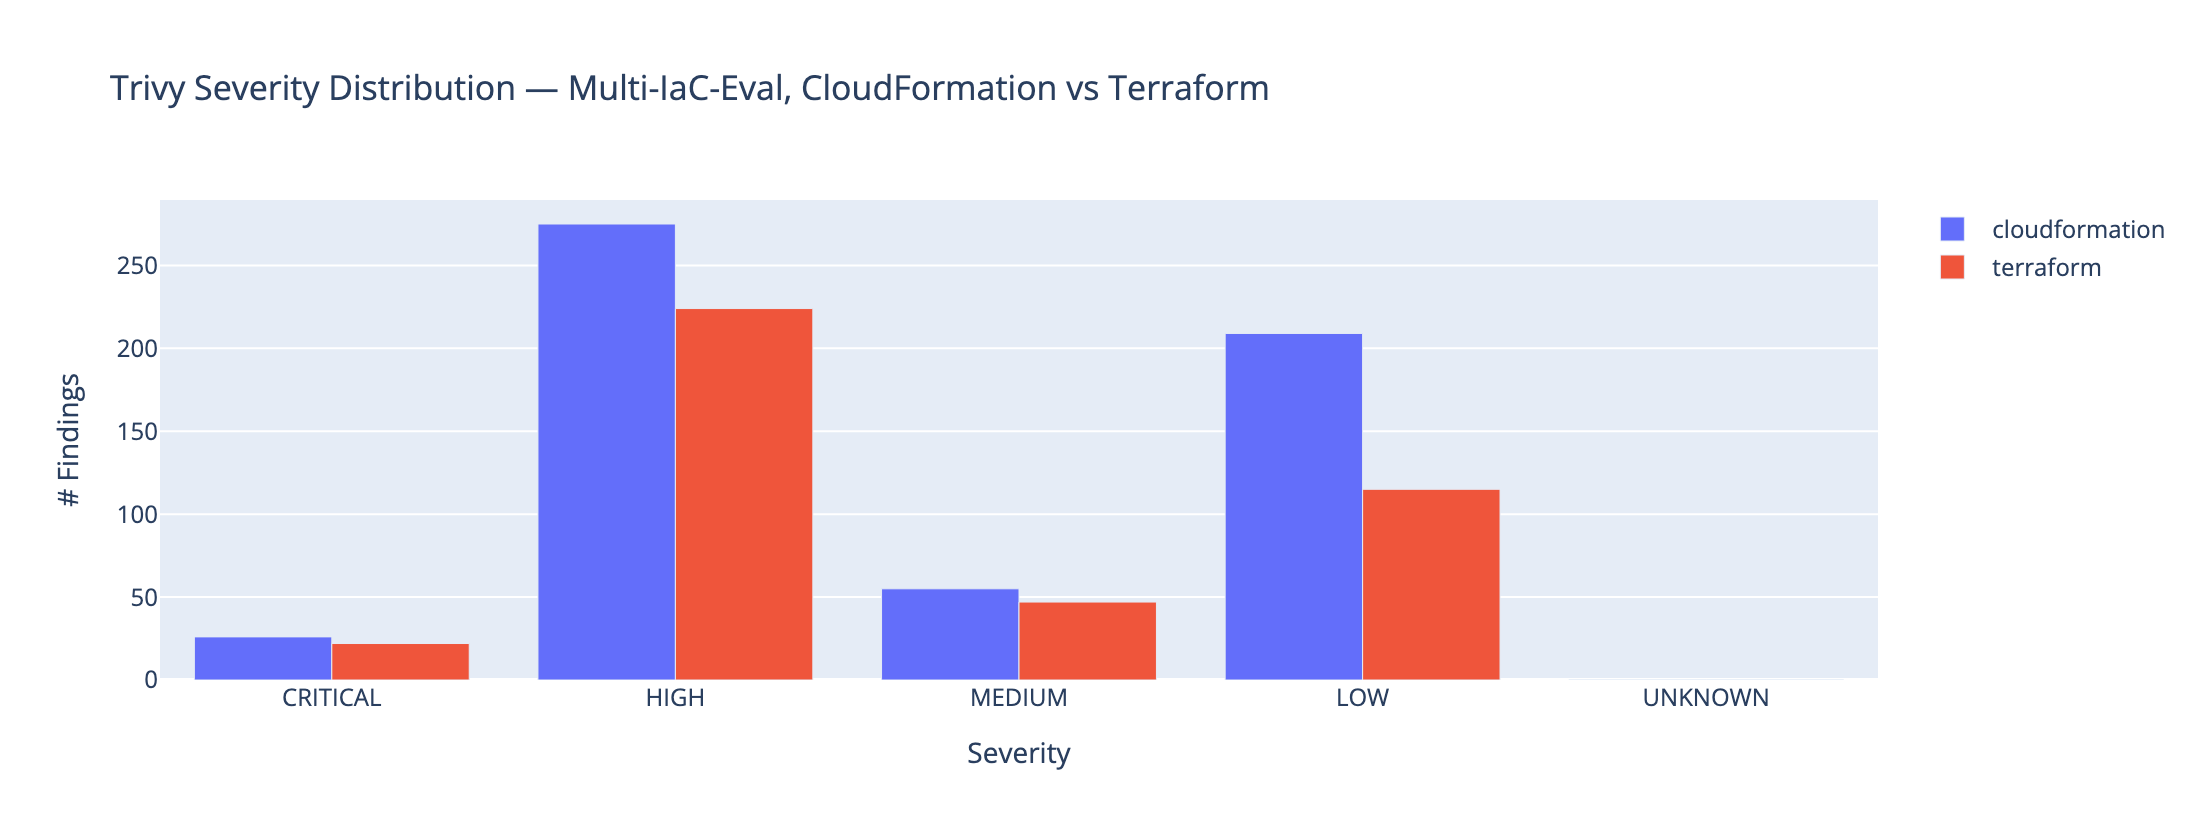

Checkov fully-compliant %, Multi-IaC-Eval by language:
language
cloudformation    13.6
terraform          9.4


In [45]:
TRIVY_SEVERITY_COLS = ['severity_critical', 'severity_high', 'severity_medium', 'severity_low', 'severity_unknown']
multi_trivy_full = df_unified.loc[multi_mask, ['scenario_id', 'language']].merge(
    df_trivy_all[TRIVY_SEVERITY_COLS + ['scenario_id']], on='scenario_id', how='left',
)
multi_sev_by_lang = multi_trivy_full.groupby('language')[TRIVY_SEVERITY_COLS].sum()

fig_multi_sev = go.Figure()
for lang in multi_sev_by_lang.index:
    fig_multi_sev.add_trace(go.Bar(
        name=lang,
        x=[s.replace('severity_', '').upper() for s in TRIVY_SEVERITY_COLS],
        y=multi_sev_by_lang.loc[lang].values,
    ))
fig_multi_sev.update_layout(
    title='Trivy Severity Distribution — Multi-IaC-Eval, CloudFormation vs Terraform',
    barmode='group', xaxis_title='Severity', yaxis_title='# Findings', height=420,
)
fig_multi_sev.show()

multi_checkov = df_unified.loc[multi_mask, ['scenario_id', 'language']].merge(
    df_checkov_all[['scenario_id', 'filtered_compliance']], on='scenario_id', how='left',
)
multi_compliance = multi_checkov.groupby('language')['filtered_compliance'].mean().mul(100).round(1)
print("Checkov fully-compliant %, Multi-IaC-Eval by language:")
print(multi_compliance.to_string())